# Segmentation de clientèle bancaire par apprentissage non supervisé — projet complet

**Projet final « Apprentissage non supervisé » — Master BDA/IA**  
Ndeye Sokhna Nokho

Ce notebook rassemble, dans l'ordre, les huit notebooks du projet. Les livrables exigés par le sujet restent les notebooks séparés (`01_preparation.ipynb` à `04_validation.ipynb`) ; cette version permet de parcourir toutes les étapes d'un seul tenant.

| Partie | Contenu | Notebook d'origine |
|---|---|---|
| 1 | Jour 1 — Préparation et exploration des données | `01_preparation.ipynb` |
| 2 | Jour 2 — Dissimilarités et partitionnement | `02_partitionnement.ipynb` |
| 3 | Jour 3 — Clustering hiérarchique et par densité | `03_hierarchique_densite.ipynb` |
| 4 | Jour 4 — Validation des clusters | `04_validation.ipynb` |
| 5 | Jour 5 — Interprétation et recommandations | `05_interpretation.ipynb` |
| 6 | Extensions n° 1 et 3 — Clients atypiques, application Streamlit | `06_extensions.ipynb` |
| 7 | Extension n° 2 — Sélection de variables | `07_selection_variables.ipynb` |
| 8 | Extension n° 4 — Online Retail, segmentation RFM | `08_online_retail_rfm.ipynb` |

**Exécution** : *Run → Run All Cells* (5 à 10 minutes). Chaque partie relit les résultats enregistrés par les parties précédentes dans `outputs/`.

> **Règle du projet** : la variable `y` (souscription) n'est **jamais** utilisée pour construire les clusters. Elle ne sert que de vérité terrain pour les indices externes.

# Jour 1 — Préparation et exploration des données

**Objectif du jour (Chapitre 1)** : passer du fichier brut à des données prêtes pour le clustering.

| Étape | Contenu |
|---|---|
| 1 | Chargement et description de la matrice de données, types de variables |
| 2 | Nettoyage : `unknown`, doublons, valeurs aberrantes |
| 3 | Analyse exploratoire (EDA) |
| 4 | Choix des variables actives / illustratives |
| 5 | Deux représentations : (a) one-hot + standardisation, (b) données mixtes |
| 6 | Échantillon stratifié de 4 000 clients |
| 7 | Réduction de dimension : PCA, t-SNE, UMAP |

> **Règle du projet** : la variable `y` (souscription) n'est **jamais** utilisée pour construire les clusters. Elle ne sert que de vérité terrain au Jour 4.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")            # pour importer le dossier src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

from src.config import SEED, N_SAMPLE, DATA_PATH, FIG, TAB, OUT
from src import preprocessing as pp

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

## 1. Chargement et description de la matrice de données

In [3]:
df_raw = pp.load_raw(DATA_PATH)
print(f"Matrice de données : {df_raw.shape[0]} individus (clients) x {df_raw.shape[1]} variables")
df_raw.head()

Matrice de données : 41188 individus (clients) x 21 variables


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Chaque **ligne** est un contact téléphonique avec un client, chaque **colonne** une variable : 20 variables descriptives + la cible `y`.

### Types de variables
Le type statistique d'une variable détermine la distance qu'on a le droit d'utiliser dessus (Chapitre 2). On les classe donc soigneusement.

In [4]:
types = pd.DataFrame([
    ("age",            "quantitative discrète",  "client",    "âge en années"),
    ("job",            "qualitative nominale",   "client",    "profession (12 modalités)"),
    ("marital",        "qualitative nominale",   "client",    "statut marital"),
    ("education",      "qualitative ordinale",   "client",    "niveau d'études"),
    ("default",        "binaire (+ unknown)",    "client",    "crédit en défaut ?"),
    ("housing",        "binaire",                "client",    "prêt immobilier ?"),
    ("loan",           "binaire",                "client",    "prêt personnel ?"),
    ("contact",        "binaire",                "campagne",  "canal : cellular / telephone"),
    ("month",          "qualitative ordinale",   "campagne",  "mois du dernier contact"),
    ("day_of_week",    "qualitative ordinale",   "campagne",  "jour du dernier contact"),
    ("duration",       "quantitative continue",  "campagne",  "durée du dernier appel (s)"),
    ("campaign",       "quantitative discrète",  "campagne",  "nb de contacts pendant cette campagne"),
    ("pdays",          "quantitative discrète",  "historique","jours depuis le dernier contact (999 = jamais)"),
    ("previous",       "quantitative discrète",  "historique","nb de contacts avant cette campagne"),
    ("poutcome",       "qualitative nominale",   "historique","résultat de la campagne précédente"),
    ("emp.var.rate",   "quantitative continue",  "contexte",  "taux de variation de l'emploi"),
    ("cons.price.idx", "quantitative continue",  "contexte",  "indice des prix à la consommation"),
    ("cons.conf.idx",  "quantitative continue",  "contexte",  "indice de confiance des ménages"),
    ("euribor3m",      "quantitative continue",  "contexte",  "taux Euribor 3 mois"),
    ("nr.employed",    "quantitative continue",  "contexte",  "nombre d'employés (milliers)"),
    ("y",              "binaire",                "cible",     "souscription au dépôt à terme (vérité terrain)"),
], columns=["variable", "type statistique", "famille", "description"])
types["nb valeurs distinctes"] = [df_raw[v].nunique() for v in types["variable"]]
types.to_csv(TAB / "01_types_variables.csv", index=False)
types

,variable,type statistique,famille,description,nb valeurs distinctes
0,age,quantitative discrète,client,âge en années,78
1,job,qualitative nominale,client,profession (12 modalités),12
2,marital,qualitative nominale,client,statut marital,4
3,education,qualitative ordinale,client,niveau d'études,8
4,default,binaire (+ unknown),client,crédit en défaut ?,3
5,housing,binaire,client,prêt immobilier ?,3
6,loan,binaire,client,prêt personnel ?,3
7,contact,binaire,campagne,canal : cellular / telephone,2
8,month,qualitative ordinale,campagne,mois du dernier contact,10
9,day_of_week,qualitative ordinale,campagne,jour du dernier contact,5


Les données sont donc **mixtes** : 10 variables numériques et 10 catégorielles. C'est ce qui justifie, plus loin, l'usage de la distance de Gower et de K-prototypes.

## 2. Nettoyage
### 2.1 Valeurs manquantes
Il n'y a aucun `NaN` : les valeurs manquantes sont codées par la modalité `unknown`.

In [5]:
print("NaN dans le fichier :", int(df_raw.isna().sum().sum()))
unk = (df_raw == "unknown").sum()
unk = unk[unk > 0].to_frame("nb unknown")
unk["% des clients"] = (100 * unk["nb unknown"] / len(df_raw)).round(2)
unk.sort_values("nb unknown", ascending=False)

NaN dans le fichier : 0


,nb unknown,% des clients
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


**Décision :**
- `job`, `marital`, `education`, `housing`, `loan` (moins de 5 % de `unknown`) → imputation par le **mode** ; l'information perdue est négligeable et on évite de créer des modalités « fantômes ».
- `default` (≈ 21 % de `unknown`) → on **garde `unknown` comme modalité**. Une telle proportion n'est pas un accident : ne pas connaître la situation de défaut d'un client est une information en soi. De plus `default = yes` ne concerne que 3 clients.

### 2.2 Doublons

In [6]:
print("Lignes strictement dupliquées :", int(df_raw.duplicated().sum()))

Lignes strictement dupliquées : 12


### 2.3 Valeurs aberrantes
Règle de Tukey : une valeur est suspecte si elle sort de $[Q_1 - 1{,}5\,IQR \; ; \; Q_3 + 1{,}5\,IQR]$.

In [7]:
num_raw = df_raw.select_dtypes("number")
q1, q3 = num_raw.quantile(0.25), num_raw.quantile(0.75)
iqr = q3 - q1
outliers = ((num_raw < q1 - 1.5 * iqr) | (num_raw > q3 + 1.5 * iqr)).sum()
pd.DataFrame({"min": num_raw.min(), "Q1": q1, "médiane": num_raw.median(), "Q3": q3,
              "max": num_raw.max(), "nb hors bornes": outliers,
              "%": (100 * outliers / len(df_raw)).round(2)})

,min,Q1,médiane,Q3,max,nb hors bornes,%
age,17.000,32.000,38.000,47.000,98.000,469,1.14
duration,0.000,102.000,180.000,319.000,4918.000,2963,7.19
campaign,1.000,1.000,2.000,3.000,56.000,2406,5.84
pdays,0.000,999.000,999.000,999.000,999.000,1515,3.68
previous,0.000,0.000,0.000,0.000,7.000,5625,13.66
emp.var.rate,-3.400,-1.800,1.100,1.400,1.400,0,0.00
cons.price.idx,92.201,93.075,93.749,93.994,94.767,0,0.00
cons.conf.idx,-50.800,-42.700,-41.800,-36.400,-26.900,447,1.09
euribor3m,0.634,1.344,4.857,4.961,5.045,0,0.00
nr.employed,4963.600,5099.100,5191.000,5228.100,5228.100,0,0.00


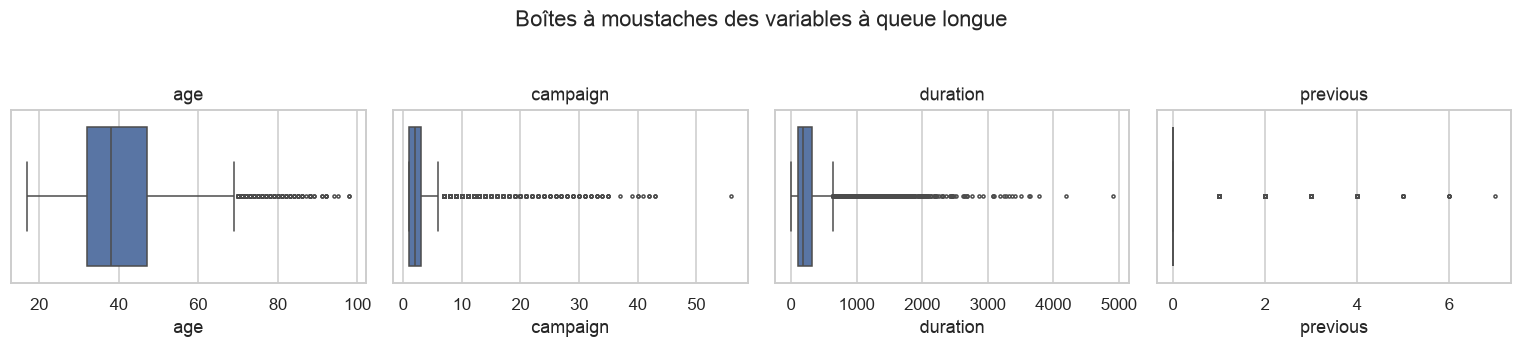

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, ["age", "campaign", "duration", "previous"]):
    sns.boxplot(x=df_raw[col], ax=ax, color="#4C72B0", fliersize=2)
    ax.set_title(col)
plt.suptitle("Boîtes à moustaches des variables à queue longue", y=1.05)
plt.tight_layout(); plt.savefig(FIG / "01_boxplots.png", bbox_inches="tight"); plt.show()

**Lecture et décisions :**
- `age` : les valeurs élevées (jusqu'à 98 ans) sont de **vrais clients seniors**, pas des erreurs → on les garde telles quelles.
- `campaign` : queue très longue (jusqu'à 56 appels). K-means étant sensible aux valeurs extrêmes, on **plafonne au 99ᵉ centile** (winsorisation) plutôt que de supprimer des clients.
- `pdays` : la valeur 999 n'est pas une durée mais un **code** (« jamais recontacté », 96 % des cas). On la remplace par un indicateur binaire `contacted_before`.
- `previous` : presque toujours 0 ; les valeurs non nulles sont informatives, on les garde.

Toutes ces règles sont codées dans `src/preprocessing.py` → fonction `clean()` (réutilisable).

In [9]:
df = pp.clean(df_raw, verbose=True)

n_initial                       : 41188
doublons_supprimes              : 12
unknown_job                     : 330 -> mode 'admin.'
unknown_marital                 : 80 -> mode 'married'
unknown_education               : 1730 -> mode 'university.degree'
unknown_housing                 : 990 -> mode 'yes'
unknown_loan                    : 990 -> mode 'no'
unknown_default                 : 8596 conservés (modalité)
campaign_plafond_p99            : 14.0
campaign_valeurs_plafonnees     : 406
n_final                         : 41176


## 3. Analyse exploratoire (EDA)
### 3.1 Statistiques descriptives

In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41176.0,258.32,259.31,0.00,102.00,180.00,319.00,4918.00
campaign,41176.0,2.50,2.30,1.00,1.00,2.00,3.00,14.00
pdays,41176.0,962.46,186.94,0.00,999.00,999.00,999.00,999.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [11]:
df.describe(include="object").T

,count,unique,top,freq
job,41176,11,admin.,10749
marital,41176,3,married,25001
education,41176,7,university.degree,13894
default,41176,3,no,32577
housing,41176,2,yes,22561
loan,41176,2,no,34928
contact,41176,2,cellular,26135
month,41176,10,may,13767
day_of_week,41176,5,thu,8618
poutcome,41176,3,nonexistent,35551


### 3.2 Distributions des variables numériques

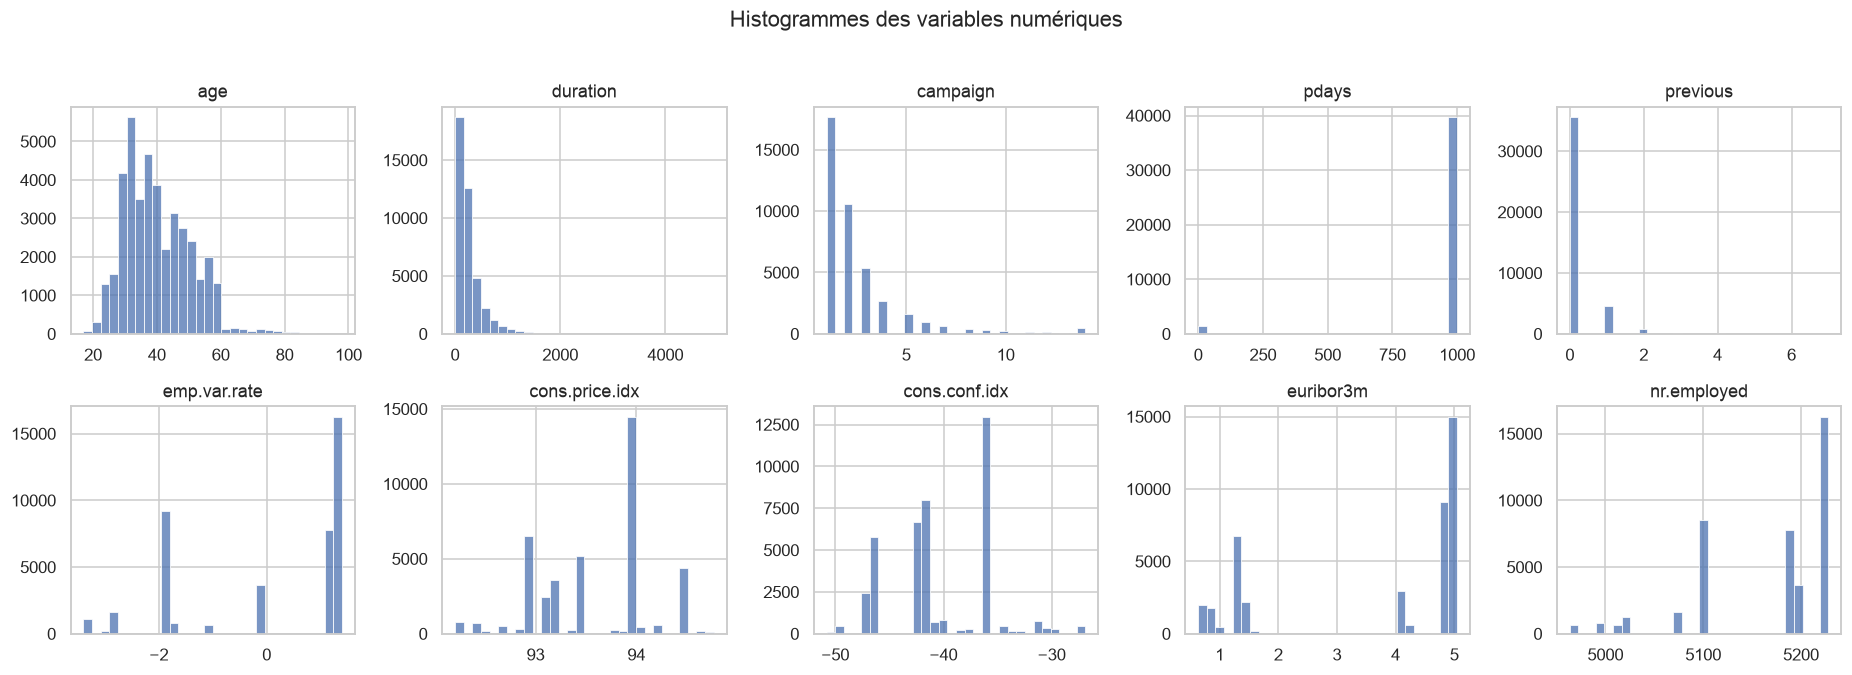

In [12]:
num_cols = df.select_dtypes("number").columns
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Histogrammes des variables numériques", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "01_histogrammes.png", bbox_inches="tight"); plt.show()

- `age` : distribution étalée à droite, centrée autour de 38 ans.
- `campaign`, `previous`, `duration` : très asymétriques (beaucoup de petites valeurs).
- Indicateurs économiques : **multimodaux**. Ils ne prennent qu'un petit nombre de valeurs (une par période), ce qui annonce déjà des groupes liés au contexte économique.

### 3.3 Répartition des variables catégorielles

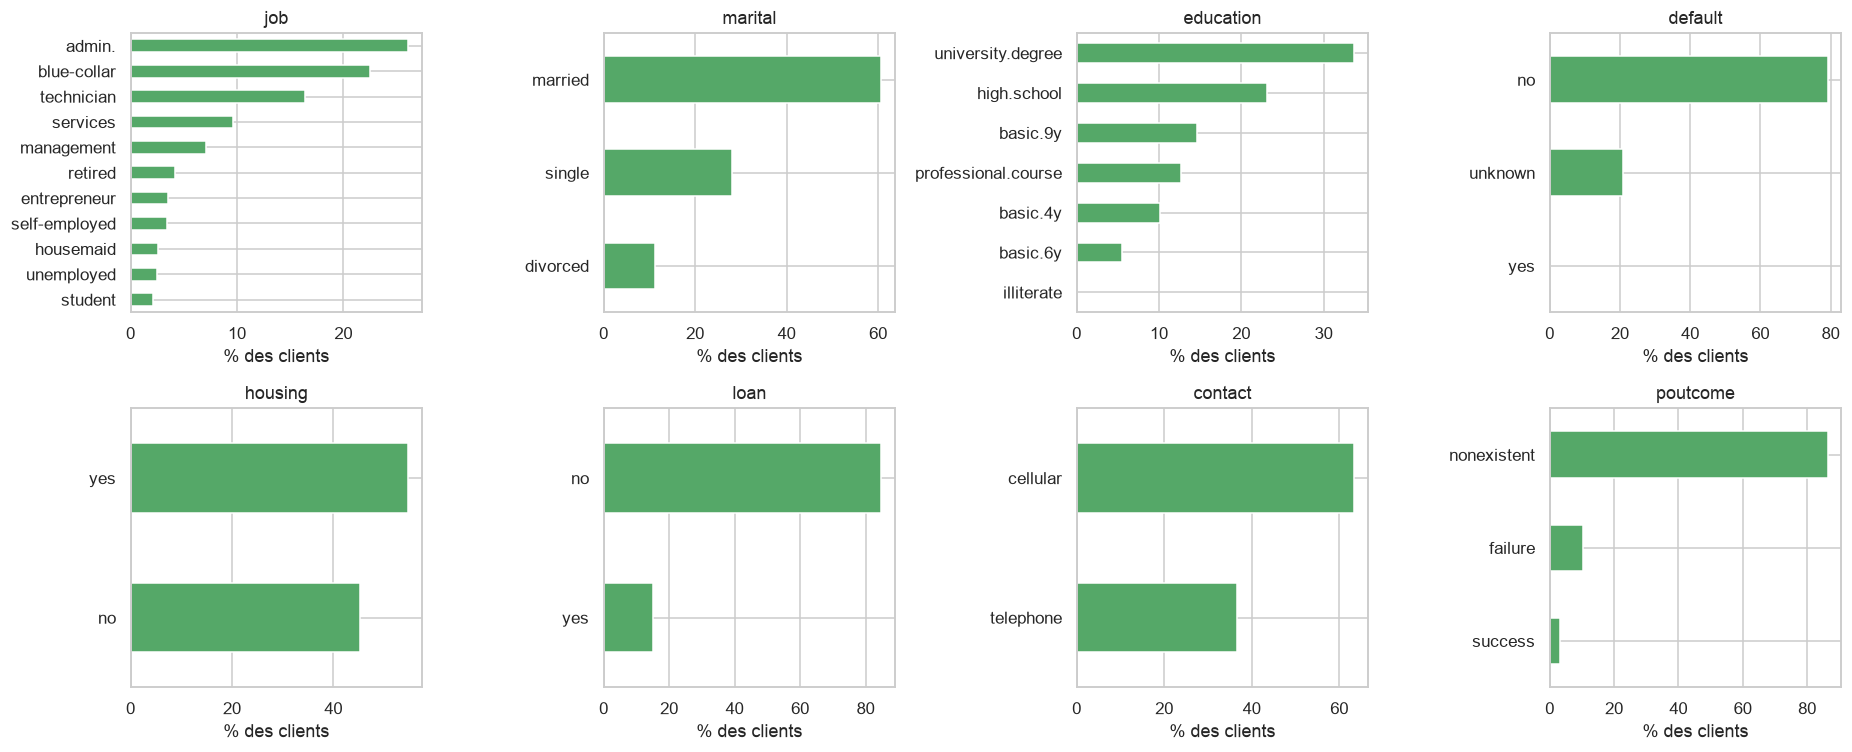

In [13]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    (df[col].value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax, color="#55A868")
    ax.set_title(col); ax.set_xlabel("% des clients"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "01_categorielles.png", bbox_inches="tight"); plt.show()

Les variables binaires rares (`loan = yes`, `poutcome = success`, `contacted_before = yes`) sont **asymétriques** : partager un « oui » est beaucoup plus informatif que partager un « non ». Ce point guidera le choix Hamming / Jaccard au Jour 2.

### 3.4 Corrélations

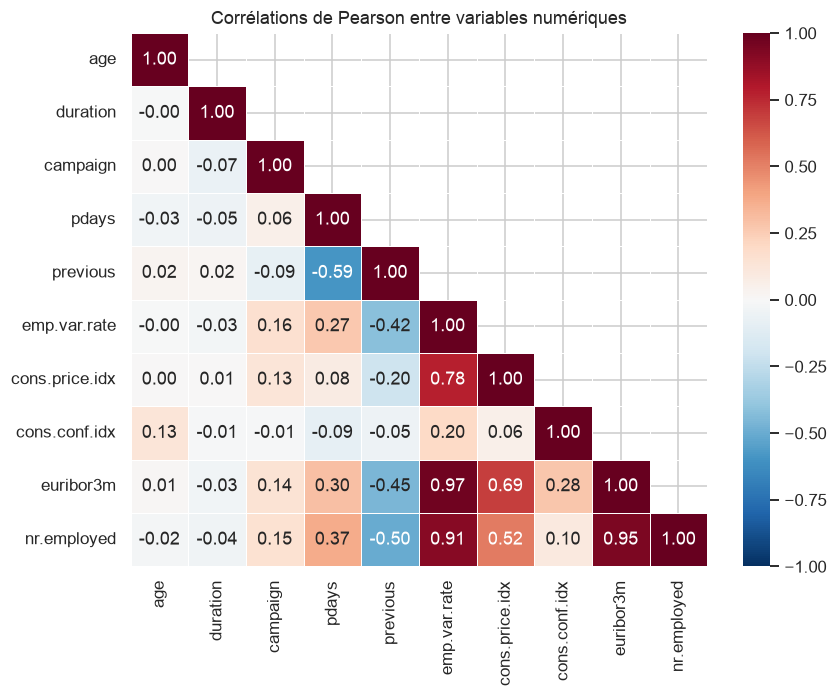

In [14]:
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), linewidths=.5)
plt.title("Corrélations de Pearson entre variables numériques")
plt.tight_layout(); plt.savefig(FIG / "01_correlations.png", bbox_inches="tight"); plt.show()

**Constat majeur** : `emp.var.rate`, `euribor3m` et `nr.employed` sont corrélées à plus de 0,90. Elles mesurent la même chose (la conjoncture). Les garder toutes les trois reviendrait à **compter trois fois** la même information dans les distances.

### 3.5 Nuages de points

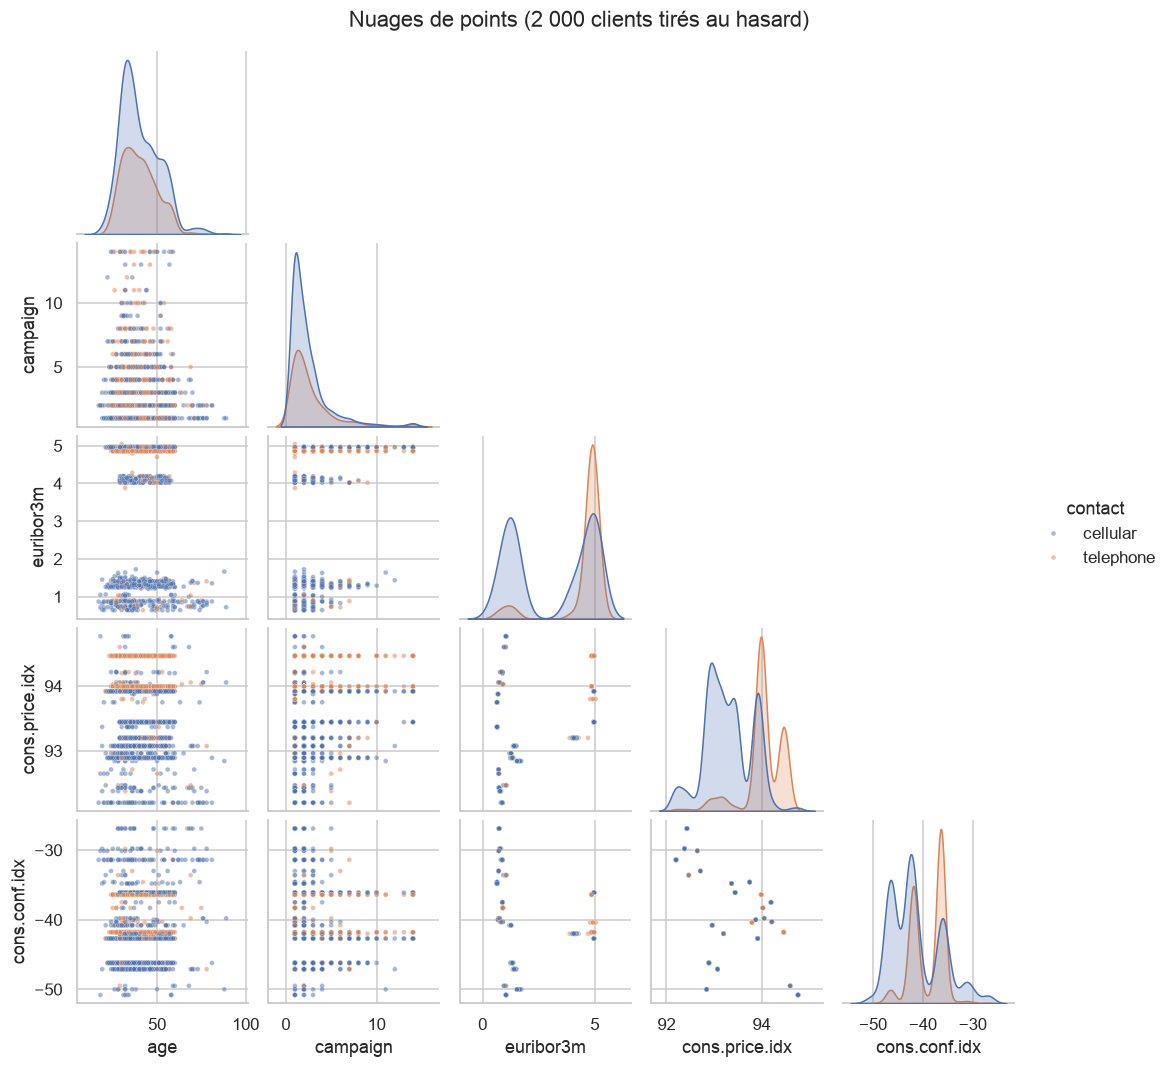

In [15]:
pair_cols = ["age", "campaign", "euribor3m", "cons.price.idx", "cons.conf.idx"]
g = sns.pairplot(df.sample(2000, random_state=SEED)[pair_cols + ["contact"]], hue="contact",
                 plot_kws={"s": 10, "alpha": .5}, height=1.9, corner=True)
g.fig.suptitle("Nuages de points (2 000 clients tirés au hasard)", y=1.02)
plt.savefig(FIG / "01_pairplot.png", bbox_inches="tight"); plt.show()

Les nuages mêlant deux indicateurs économiques forment des **paquets isolés** : chaque paquet correspond à une période de la campagne. Le canal de contact (`telephone` / `cellular`) est lui aussi lié à la période. Les variables socio-démographiques (âge…) ne montrent en revanche aucun groupe évident à l'œil nu.

## 4. Variables actives et variables illustratives

Toutes les variables ne doivent pas servir à **construire** les groupes. On distingue :
- les variables **actives**, utilisées par les algorithmes ;
- les variables **illustratives**, écartées du calcul mais gardées pour **décrire** les segments au Jour 5.

| Variable écartée | Raison |
|---|---|
| `duration` | Connue seulement **après** l'appel : inutilisable pour cibler une campagne à l'avance. Elle est de plus quasi déterministe de `y` (un appel de 0 s donne toujours `no`), ce qui ferait entrer la cible par la fenêtre. |
| `emp.var.rate`, `nr.employed` | Redondantes avec `euribor3m` (corrélation > 0,90). On garde un seul représentant. |
| `pdays` | Remplacée par l'indicateur `contacted_before`. |
| `month`, `day_of_week` | Décrivent le **calendrier de la campagne**, pas le client ; `month` est en outre un doublon du contexte économique. |
| `y` | Vérité terrain, interdite à l'entraînement. |

Il reste **15 variables actives** : 6 numériques et 9 catégorielles.

In [16]:
print("Numériques actives   :", pp.ACTIVE_NUM)
print("Catégorielles actives:", pp.ACTIVE_CAT)
print("Illustratives        :", pp.ILLUSTRATIVE)
X_mixed_full, illus_full, y_full = pp.split_roles(df)

Numériques actives   : ['age', 'campaign', 'previous', 'cons.price.idx', 'cons.conf.idx', 'euribor3m']
Catégorielles actives: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'contacted_before']
Illustratives        : ['duration', 'month', 'day_of_week', 'pdays', 'emp.var.rate', 'nr.employed']


## 5. Les deux représentations des données
### (a) One-hot + standardisation
- Variables catégorielles → indicatrices 0/1 (*one-hot*).
- Variables numériques → centrées-réduites : $z = \dfrac{x - \mu}{\sigma}$, pour que l'âge (dizaines) ne pèse pas plus que l'Euribor (unités).

Cette représentation est destinée aux méthodes **euclidiennes** : K-means, GMM, Ward, DBSCAN, PCA.

In [17]:
X_a_full, prep = pp.encode(X_mixed_full)
print("Représentation (a) :", X_a_full.shape)
check = X_a_full[pp.ACTIVE_NUM].agg(["mean", "std"]).T.round(3)
print("\nVérification de la standardisation (moyenne ≈ 0, écart-type ≈ 1) :")
print(check)
X_a_full.head(3)

Représentation (a) : (41176, 37)

Vérification de la standardisation (moyenne ≈ 0, écart-type ≈ 1) :
                mean  std
age              0.0  1.0
campaign         0.0  1.0
previous         0.0  1.0
cons.price.idx   0.0  1.0
cons.conf.idx   -0.0  1.0
euribor3m       -0.0  1.0


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,default_no,default_unknown,default_yes,housing_yes,loan_yes,contact_telephone,poutcome_failure,poutcome_nonexistent,poutcome_success,contacted_before_yes
0,1.533143,-0.651907,-0.349551,0.722628,0.886568,0.712463,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,1.629107,-0.651907,-0.349551,0.722628,0.886568,0.712463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.290177,-0.651907,-0.349551,0.722628,0.886568,0.712463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


### (b) Données mixtes brutes
On garde les variables dans leur nature d'origine (nombres et chaînes). Cette représentation est destinée à la **distance de Gower** (K-medoids, CAH) et à **K-prototypes**, qui traitent chaque variable selon son type.

In [18]:
X_mixed_full.head(3)

,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before
0,56,1,0,93.994,-36.4,4.857,housemaid,married,basic.4y,no,no,no,telephone,nonexistent,no
1,57,1,0,93.994,-36.4,4.857,services,married,high.school,unknown,no,no,telephone,nonexistent,no
2,37,1,0,93.994,-36.4,4.857,services,married,high.school,no,yes,no,telephone,nonexistent,no


## 6. Échantillon aléatoire stratifié
Les méthodes à matrice de distances stockent $n^2$ valeurs : avec 41 176 clients, cela ferait 1,7 milliard de distances. Comme le demande le sujet, on travaille donc sur un **échantillon de 4 000 clients**.

La stratification porte sur `y` pour garder le même taux de souscription que dans la population. `y` sert uniquement au tirage : aucun algorithme ne la voit.

In [19]:
d = pp.prepare_all()            # tout le pipeline en une ligne (fonction réutilisable)
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
print("Échantillon :", X_a.shape)
pd.DataFrame({"population": y_full.value_counts(normalize=True).round(4),
              "échantillon": y.value_counts(normalize=True).round(4)})

Échantillon : (4000, 37)


,population,échantillon
y,,
no,0.8873,0.8872
yes,0.1127,0.1128


In [20]:
cmp = pd.DataFrame({"population": X_mixed_full[pp.ACTIVE_NUM].mean(),
                    "échantillon": X_mixed[pp.ACTIVE_NUM].mean()}).round(3)
cmp["écart relatif (%)"] = (100 * (cmp["échantillon"] / cmp["population"] - 1)).round(2)
cmp

,population,échantillon,écart relatif (%)
age,40.024,40.190,0.41
campaign,2.500,2.438,-2.48
previous,0.173,0.181,4.62
cons.price.idx,93.576,93.560,-0.02
cons.conf.idx,-40.503,-40.491,-0.03
euribor3m,3.621,3.621,0.00


L'échantillon reproduit fidèlement la population (écarts de moyenne inférieurs à quelques pour cent) : il est **représentatif**.

## 7. Réduction de dimension
### 7.1 PCA (analyse en composantes principales)
La PCA cherche les axes orthogonaux qui conservent le plus de variance. Elle est ajustée sur la population complète, représentation (a).

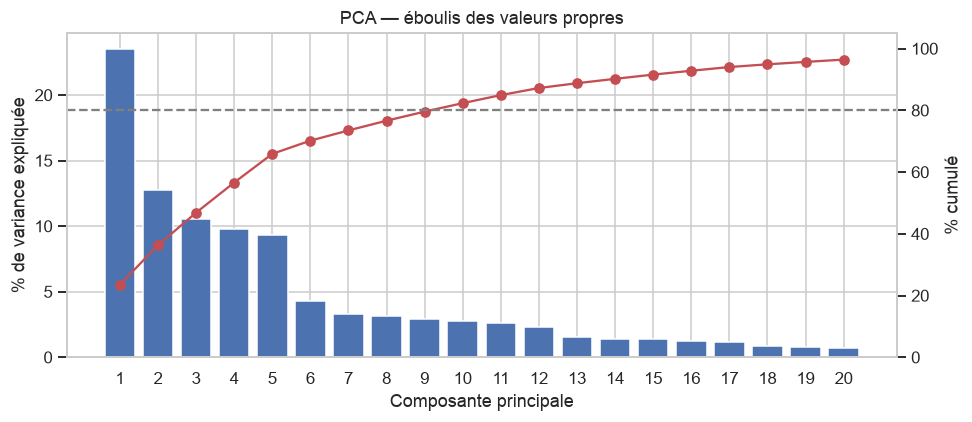

PC1 = 23.5%, PC2 = 12.8%  ->  plan principal = 36.3% de la variance
10 composantes pour atteindre 80 %, 14 pour 90 % (sur 37 colonnes)


In [21]:
pca = PCA(random_state=SEED).fit(X_a_full)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n80 = int(np.searchsorted(cum, 0.80) + 1)
n90 = int(np.searchsorted(cum, 0.90) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 21), evr[:20] * 100, color="#4C72B0", label="variance par composante")
ax2 = ax.twinx()
ax2.plot(range(1, 21), cum[:20] * 100, "o-", color="#C44E52", label="variance cumulée")
ax2.axhline(80, ls="--", color="grey"); ax2.set_ylim(0, 105); ax2.grid(False)
ax.set_xlabel("Composante principale"); ax.set_ylabel("% de variance expliquée"); ax2.set_ylabel("% cumulé")
ax.set_xticks(range(1, 21))
plt.title("PCA — éboulis des valeurs propres")
plt.tight_layout(); plt.savefig(FIG / "01_pca_variance.png", bbox_inches="tight"); plt.show()
print(f"PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}  ->  plan principal = {cum[1]:.1%} de la variance")
print(f"{n80} composantes pour atteindre 80 %, {n90} pour 90 % (sur {X_a_full.shape[1]} colonnes)")

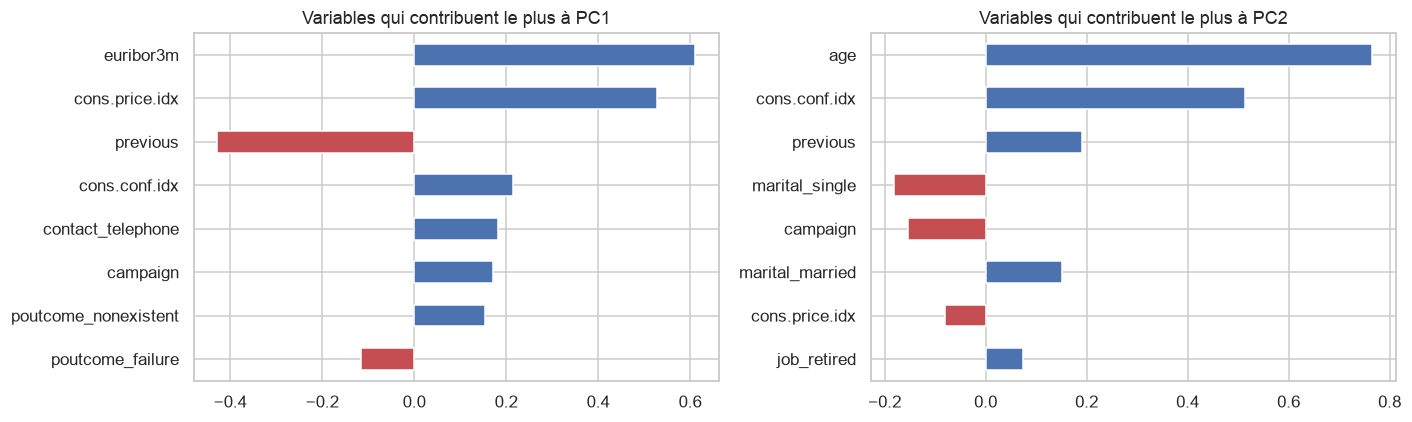

In [22]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X_a_full.columns, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)[:8][::-1]
    top.plot.barh(ax=ax, color=["#C44E52" if v < 0 else "#4C72B0" for v in top])
    ax.set_title(f"Variables qui contribuent le plus à {pc}")
plt.tight_layout(); plt.savefig(FIG / "01_pca_loadings.png", bbox_inches="tight"); plt.show()

**Interprétation des axes :**
- **PC1** oppose le contexte économique (`euribor3m`, `cons.price.idx`) à l'historique de contact (`previous`) : c'est un axe « conjoncture et relation passée avec la banque ».
- **PC2** est porté par l'`age` et la confiance des ménages (`cons.conf.idx`) : c'est un axe « profil du client ».

La variance est répartie sur beaucoup d'axes (il en faut une dizaine pour 80 %) : les données n'ont **pas** de structure simple en 2 dimensions, ce qui est habituel avec des indicatrices one-hot.

### 7.2 t-SNE et UMAP
La PCA est **linéaire**. t-SNE et UMAP sont **non linéaires** : ils cherchent à garder proches en 2D les points qui sont voisins dans l'espace d'origine. Ils servent à **visualiser**, pas à mesurer : les distances entre groupes éloignés n'y sont pas interprétables.

Ils sont calculés sur l'échantillon de 4 000 clients.

In [23]:
emb_file = OUT / "embeddings_sample.npz"
Z_pca = pca.transform(X_a)[:, :2]
if emb_file.exists():                      # déjà calculé : on relit (gain de temps)
    emb = np.load(emb_file)
    Z_tsne, Z_umap = emb["tsne"], emb["umap"]
else:
    Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X_a)
    Z_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(X_a)
    np.savez(emb_file, pca=Z_pca, tsne=Z_tsne, umap=Z_umap)
print("PCA :", Z_pca.shape, "| t-SNE :", Z_tsne.shape, "| UMAP :", Z_umap.shape)

PCA : (4000, 2) | t-SNE : (4000, 2) | UMAP : (4000, 2)


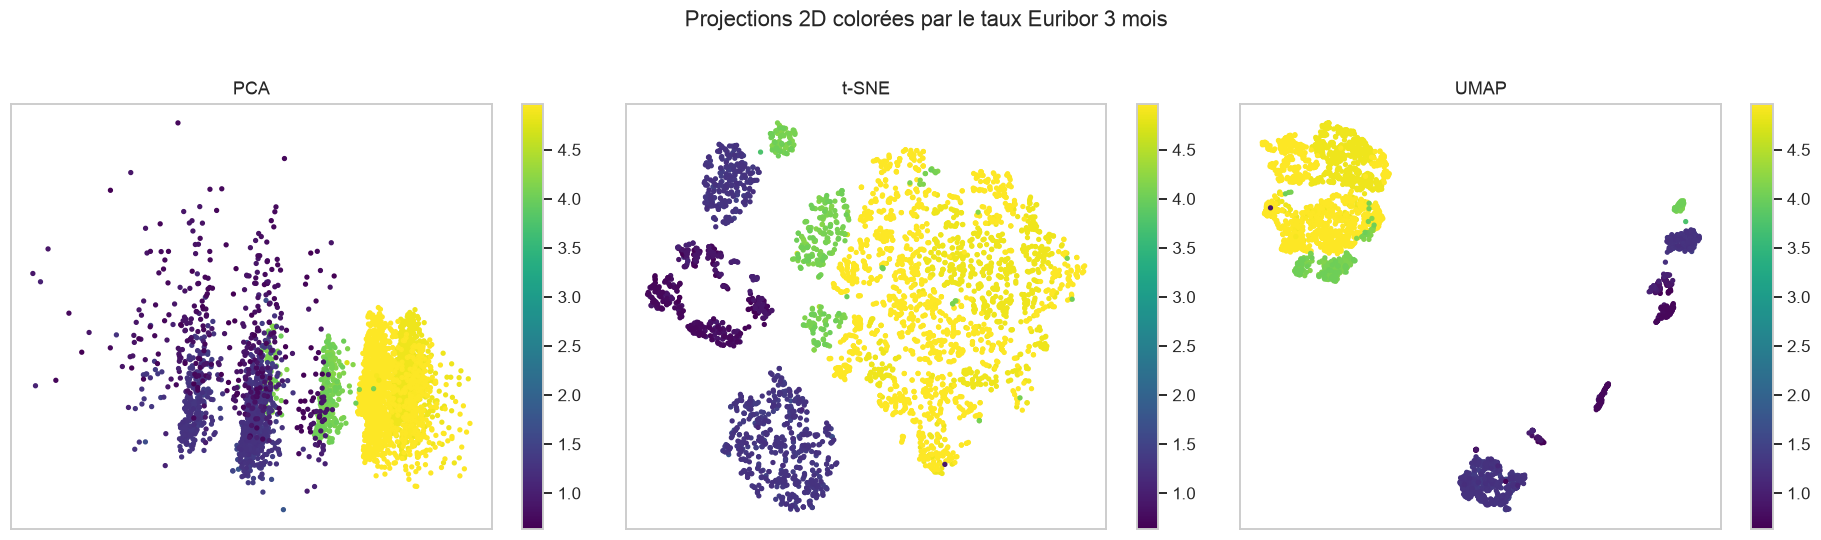

In [24]:
def plot_embeddings(color, title, cmap="viridis", categorical=False):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for ax, (name, Z) in zip(axes, [("PCA", Z_pca), ("t-SNE", Z_tsne), ("UMAP", Z_umap)]):
        if categorical:
            sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=color.values, s=8, ax=ax, linewidth=0, palette="Set1")
        else:
            sc = ax.scatter(Z[:, 0], Z[:, 1], c=color.values, s=6, cmap=cmap)
            plt.colorbar(sc, ax=ax)
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    return fig

fig = plot_embeddings(X_mixed["euribor3m"], "Projections 2D colorées par le taux Euribor 3 mois")
fig.savefig(FIG / "01_projections_euribor.png", bbox_inches="tight"); plt.show()

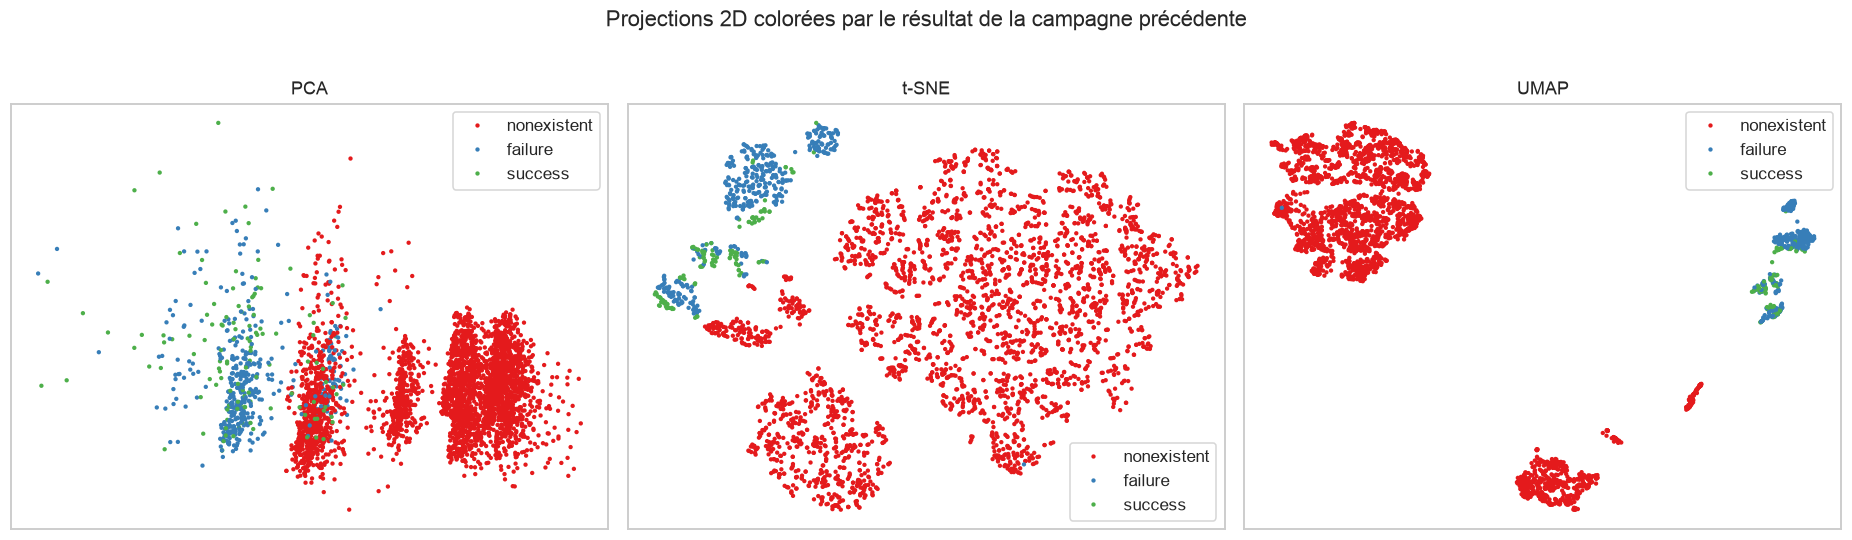

In [25]:
fig = plot_embeddings(X_mixed["poutcome"], "Projections 2D colorées par le résultat de la campagne précédente", categorical=True)
fig.savefig(FIG / "01_projections_poutcome.png", bbox_inches="tight"); plt.show()

**Ce que montrent les projections :**
- Sur la **PCA**, les clients s'organisent en bandes le long de PC1 : Euribor élevé d'un côté, Euribor bas de l'autre.
- **t-SNE** et **UMAP** révèlent quelques îlots, qui correspondent à des combinaisons de modalités (canal, résultat précédent, période). Les clients déjà démarchés (`poutcome` = `failure` ou `success`) forment des îlots bien à part.
- Aucune méthode ne montre 3 ou 4 « boules » nettes : il faut s'attendre à des **clusters qui se chevauchent** et à des silhouettes modestes.

## Bilan du Jour 1

| Point | Résultat |
|---|---|
| Données | 41 188 lignes → 41 176 après suppression de 12 doublons |
| Valeurs manquantes | `unknown` imputé par le mode (5 variables), conservé pour `default` |
| Valeurs aberrantes | `campaign` plafonnée au 99ᵉ centile ; `pdays` recodée en `contacted_before` |
| Variables actives | 15 (6 numériques + 9 catégorielles) |
| Représentation (a) | 37 colonnes, one-hot + standardisation |
| Représentation (b) | 15 colonnes mixtes pour Gower / K-prototypes |
| Échantillon | 4 000 clients, stratifié, représentatif |
| Réduction de dimension | PCA, t-SNE, UMAP calculés |

**Fonction de prétraitement réutilisable** : `src/preprocessing.py` → `prepare_all()` refait tout ce notebook en un appel. Les notebooks suivants commencent tous par cette ligne.

**Pistes pour la suite** : la structure dominante semble liée au contexte économique et à l'historique de contact. Reste à vérifier si les algorithmes la retrouvent, et avec combien de groupes.

# Jour 2 — Dissimilarités et méthodes de partitionnement

**Objectifs du jour (Chapitres 2 et 3.1)**

| Partie | Contenu |
|---|---|
| A | Matrices de dissimilarité : euclidienne, Manhattan, Gower, Hamming, Jaccard ; effet de la standardisation |
| B | K-means + méthode du coude |
| C | K-medoids sur la matrice de Gower |
| D | K-prototypes sur données mixtes |
| E | Modèle de mélange gaussien (GMM) + BIC / AIC |
| F | Tableau comparatif des méthodes |

In [26]:
import sys, time, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, pairwise_distances)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from kmodes.kprototypes import KPrototypes

from src.config import SEED, FIG, TAB, LAB, OUT, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix, kmedoids, knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Tout le Jour 1 en une ligne
d = pp.prepare_all()
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
X_a_full = d["X_a_full"]
n = len(X_a)
print("Échantillon :", X_a.shape, "| Population :", X_a_full.shape)

Échantillon : (4000, 37) | Population : (41176, 37)


# Partie A — Mesures de dissimilarité

Une méthode de clustering regroupe les individus « proches ». Tout dépend donc de la définition de la proximité. Rappel des formules, pour deux clients $x$ et $x'$ décrits par $p$ variables :

| Distance | Formule | Type de variables |
|---|---|---|
| Euclidienne | $d(x,x') = \sqrt{\sum_j (x_j - x'_j)^2}$ | numériques |
| Manhattan | $d(x,x') = \sum_j \lvert x_j - x'_j\rvert$ | numériques (moins sensible aux extrêmes) |
| Hamming | proportion de variables où $x_j \neq x'_j$ | binaires **symétriques** |
| Jaccard | $1 - \dfrac{\text{nb de « oui » communs}}{\text{nb de « oui » chez l'un ou l'autre}}$ | binaires **asymétriques** |
| Gower | $d(x,x') = \dfrac{1}{p}\sum_j d_j(x_j,x'_j)$ avec $d_j = \dfrac{\lvert x_j-x'_j\rvert}{\text{étendue}_j}$ (numérique) ou $\mathbb{1}[x_j\neq x'_j]$ (catégorielle) | **mixtes** |

## A.1 Euclidienne et Manhattan : effet de la standardisation
On calcule les deux distances sur les données one-hot, **sans** puis **avec** standardisation des variables numériques.

In [27]:
X_raw, _ = pp.encode(X_mixed, standardize=False)   # one-hot, numériques NON standardisées

D_euc_raw = pairwise_distances(X_raw, metric="euclidean")
D_man_raw = pairwise_distances(X_raw, metric="manhattan")
D_euc = pairwise_distances(X_a, metric="euclidean")
D_man = pairwise_distances(X_a, metric="manhattan")
print("Taille d'une matrice de dissimilarité :", D_euc.shape, f"({D_euc.nbytes / 1e6:.0f} Mo)")

Taille d'une matrice de dissimilarité : (4000, 4000) (128 Mo)


**Qui pèse dans la distance ?** La distance euclidienne au carré est une somme de termes, un par variable. En moyenne, le poids d'une variable est proportionnel à sa **variance**. On regarde donc la part de chaque variable dans la variance totale.

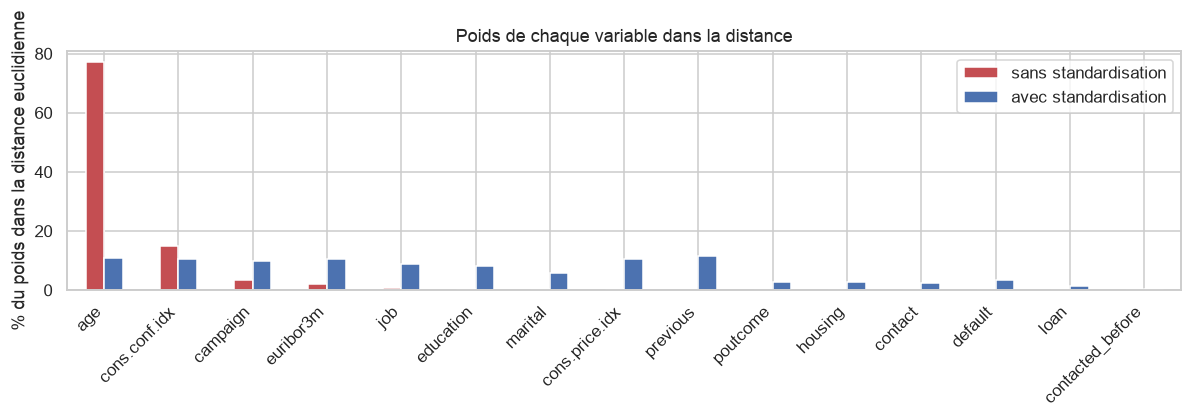

,sans standardisation,avec standardisation
age,77.0,10.9
cons.conf.idx,14.9,10.6
campaign,3.4,9.8
euribor3m,2.1,10.5
job,0.6,8.9
education,0.5,8.3
marital,0.4,5.7
cons.price.idx,0.2,10.7


In [28]:
def weight_by_variable(X):
    """Part (%) de chaque variable d'origine dans la variance totale."""
    var = X.var()
    groups = {c: (c if c in pp.ACTIVE_NUM else c.rsplit("_", 1)[0] if c.startswith("contacted") else c.split("_")[0])
              for c in X.columns}
    return (100 * var.groupby(groups).sum() / var.sum()).sort_values(ascending=False)

w = pd.DataFrame({"sans standardisation": weight_by_variable(X_raw),
                  "avec standardisation": weight_by_variable(X_a)}).fillna(0)
w = w.sort_values("sans standardisation", ascending=False)
ax = w.plot.bar(figsize=(11, 3.8), color=["#C44E52", "#4C72B0"])
ax.set_ylabel("% du poids dans la distance euclidienne"); ax.set_title("Poids de chaque variable dans la distance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.savefig(FIG / "02_poids_variables.png", bbox_inches="tight"); plt.show()
w.round(1).head(8)

In [29]:
# Les voisinages changent-ils ? On compare les 10 plus proches voisins de chaque client.
def knn_sets(D, k=10):
    return np.argsort(D, axis=1)[:, 1:k + 1]

def overlap(Da, Db, k=10):
    A, B = knn_sets(Da, k), knn_sets(Db, k)
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(A, B)])

print(f"Voisins communs (10-NN) euclidienne brute vs standardisée : {overlap(D_euc_raw, D_euc):.1%}")
print(f"Voisins communs (10-NN) Manhattan  brute vs standardisée : {overlap(D_man_raw, D_man):.1%}")
print(f"Voisins communs (10-NN) euclidienne vs Manhattan (standardisées) : {overlap(D_euc, D_man):.1%}")

Voisins communs (10-NN) euclidienne brute vs standardisée : 23.1%


Voisins communs (10-NN) Manhattan  brute vs standardisée : 37.2%


Voisins communs (10-NN) euclidienne vs Manhattan (standardisées) : 82.7%


**Lecture :**
- **Sans standardisation**, l'`age` écrase tout : il porte à lui seul 77 % de la distance, simplement parce qu'il est exprimé en dizaines d'unités. Deux clients seraient jugés « proches » dès qu'ils ont le même âge, quels que soient leur métier ou leur historique.
- **Avec standardisation**, les six variables numériques ont le même poids et les variables catégorielles retrouvent une influence.
- Les voisinages sont profondément modifiés : seuls 23 % des 10 plus proches voisins d'un client restent les mêmes. La standardisation n'est donc pas un détail technique, elle **change les groupes**.
- Euclidienne et Manhattan (standardisées) donnent des voisinages proches : le choix entre les deux a peu d'effet ici.

**Limite qui reste** : même standardisée, la représentation (a) met sur la même échelle un écart-type d'âge et un changement de modalité 0/1. Ce mélange est arbitraire. C'est ce que corrige la distance de Gower.

## A.2 Distance de Gower (données mixtes)
Gower traite chaque variable selon sa nature, ramène chaque contribution dans $[0, 1]$, puis fait la moyenne. Chaque variable compte donc pour $1/15$, qu'elle soit numérique ou catégorielle.

In [30]:
t0 = time.perf_counter()
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)
print(f"Matrice de Gower : {D_gow.shape}, calculée ou relue en {time.perf_counter() - t0:.1f} s")
print(f"min = {D_gow.min():.3f} | moyenne = {D_gow.mean():.3f} | max = {D_gow.max():.3f}")

Matrice de Gower : (4000, 4000), calculée ou relue en 0.1 s
min = 0.000 | moyenne = 0.349 | max = 0.873


In [31]:
# Illustration : le couple de clients le plus proche et le plus éloigné au sens de Gower
iu = np.triu_indices(n, k=1)
g = D_gow[iu]
i_far, j_far = iu[0][g.argmax()], iu[1][g.argmax()]
pos = np.where(g > 0)[0]
i_near, j_near = iu[0][pos[g[pos].argmin()]], iu[1][pos[g[pos].argmin()]]
print(f"Couple le plus PROCHE (Gower = {D_gow[i_near, j_near]:.4f})")
display(X_mixed.iloc[[i_near, j_near]])
print(f"Couple le plus ÉLOIGNÉ (Gower = {D_gow[i_far, j_far]:.3f})")
display(X_mixed.iloc[[i_far, j_far]])

Couple le plus PROCHE (Gower = 0.0000)


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before
599,34,1,0,93.994,-36.4,4.857,services,married,high.school,no,no,no,telephone,nonexistent,no
4713,34,1,0,93.994,-36.4,4.858,services,married,high.school,no,no,no,telephone,nonexistent,no


Couple le plus ÉLOIGNÉ (Gower = 0.873)


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before
9954,38,9,0,94.465,-41.8,4.959,admin.,single,university.degree,no,no,yes,telephone,nonexistent,no
38440,98,1,2,92.431,-26.9,0.730,retired,married,basic.4y,unknown,yes,no,cellular,success,yes


La distance se lit directement : le couple le plus proche ne diffère que par un détail numérique ; le couple le plus éloigné diffère sur presque toutes les variables.

## A.3 Hamming et Jaccard (variables binaires)
On isole le bloc des variables binaires, codées en « présence d'une caractéristique ».

In [32]:
B = pd.DataFrame({
    "pret_immobilier":   X_mixed["housing"] == "yes",
    "pret_personnel":    X_mixed["loan"] == "yes",
    "contact_mobile":    X_mixed["contact"] == "cellular",
    "deja_contacte":     X_mixed["contacted_before"] == "yes",
    "defaut_inconnu":    X_mixed["default"] != "no",
    "succes_precedent":  X_mixed["poutcome"] == "success",
})
print("Fréquence de chaque caractéristique (% de « oui ») :")
print((100 * B.mean()).round(1).to_string())

D_ham = squareform(pdist(B.values, metric="hamming"))
D_jac = squareform(pdist(B.values, metric="jaccard"))

Fréquence de chaque caractéristique (% de « oui ») :
pret_immobilier     56.2
pret_personnel      16.0
contact_mobile      64.5
deja_contacte        3.5
defaut_inconnu      20.7
succes_precedent     3.2


In [33]:
# Exemple parlant : deux clients qui n'ont AUCUN « oui » en commun
a = B.index[(B.sum(axis=1) == 1) & B["pret_personnel"]][0]
b = B.index[(B.sum(axis=1) == 1) & B["pret_immobilier"]][0]
ia, ib = B.index.get_loc(a), B.index.get_loc(b)
display(B.loc[[a, b]].astype(int))
print(f"Hamming = {D_ham[ia, ib]:.2f}   (ils diffèrent sur 2 variables sur 6 -> jugés plutôt proches)")
print(f"Jaccard = {D_jac[ia, ib]:.2f}   (aucun « oui » en commun -> jugés totalement différents)")

,pret_immobilier,pret_personnel,contact_mobile,deja_contacte,defaut_inconnu,succes_precedent
4,0,1,0,0,0,0
13,1,0,0,0,0,0


Hamming = 0.33   (ils diffèrent sur 2 variables sur 6 -> jugés plutôt proches)
Jaccard = 1.00   (aucun « oui » en commun -> jugés totalement différents)


**Quelle distance pour quelles variables ?**
- **Hamming** compte de la même façon les accords « oui-oui » et « non-non ». Elle convient aux binaires **symétriques** (`contact` : mobile ou fixe, les deux modalités se valent).
- **Jaccard** ignore les accords « non-non ». Elle convient aux binaires **asymétriques**, où le « oui » est rare et porteur de sens (`succes_precedent` : 3 % des clients ; `pret_personnel` : 16 %). Deux clients qui n'ont pas de prêt personnel ne se ressemblent pas pour autant.

## A.4 Les distances racontent-elles la même histoire ?
Corrélation de rang (Spearman) entre les distances, sur 200 000 paires de clients tirées au hasard.

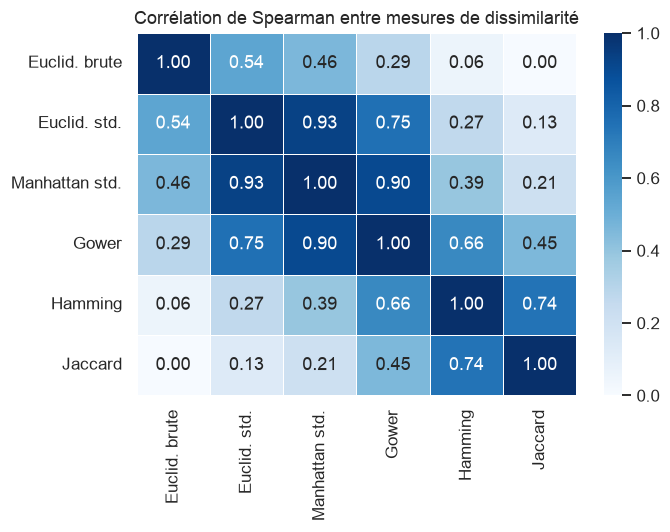

In [34]:
rng = np.random.default_rng(SEED)
sel = rng.choice(len(iu[0]), size=200_000, replace=False)
pairs = (iu[0][sel], iu[1][sel])
dist_tab = pd.DataFrame({
    "Euclid. brute": D_euc_raw[pairs], "Euclid. std.": D_euc[pairs],
    "Manhattan std.": D_man[pairs], "Gower": D_gow[pairs],
    "Hamming": D_ham[pairs], "Jaccard": D_jac[pairs]})
rho = dist_tab.corr(method="spearman")
plt.figure(figsize=(6.5, 5))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5)
plt.title("Corrélation de Spearman entre mesures de dissimilarité")
plt.tight_layout(); plt.savefig(FIG / "02_correlation_distances.png", bbox_inches="tight"); plt.show()

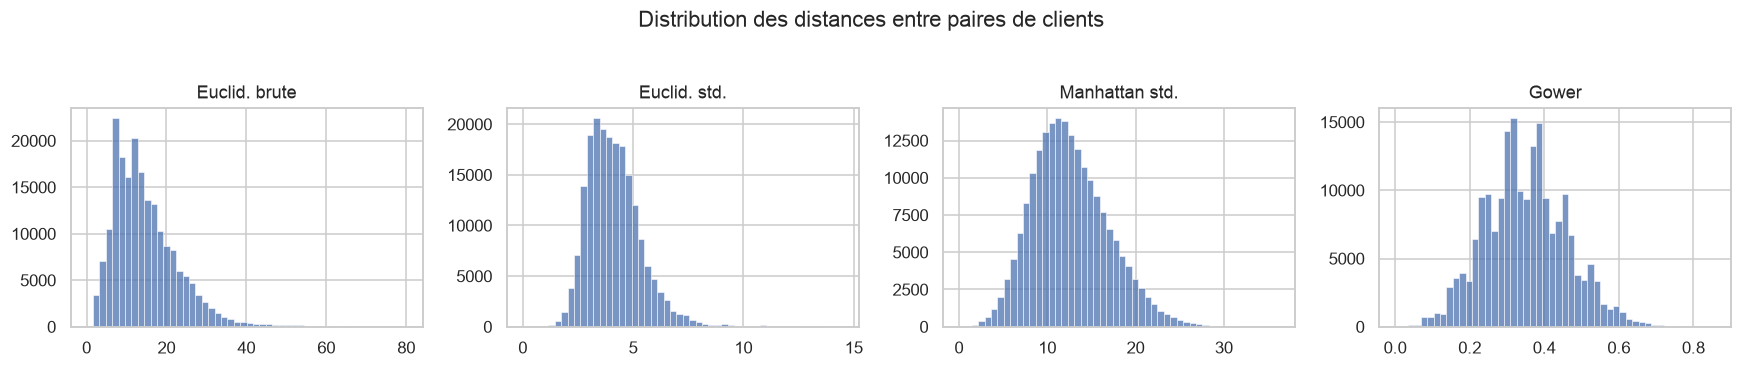

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col in zip(axes, ["Euclid. brute", "Euclid. std.", "Manhattan std.", "Gower"]):
    sns.histplot(dist_tab[col], bins=50, ax=ax, color="#4C72B0"); ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Distribution des distances entre paires de clients", y=1.04)
plt.tight_layout(); plt.savefig(FIG / "02_distributions_distances.png", bbox_inches="tight"); plt.show()

**Bilan de la partie A — choix et justification des distances**

| Méthode | Distance retenue | Justification |
|---|---|---|
| K-means, GMM, Ward, DBSCAN | Euclidienne sur la représentation (a) **standardisée** | Ces méthodes reposent sur des moyennes et des variances : elles exigent un espace euclidien. La standardisation empêche l'âge de dominer. |
| K-medoids, CAH (liens autres que Ward) | **Gower** | Seule distance qui respecte la nature mixte des données et donne le même poids à chaque variable. |
| K-prototypes | Euclidienne (numériques) + désaccord simple (catégorielles) | Même idée que Gower, intégrée dans l'algorithme. |
| Analyse du bloc binaire | Jaccard pour les « oui » rares, Hamming sinon | Selon que la variable est asymétrique ou symétrique. |

La distance euclidienne brute est très peu corrélée aux autres : elle ne mesure presque que l'écart d'âge. Elle est écartée.

# Partie B — K-means et méthode du coude

K-means cherche $k$ centres qui minimisent l'**inertie intra-classe** $W = \sum_{c}\sum_{x \in C_c} \lVert x - \mu_c\rVert^2$.
L'inertie diminue toujours quand $k$ augmente : on cherche le **coude**, c'est-à-dire le $k$ au-delà duquel ajouter un cluster ne rapporte plus grand-chose.

K-means est rapide : la courbe du coude est tracée sur la **population complète** (41 176 clients).

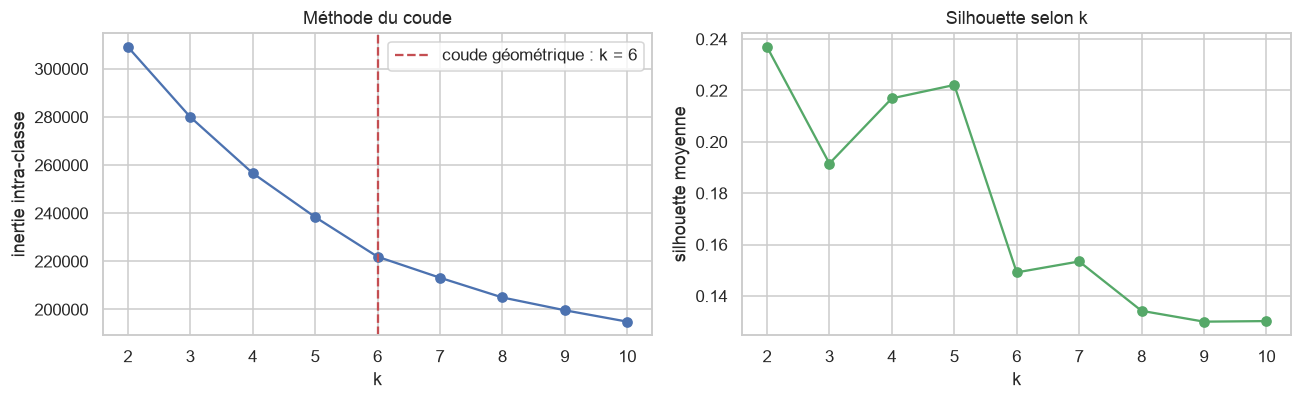

,k,inertie,silhouette,gain d'inertie (%)
0,2,309128.170,0.237,NaN
1,3,279986.774,0.192,9.4
2,4,256651.904,0.217,8.3
3,5,238401.447,0.222,7.1
4,6,221918.648,0.149,6.9
5,7,213186.680,0.153,3.9
6,8,204975.864,0.134,3.9
7,9,199659.909,0.130,2.6
8,10,194925.770,0.130,2.4


In [36]:
ks = list(range(2, 11))
inertia, sil_full = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_a_full)
    inertia.append(km.inertia_)
    sil_full.append(silhouette_score(X_a_full, km.labels_, sample_size=5000, random_state=SEED))
elbow = pd.DataFrame({"k": ks, "inertie": inertia, "silhouette": sil_full})
elbow["gain d'inertie (%)"] = (-100 * elbow["inertie"].pct_change()).round(1)
k_elbow = ks[knee_point(inertia)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ks, inertia, "o-"); axes[0].axvline(k_elbow, ls="--", color="#C44E52", label=f"coude géométrique : k = {k_elbow}")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertie intra-classe"); axes[0].set_title("Méthode du coude"); axes[0].legend()
axes[1].plot(ks, sil_full, "o-", color="#55A868"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette moyenne"); axes[1].set_title("Silhouette selon k")
plt.tight_layout(); plt.savefig(FIG / "02_kmeans_coude.png", bbox_inches="tight"); plt.show()
elbow.round(3)

**Lecture.** La courbe d'inertie décroît régulièrement, sans cassure franche : c'est le signe de clusters qui se chevauchent. Les deux critères ne désignent pas le même $k$ :
- le **coude** : chaque groupe ajouté fait gagner 7 à 9 % d'inertie jusqu'à k = 6, puis moins de 4 % ensuite. Le coude géométrique se situe donc vers **k = 6** ;
- la **silhouette** : elle est maximale pour **k = 2** (0,24), reste correcte jusqu'à k = 5 (environ 0,20), puis chute à partir de k = 6.

→ Le coude donne une borne haute (inutile d'aller au-delà de 6), la silhouette préfère peu de groupes. On garde donc les partitions pour **k = 2 à 6** ; le choix final sera fait au Jour 4 avec tous les indices.

Pour comparer K-means aux méthodes à matrice de distances, on l'ajuste aussi sur l'échantillon de 4 000 clients.

In [37]:
partitions = pd.DataFrame(index=X_a.index)      # toutes les partitions du projet
timing = {}
K_RANGE = range(2, 7)

t0 = time.perf_counter()
for k in K_RANGE:
    partitions[f"kmeans_k{k}"] = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_a)
timing["K-means"] = (time.perf_counter() - t0) / len(K_RANGE)

# Cohérence échantillon / population pour k = 3
km_full = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_a_full)
print(f"ARI entre K-means(population) et K-means(échantillon), k = 3 : "
      f"{adjusted_rand_score(km_full.predict(X_a), partitions['kmeans_k3']):.3f}")

ARI entre K-means(population) et K-means(échantillon), k = 3 : 0.995


# Partie C — K-medoids sur la matrice de Gower

Même principe que K-means, mais le centre de chaque cluster est un **médoïde** : un client réel, celui qui minimise la somme des distances aux autres membres. Deux avantages :
- il fonctionne avec **n'importe quelle matrice de dissimilarité** (ici Gower) ;
- il est plus robuste aux valeurs extrêmes, et le médoïde est un « client type » directement lisible.

> **Note technique.** Le sujet indique `scikit-learn-extra`. Cette bibliothèque n'est plus maintenue et ne s'importe pas avec NumPy ≥ 2. La fonction `kmedoids()` de `src/clustering_utils.py` l'utilise si elle est disponible, et bascule sinon sur une implémentation maison du même algorithme (alternance affectation / mise à jour des médoïdes, initialisation k-medoids++).

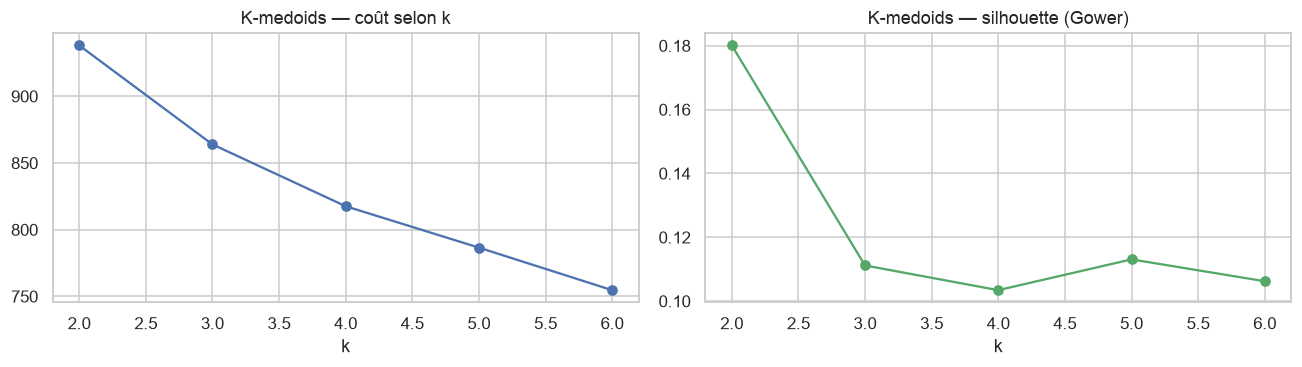

,k,coût (somme des distances aux médoïdes),silhouette (Gower)
0,2,938.155,0.180
1,3,863.937,0.111
2,4,817.589,0.103
3,5,786.567,0.113
4,6,754.688,0.106


In [38]:
t0 = time.perf_counter()
kmed_rows, medoid_idx = [], {}
for k in K_RANGE:
    labels, medoids, cost = kmedoids(D_gow, k, n_init=5, seed=SEED)
    partitions[f"kmedoids_k{k}"] = labels
    medoid_idx[k] = medoids
    kmed_rows.append({"k": k, "coût (somme des distances aux médoïdes)": cost,
                      "silhouette (Gower)": silhouette_score(D_gow, labels, metric="precomputed")})
timing["K-medoids (Gower)"] = (time.perf_counter() - t0) / len(K_RANGE)
kmed = pd.DataFrame(kmed_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(kmed["k"], kmed.iloc[:, 1], "o-"); axes[0].set_title("K-medoids — coût selon k"); axes[0].set_xlabel("k")
axes[1].plot(kmed["k"], kmed.iloc[:, 2], "o-", color="#55A868"); axes[1].set_title("K-medoids — silhouette (Gower)"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(FIG / "02_kmedoids.png", bbox_inches="tight"); plt.show()
kmed.round(3)

In [39]:
print("Les 3 médoïdes (clients types) pour k = 3 :")
X_mixed.iloc[medoid_idx[3]].assign(effectif=np.bincount(partitions["kmedoids_k3"]))

Les 3 médoïdes (clients types) pour k = 3 :


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before,effectif
7546,34,2,0,93.994,-36.4,4.864,admin.,married,university.degree,no,no,no,telephone,nonexistent,no,1336
16085,46,1,0,93.918,-42.7,4.961,blue-collar,married,university.degree,no,yes,no,cellular,nonexistent,no,1593
34325,31,1,0,92.893,-46.2,1.266,admin.,single,high.school,no,yes,no,cellular,nonexistent,no,1071


**Lecture.** La silhouette (calculée en distance de Gower) est la plus élevée pour k = 2 puis se stabilise autour de 0,10 : la structure est **faible** au sens de Gower. Les médoïdes sont instructifs : ils se distinguent surtout par des variables catégorielles (canal de contact, prêt immobilier, statut marital…). Comme Gower donne le même poids à chacune des 15 variables, le contexte économique ne domine plus et K-medoids découpe la clientèle selon d'autres critères que K-means.

# Partie D — K-prototypes sur données mixtes

K-prototypes combine K-means (partie numérique) et K-modes (partie catégorielle). Le coût à minimiser est
$$\sum_{c}\sum_{x\in C_c}\Big(\underbrace{\lVert x^{num}-\mu_c\rVert^2}_{\text{euclidienne}} + \gamma \underbrace{\textstyle\sum_j \mathbb{1}[x^{cat}_j \ne m_{c,j}]}_{\text{désaccords}}\Big)$$
Le prototype d'un cluster est donc une **moyenne** pour les numériques et un **mode** pour les catégorielles ; $\gamma$ règle l'équilibre entre les deux (valeur automatique de `kmodes` : la moitié de l'écart-type moyen des numériques).

Les variables numériques sont standardisées, les catégorielles restent telles quelles.

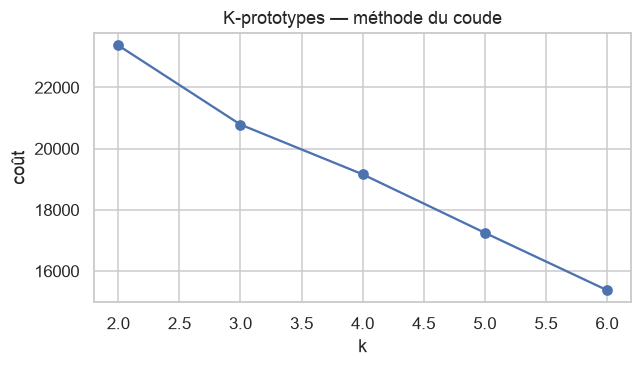

,k,coût,gain (%)
0,2,23376.9,NaN
1,3,20788.2,11.1
2,4,19162.5,7.8
3,5,17252.2,10.0
4,6,15376.1,10.9


In [40]:
X_kp = X_mixed.copy()
X_kp[pp.ACTIVE_NUM] = X_a[pp.ACTIVE_NUM]                     # numériques standardisées
cat_idx = [X_kp.columns.get_loc(c) for c in pp.ACTIVE_CAT]
X_kp_values = X_kp.astype(object).values

t0 = time.perf_counter()
kp_rows, kp_models = [], {}
for k in K_RANGE:
    kp = KPrototypes(n_clusters=k, init="Huang", n_init=3, random_state=SEED)
    partitions[f"kprototypes_k{k}"] = kp.fit_predict(X_kp_values, categorical=cat_idx)
    kp_models[k] = kp
    kp_rows.append({"k": k, "coût": kp.cost_})
timing["K-prototypes"] = (time.perf_counter() - t0) / len(K_RANGE)
kpdf = pd.DataFrame(kp_rows)
kpdf["gain (%)"] = (-100 * kpdf["coût"].pct_change()).round(1)

plt.figure(figsize=(6, 3.5))
plt.plot(kpdf["k"], kpdf["coût"], "o-"); plt.xlabel("k"); plt.ylabel("coût"); plt.title("K-prototypes — méthode du coude")
plt.tight_layout(); plt.savefig(FIG / "02_kprototypes_coude.png", bbox_inches="tight"); plt.show()
kpdf.round(1)

In [41]:
print("Prototypes pour k = 3 (numériques standardisées : 0 = moyenne de la population)")
proto = pd.DataFrame(kp_models[3].cluster_centroids_, columns=pp.ACTIVE_NUM + pp.ACTIVE_CAT)
proto[pp.ACTIVE_NUM] = proto[pp.ACTIVE_NUM].astype(float).round(2)
proto.assign(effectif=np.bincount(partitions["kprototypes_k3"]))

Prototypes pour k = 3 (numériques standardisées : 0 = moyenne de la population)


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before,effectif
0,-0.02,-0.18,-0.35,-0.94,-0.53,-0.94,admin.,married,university.degree,no,yes,no,cellular,nonexistent,no,1112
1,0.03,0.11,-0.35,0.61,0.31,0.75,blue-collar,married,university.degree,no,yes,no,telephone,nonexistent,no,2318
2,0.02,-0.29,2.21,-0.85,-0.20,-1.20,admin.,married,university.degree,no,yes,no,cellular,failure,no,570


**Lecture.** Les prototypes sont faciles à lire. Pour k = 3, ils opposent des clients contactés en période de taux élevés (Euribor au-dessus de la moyenne, jamais démarchés auparavant), des clients contactés en période de taux bas, et un petit groupe de clients **déjà démarchés** lors d'une campagne précédente (`previous` très au-dessus de la moyenne).

# Partie E — Modèle de mélange gaussien (GMM)

Le GMM suppose que les données proviennent d'un mélange de $k$ lois normales. Différences avec K-means :
- affectation **probabiliste** (chaque client a une probabilité d'appartenir à chaque groupe) ;
- clusters **elliptiques** de tailles et d'orientations différentes (matrices de covariance).

Le nombre de composantes est choisi par les critères d'information, à **minimiser** :
$\text{BIC} = -2\ln L + q\ln n$ et $\text{AIC} = -2\ln L + 2q$ ($q$ = nombre de paramètres).

Estimer une covariance complète sur 37 colonnes one-hot est instable (colonnes liées entre elles). On ajuste donc le GMM sur les **10 premières composantes principales** (80 % de la variance).

Variance conservée par 10 composantes : 82.4%


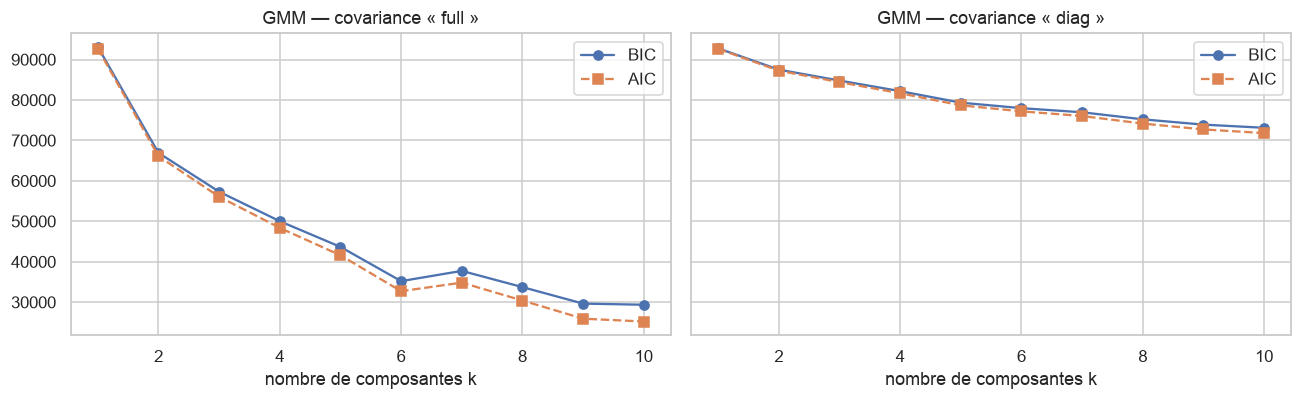

covariance,diag,full
k,,
1,92762.0,93135.0
2,87500.0,66922.0
3,84799.0,57313.0
4,82185.0,50024.0
5,79335.0,43668.0
6,77974.0,35205.0
7,76954.0,37736.0
8,75212.0,33724.0
9,73901.0,29650.0


In [42]:
pca10 = PCA(n_components=10, random_state=SEED).fit(X_a)
Z10 = pca10.transform(X_a)
print(f"Variance conservée par 10 composantes : {pca10.explained_variance_ratio_.sum():.1%}")

t0 = time.perf_counter()
gmm_rows = []
for cov in ["full", "diag"]:
    for k in range(1, 11):
        gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=3, random_state=SEED).fit(Z10)
        gmm_rows.append({"covariance": cov, "k": k, "BIC": gm.bic(Z10), "AIC": gm.aic(Z10)})
        if cov == "full" and k in K_RANGE:
            partitions[f"gmm_k{k}"] = gm.predict(Z10)
timing["GMM"] = (time.perf_counter() - t0) / 20
gmm = pd.DataFrame(gmm_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, cov in zip(axes, ["full", "diag"]):
    sub = gmm[gmm["covariance"] == cov]
    ax.plot(sub["k"], sub["BIC"], "o-", label="BIC"); ax.plot(sub["k"], sub["AIC"], "s--", label="AIC")
    ax.set_title(f"GMM — covariance « {cov} »"); ax.set_xlabel("nombre de composantes k"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "02_gmm_bic_aic.png", bbox_inches="tight"); plt.show()
gmm.pivot(index="k", columns="covariance", values="BIC").round(0)

**Lecture — un résultat à interpréter avec prudence.**
- La covariance **complète** (`full`) donne des BIC nettement plus bas que la covariance diagonale : les variables sont corrélées à l'intérieur des groupes.
- BIC et AIC **continuent de décroître** jusqu'à k = 10 : aucun minimum net n'apparaît. Ce n'est pas la preuve qu'il existe 10 segments. Les données contiennent des indicatrices et des indicateurs économiques qui ne prennent que quelques valeurs : elles sont loin d'être gaussiennes, et le modèle ajoute des composantes pour épouser chaque petit paquet de points. Le BIC ne peut donc pas servir seul à choisir $k$ ici.
- On retient les partitions GMM pour k = 2 à 6 et on les jugera au Jour 4 avec les mêmes indices que les autres méthodes.

# Partie F — Tableau comparatif des méthodes de partitionnement

Pour comparer équitablement, la silhouette est calculée dans **les deux espaces** :
- *silhouette euclidienne* : sur la représentation (a) — espace « naturel » de K-means et GMM ;
- *silhouette Gower* : sur la matrice de Gower — espace « naturel » de K-medoids et K-prototypes.

Rappels : silhouette ∈ [−1, 1], **plus haut = mieux** ; Davies-Bouldin ≥ 0, **plus bas = mieux**.

In [43]:
names = {"kmeans": "K-means", "kmedoids": "K-medoids (Gower)", "kprototypes": "K-prototypes", "gmm": "GMM"}
rows = []
for key, name in names.items():
    for k in [2, 3, 4]:
        lab = partitions[f"{key}_k{k}"].values
        sizes = np.bincount(lab)
        rows.append({"méthode": name, "k": k,
                     "silhouette eucl.": silhouette_score(X_a, lab),
                     "silhouette Gower": silhouette_score(D_gow, lab, metric="precomputed"),
                     "Davies-Bouldin": davies_bouldin_score(X_a, lab),
                     "plus petit cluster (%)": 100 * sizes.min() / n,
                     "tailles": " / ".join(map(str, sorted(sizes, reverse=True)))})
comp = pd.DataFrame(rows)
comp.to_csv(TAB / "02_comparatif_partitionnement.csv", index=False)
comp.style.format({"silhouette eucl.": "{:.3f}", "silhouette Gower": "{:.3f}", "Davies-Bouldin": "{:.2f}",
                   "plus petit cluster (%)": "{:.1f}"}).background_gradient(
    subset=["silhouette eucl.", "silhouette Gower"], cmap="Greens").hide(axis="index")

méthode,k,silhouette eucl.,silhouette Gower,Davies-Bouldin,plus petit cluster (%),tailles
K-means,2,0.237,0.233,1.88,33.8,2650 / 1350
K-means,3,0.186,0.175,1.92,14.2,2326 / 1104 / 570
K-means,4,0.182,0.121,1.84,7.9,2030 / 1085 / 569 / 316
K-medoids (Gower),2,0.111,0.180,2.54,45.5,2182 / 1818
K-medoids (Gower),3,0.039,0.111,3.73,26.8,1593 / 1336 / 1071
K-medoids (Gower),4,0.042,0.103,3.86,21.8,1075 / 1035 / 1018 / 872
K-prototypes,2,0.236,0.232,1.88,33.8,2647 / 1353
K-prototypes,3,0.185,0.175,1.92,14.2,2318 / 1112 / 570
K-prototypes,4,0.126,0.089,2.26,7.6,1519 / 1159 / 1017 / 305
GMM,2,0.235,0.233,1.89,34.6,2616 / 1384


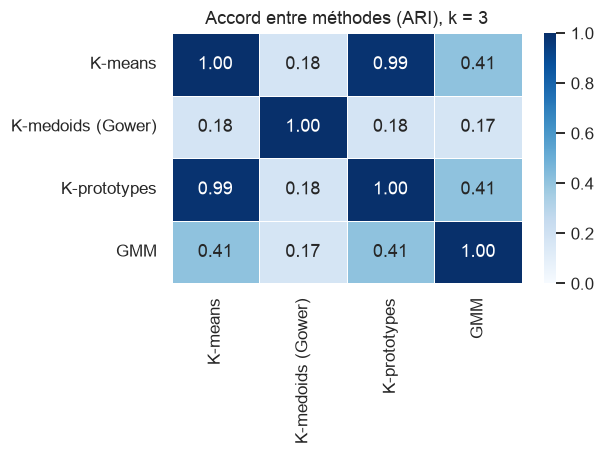

In [44]:
# Les méthodes trouvent-elles les mêmes groupes ? ARI entre partitions (k = 3)
cols3 = [f"{key}_k3" for key in names]
agree = pd.DataFrame([[adjusted_rand_score(partitions[a], partitions[b]) for b in cols3] for a in cols3],
                     index=names.values(), columns=names.values())
plt.figure(figsize=(5.8, 4.3))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5)
plt.title("Accord entre méthodes (ARI), k = 3")
plt.tight_layout(); plt.savefig(FIG / "02_accord_methodes.png", bbox_inches="tight"); plt.show()

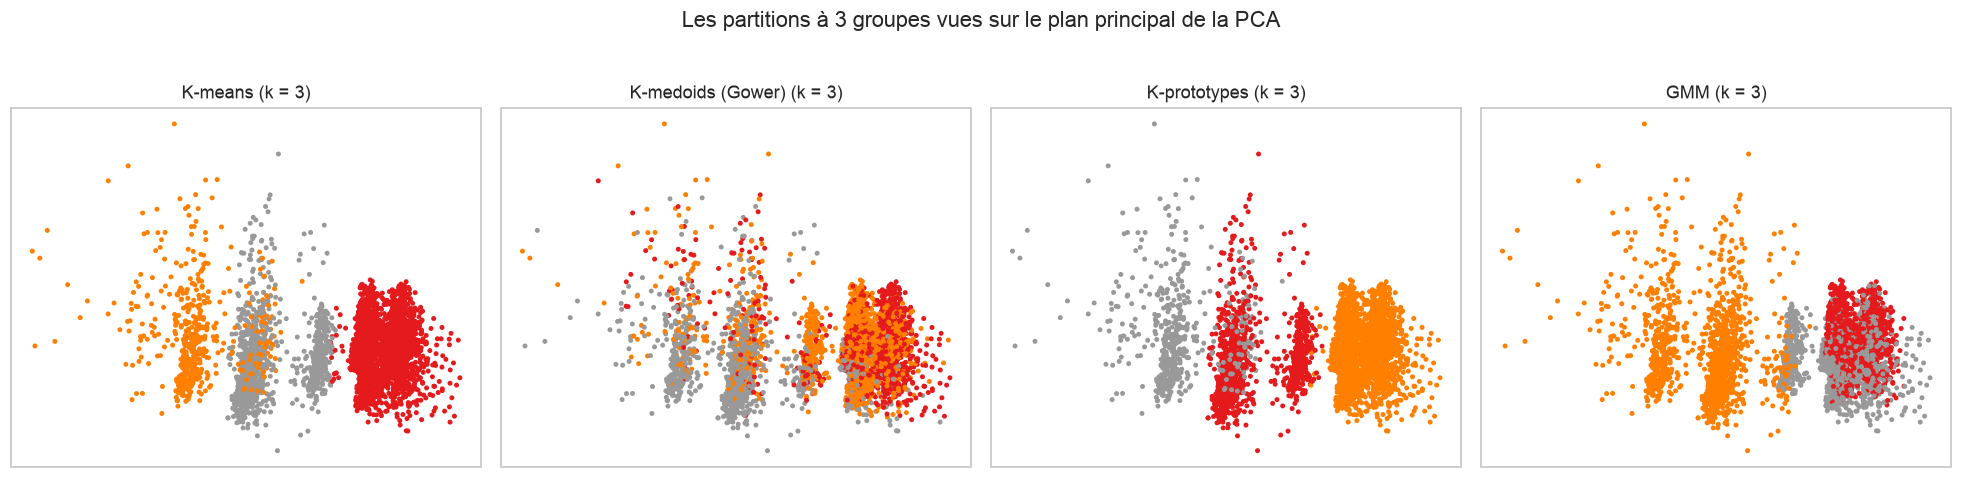

In [45]:
# Visualisation des quatre partitions (k = 3) sur le plan principal de la PCA (Jour 1)
emb = np.load(OUT / "embeddings_sample.npz")
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (key, name) in zip(axes, names.items()):
    ax.scatter(emb["pca"][:, 0], emb["pca"][:, 1], c=partitions[f"{key}_k3"], s=5, cmap="Set1")
    ax.set_title(f"{name} (k = 3)"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Les partitions à 3 groupes vues sur le plan principal de la PCA", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "02_partitions_pca.png", bbox_inches="tight"); plt.show()

In [46]:
print("Temps de calcul moyen par ajustement (4 000 clients) :")
print(pd.Series(timing).round(2).astype(str).add(" s").to_string())

Temps de calcul moyen par ajustement (4 000 clients) :
K-means              0.05 s
K-medoids (Gower)    0.44 s
K-prototypes         2.44 s
GMM                   0.1 s


### Synthèse qualitative

| Méthode | Données | Distance | Forme des clusters | Points forts | Limites observées ici |
|---|---|---|---|---|---|
| **K-means** | (a) one-hot standardisé | euclidienne | sphériques, tailles voisines | très rapide, passe à l'échelle (41 000 clients) | sensible à l'initialisation et aux extrêmes ; centres non interprétables sur des indicatrices |
| **K-medoids** | matrice de Gower | Gower | quelconque autour d'un client type | robuste, médoïdes lisibles, respecte les données mixtes | matrice $n^2$ en mémoire ; structure faible (silhouette ≈ 0,1) |
| **K-prototypes** | (b) mixtes | euclidienne + désaccords | sphériques (partie numérique) | natif pour le mixte, prototypes très lisibles | lent ; dépend de $\gamma$ |
| **GMM** | PCA (10 axes) | vraisemblance gaussienne | elliptiques, affectation souple | probabilités d'appartenance | hypothèse gaussienne non vérifiée, BIC sans minimum |

### Bilan du Jour 2
1. **La standardisation est indispensable** : sans elle, l'âge porte presque toute la distance.
2. **Gower** est la distance adaptée aux données mixtes ; elle donne une vision différente de l'euclidienne (accord faible entre K-medoids et les autres méthodes).
3. K-means, K-prototypes et GMM s'accordent presque parfaitement à **k = 2** (ARI de 0,97 à 0,99 : contexte de taux élevés contre taux bas). À k = 3, K-means et K-prototypes restent d'accord (ARI = 0,99) et isolent un troisième groupe de clients déjà démarchés ; le GMM découpe autrement.
4. À ce stade, les meilleurs candidats sont **K-means et K-prototypes avec k = 2 ou 3**. À k = 4, K-prototypes dépend fortement de l'initialisation (deux exécutions dans des environnements différents donnent un ARI de 0,51 entre elles). La décision est reportée au Jour 4.

In [47]:
partitions.to_csv(LAB / "partitions_j2.csv")
print("Partitions enregistrées :", partitions.shape[1], "colonnes ->", LAB / "partitions_j2.csv")

Partitions enregistrées : 20 colonnes -> /Users/NOKHO/Desktop/M1BDA/Semestre2_M1BDA/Apprentissage non suppervisé/Projet/segmentation-bancaire/outputs/labels/partitions_j2.csv


# Jour 3 — Clustering hiérarchique et par densité

**Objectifs du jour (Chapitres 3.2 et 3.3)**

| Partie | Contenu |
|---|---|
| A | Classification ascendante hiérarchique (CAH) : liens *single*, *complete*, *average*, *Ward* ; dendrogrammes ; choix de la coupure |
| B | DBSCAN : réglage de ε et `min_samples` par le graphique des k-distances ; points cœur, bordure, bruit |
| C | Limites de K-means face à DBSCAN |

In [48]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from src.config import SEED, FIG, TAB, LAB, OUT, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix, knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

d = pp.prepare_all()
X_a, X_mixed, y, illus = d["X_a"], d["X_mixed"], d["y"], d["illus"]
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)
emb = np.load(OUT / "embeddings_sample.npz")
n = len(X_a)
partitions = pd.DataFrame(index=X_a.index)
print("Échantillon :", X_a.shape)

Échantillon : (4000, 37)


# Partie A — Classification ascendante hiérarchique (CAH)

**Principe.** Au départ, chaque client est un cluster. À chaque étape, on fusionne les deux clusters les plus proches, jusqu'à n'en avoir plus qu'un. L'historique des fusions forme un arbre : le **dendrogramme**. On n'a pas à fixer $k$ à l'avance : on **coupe** l'arbre à la hauteur voulue.

Tout dépend de la définition de la distance entre deux **clusters** $A$ et $B$ (le *lien*) :

| Lien | Distance entre A et B | Comportement attendu |
|---|---|---|
| *single* (saut minimal) | plus petite distance entre un point de A et un point de B | effet de **chaîne** : clusters allongés, points isolés |
| *complete* (saut maximal) | plus grande distance entre un point de A et un point de B | clusters compacts, sensible aux extrêmes |
| *average* (moyen) | moyenne de toutes les distances entre A et B | compromis |
| *Ward* | augmentation d'inertie intra-classe causée par la fusion | clusters sphériques de tailles voisines (même critère que K-means) |

Les quatre liens sont appliqués à la distance euclidienne sur la représentation (a) : le lien de Ward **exige** une distance euclidienne.

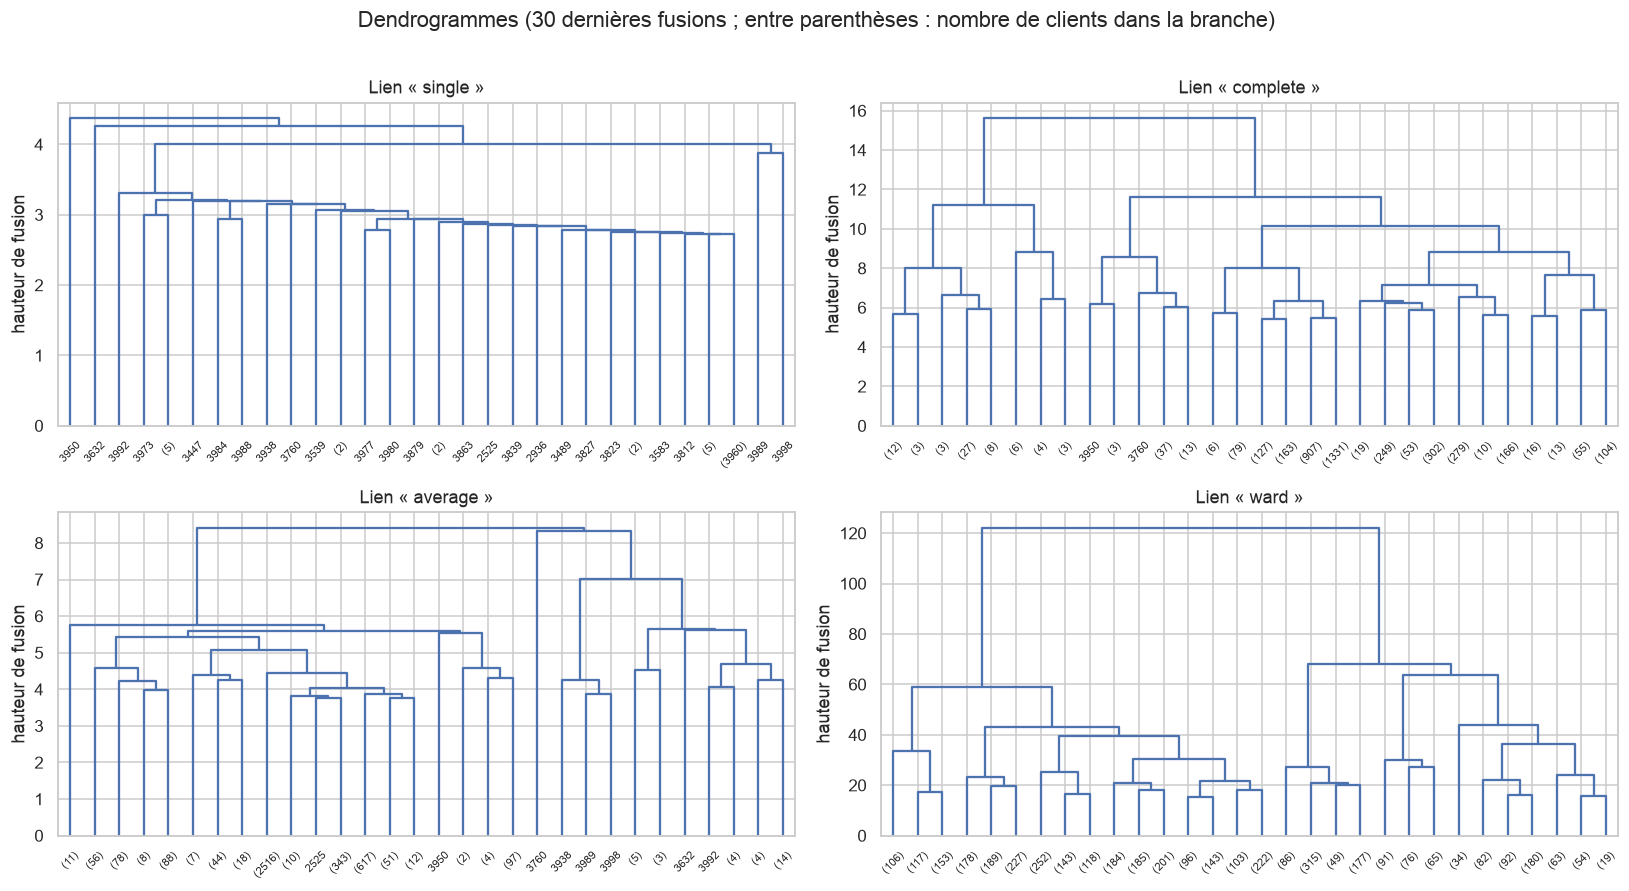

In [49]:
D_euc_cond = pdist(X_a.values, metric="euclidean")      # forme « condensée » attendue par scipy
links = {m: linkage(D_euc_cond, method=m) for m in ["single", "complete", "average"]}
links["ward"] = linkage(X_a.values, method="ward")

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (m, Zl) in zip(axes.ravel(), links.items()):
    dendrogram(Zl, truncate_mode="lastp", p=30, ax=ax, no_labels=False, leaf_font_size=7,
               color_threshold=0, above_threshold_color="#4C72B0")
    ax.set_title(f"Lien « {m} »"); ax.set_ylabel("hauteur de fusion")
plt.suptitle("Dendrogrammes (30 dernières fusions ; entre parenthèses : nombre de clients dans la branche)", y=1.01)
plt.tight_layout(); plt.savefig(FIG / "03_dendrogrammes.png", bbox_inches="tight"); plt.show()

In [50]:
# Que donne chaque lien si on coupe à 3 ou 4 clusters ?
rows = []
for m, Zl in links.items():
    coph, _ = cophenet(Zl, D_euc_cond)
    for k in [3, 4]:
        lab = fcluster(Zl, t=k, criterion="maxclust") - 1
        sizes = sorted(np.bincount(lab), reverse=True)
        rows.append({"lien": m, "k": k, "tailles des clusters": " / ".join(map(str, sizes)),
                     "plus petit cluster (%)": round(100 * sizes[-1] / n, 2),
                     "silhouette": round(silhouette_score(X_a, lab), 3),
                     "corrélation cophénétique": round(coph, 3)})
cah_tab = pd.DataFrame(rows)
cah_tab.to_csv(TAB / "03_comparatif_liens.csv", index=False)
cah_tab

,lien,k,tailles des clusters,plus petit cluster (%),silhouette,corrélation cophénétique
0,single,3,3998 / 1 / 1,0.02,0.423,0.698
1,single,4,3996 / 2 / 1 / 1,0.02,0.424,0.698
2,complete,3,3879 / 66 / 55,1.38,0.316,0.745
3,complete,4,3879 / 55 / 53 / 13,0.32,0.305,0.745
4,average,3,3964 / 35 / 1,0.02,0.489,0.829
5,average,4,3964 / 32 / 3 / 1,0.02,0.469,0.829
6,ward,3,2617 / 756 / 627,15.68,0.193,0.579
7,ward,4,2617 / 627 / 524 / 232,5.80,0.213,0.579


**Lecture des dendrogrammes et du tableau :**
- ***single*** : effet de chaîne caricatural. L'arbre « en escalier » détache les clients un par un : on obtient un cluster géant et des singletons. Inutilisable pour une segmentation.
- ***average*** et ***complete*** : un cluster rassemble plus de 95 % des clients, les autres sont minuscules. Ces liens isolent des **clients atypiques** plutôt qu'ils ne segmentent.
- ***Ward*** : le seul lien qui produit des groupes **équilibrés** et exploitables.

**Piège à retenir.** Les liens *single*, *average* et *complete* affichent ici les **meilleures silhouettes**, alors que leurs partitions sont sans intérêt. Isoler une poignée de points très éloignés suffit à obtenir une silhouette élevée. Un indice de qualité ne se lit donc jamais sans regarder la **taille des clusters**. On s'en souviendra au Jour 4.

La corrélation cophénétique mesure la fidélité de l'arbre aux distances d'origine ; elle est plus faible pour Ward, car ce lien déforme volontairement les distances pour équilibrer les groupes. Ce n'est pas un critère de qualité de la partition.

## A.2 Choix de la coupure (lien de Ward)
On coupe là où les fusions deviennent « coûteuses » : un **grand saut** de hauteur entre deux fusions successives signifie qu'on est en train de réunir deux groupes réellement différents.

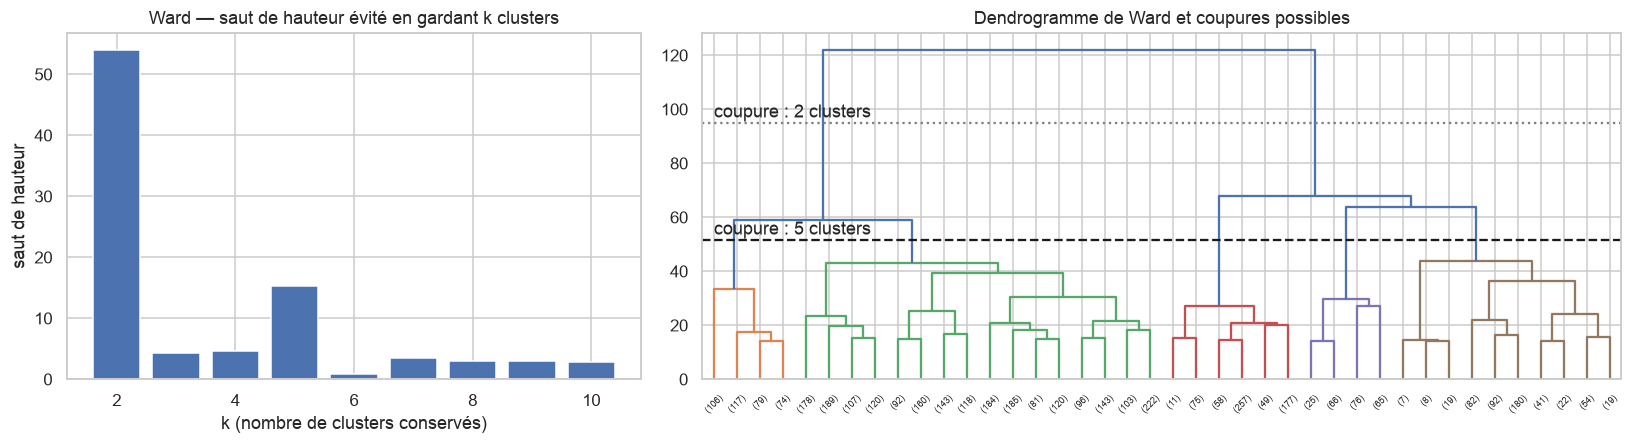

,nombre de clusters avant fusion,hauteur de fusion,saut par rapport à la fusion suivante
0,2,122.10,54.05
1,3,68.04,4.24
2,4,63.81,4.67
3,5,59.14,15.21
4,6,43.93,0.90
5,7,43.03,3.55
6,8,39.48,3.02
7,9,36.46,3.03
8,10,33.42,2.87


In [51]:
Zw = links["ward"]
last = Zw[-10:, 2][::-1]                   # hauteurs des 10 dernières fusions (de la dernière à la 10e)
jumps = pd.DataFrame({"nombre de clusters avant fusion": range(2, 12), "hauteur de fusion": last})
jumps["saut par rapport à la fusion suivante"] = jumps["hauteur de fusion"].diff(-1)
jumps = jumps.iloc[:9]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(jumps.iloc[:, 0], jumps.iloc[:, 2], color="#4C72B0")
axes[0].set_xlabel("k (nombre de clusters conservés)"); axes[0].set_ylabel("saut de hauteur")
axes[0].set_title("Ward — saut de hauteur évité en gardant k clusters")
cut5 = (Zw[-5, 2] + Zw[-4, 2]) / 2          # entre la fusion 6->5 et la fusion 5->4
dendrogram(Zw, truncate_mode="lastp", p=40, ax=axes[1], leaf_font_size=6, color_threshold=cut5)
axes[1].axhline(cut5, ls="--", color="k"); axes[1].text(5, cut5 * 1.04, "coupure : 5 clusters")
cut2 = (Zw[-2, 2] + Zw[-1, 2]) / 2
axes[1].axhline(cut2, ls=":", color="grey"); axes[1].text(5, cut2 * 1.02, "coupure : 2 clusters")
axes[1].set_title("Dendrogramme de Ward et coupures possibles")
plt.tight_layout(); plt.savefig(FIG / "03_ward_coupure.png", bbox_inches="tight"); plt.show()
jumps.round(2)

In [52]:
ward_rows = []
for k in range(2, 7):
    lab = fcluster(Zw, t=k, criterion="maxclust") - 1
    partitions[f"ward_k{k}"] = lab
    ward_rows.append({"k": k, "silhouette": silhouette_score(X_a, lab),
                      "tailles": " / ".join(map(str, sorted(np.bincount(lab), reverse=True)))})
pd.DataFrame(ward_rows).round(3)

,k,silhouette,tailles
0,2,0.234,2617 / 1383
1,3,0.193,2617 / 756 / 627
2,4,0.213,2617 / 627 / 524 / 232
3,5,0.180,2241 / 627 / 524 / 376 / 232
4,6,0.183,2241 / 627 / 490 / 376 / 232 / 34


**Choix de la coupure.** L'arbre propose deux coupures naturelles :
- **k = 2** : de loin le plus grand saut (54). C'est la séparation la plus nette, la même que celle trouvée par K-means.
- **k = 5** : second saut marqué (15). En dessous, les fusions coûtent peu ; passer de 5 à 4 clusters oblige à réunir deux groupes nettement différents.

Entre les deux (k = 3 ou 4), les sauts sont faibles : l'arbre ne distingue pas vraiment ces niveaux. La silhouette, elle, classe k = 2 en tête (0,23), puis **k = 4** (0,21) devant k = 5 (0,18).

→ Le dendrogramme et la silhouette ne désignent pas exactement le même niveau fin. On garde donc toutes les coupures de Ward de **k = 2 à 6** et on tranchera au Jour 4 avec l'ensemble des indices. Propriété utile de la CAH : ces partitions sont **emboîtées**. Le grand groupe de 2 617 clients reste intact de k = 2 à k = 4 ; seul l'autre groupe est subdivisé.

 A.3 CAH sur la distance de Gower
Les liens *average* et *complete* acceptent n'importe quelle dissimilarité. On refait donc la CAH avec Gower, mieux adaptée aux données mixtes.

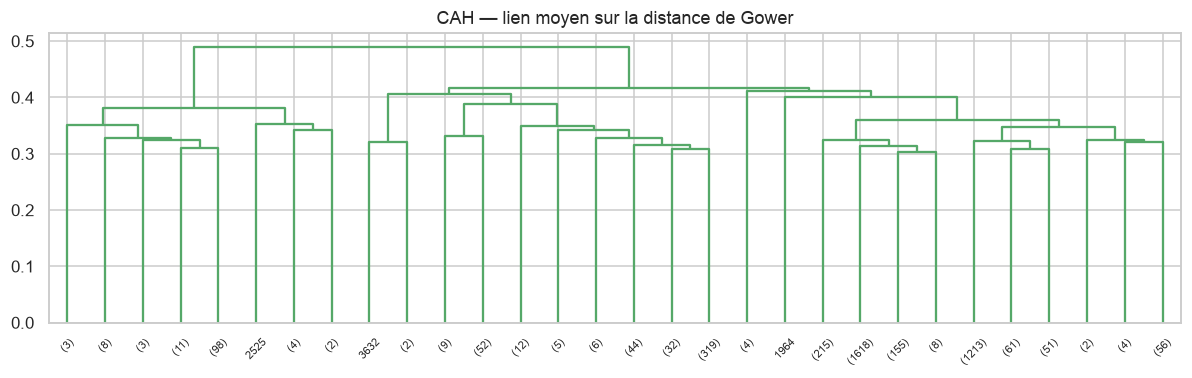

,k,silhouette (Gower),tailles
0,2,0.300,3870 / 130
1,3,0.228,3388 / 482 / 130
2,4,0.162,3384 / 482 / 130 / 4
3,5,0.154,3384 / 479 / 130 / 4 / 3
4,6,0.081,3383 / 479 / 130 / 4 / 3 / 1


In [53]:
D_gow_cond = squareform(D_gow, checks=False)
Zg = linkage(D_gow_cond, method="average")
fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(Zg, truncate_mode="lastp", p=30, ax=ax, leaf_font_size=7, color_threshold=0, above_threshold_color="#55A868")
ax.set_title("CAH — lien moyen sur la distance de Gower")
plt.tight_layout(); plt.savefig(FIG / "03_dendrogramme_gower.png", bbox_inches="tight"); plt.show()

gow_rows = []
for k in range(2, 7):
    lab = fcluster(Zg, t=k, criterion="maxclust") - 1
    partitions[f"cah_gower_k{k}"] = lab
    gow_rows.append({"k": k, "silhouette (Gower)": silhouette_score(D_gow, lab, metric="precomputed"),
                     "tailles": " / ".join(map(str, sorted(np.bincount(lab), reverse=True)))})
pd.DataFrame(gow_rows).round(3)

In [54]:
lab = partitions["cah_gower_k3"]
pd.crosstab(lab, X_mixed["poutcome"]).assign(effectif=np.bincount(lab))

poutcome,failure,nonexistent,success,effectif
cah_gower_k3,,,,
0,1,0,129,130
1,431,51,0,482
2,8,3379,1,3388


**Lecture.** Avec Gower, la CAH isole des groupes définis par l'**historique de contact** : un petit groupe de clients dont la campagne précédente a été un **succès**, un groupe de clients dont elle a été un **échec**, et la grande masse des clients jamais démarchés. Les groupes sont très déséquilibrés, mais ils ont un sens métier clair : ce sont des « niches » plutôt qu'une segmentation de toute la clientèle.

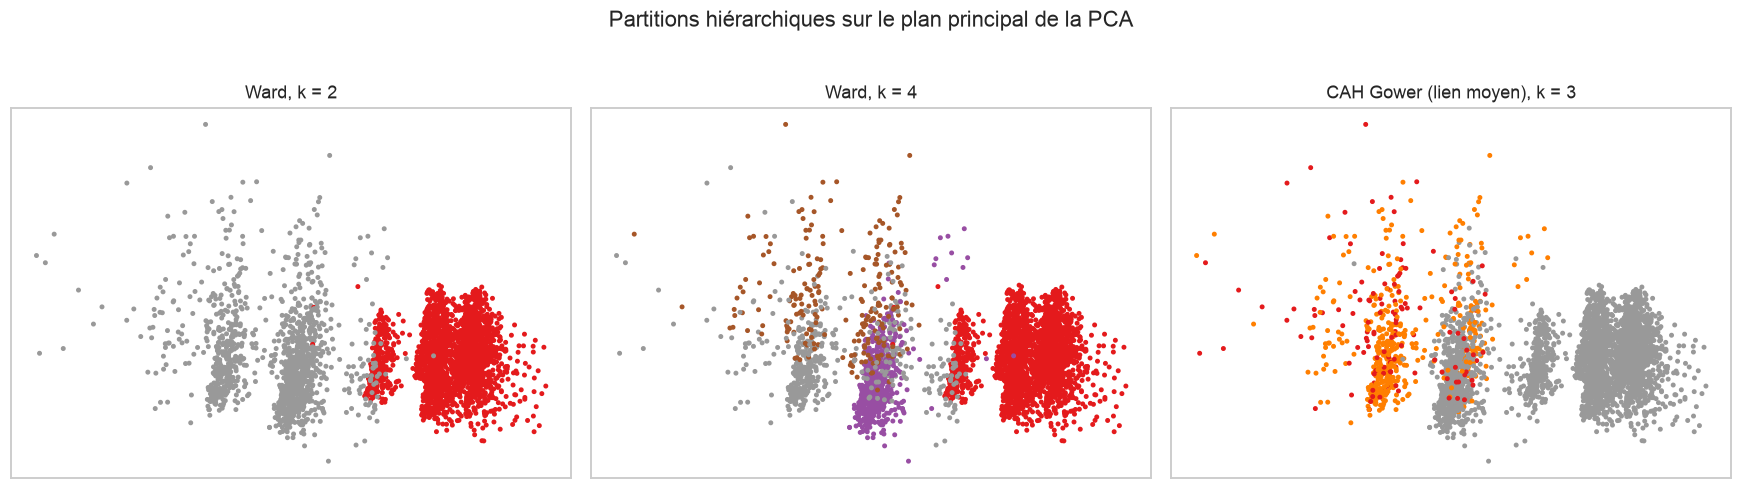

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (col, title) in zip(axes, [("ward_k2", "Ward, k = 2"), ("ward_k4", "Ward, k = 4"), ("cah_gower_k3", "CAH Gower (lien moyen), k = 3")]):
    ax.scatter(emb["pca"][:, 0], emb["pca"][:, 1], c=partitions[col], s=5, cmap="Set1")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Partitions hiérarchiques sur le plan principal de la PCA", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "03_cah_pca.png", bbox_inches="tight"); plt.show()

# Partie B — DBSCAN (clustering par densité)

**Principe.** Un cluster est une zone **dense** de l'espace, séparée des autres par des zones vides. Deux paramètres :
- **ε** (noté $d^*$ dans le cours) : rayon du voisinage ;
- **`min_samples`** (noté $e^*$) : nombre minimal de points dans ce voisinage pour être en zone dense.

Chaque point reçoit un statut :
- **point cœur** : au moins `min_samples` points (lui compris) à distance ≤ ε ;
- **point de bordure** : pas assez de voisins, mais situé dans le voisinage d'un point cœur ;
- **bruit** : ni l'un ni l'autre → il n'appartient à **aucun** cluster (étiquette −1).

Avantages : pas de $k$ à fixer, clusters de forme quelconque, détection des points isolés.

## B.1 Espace de travail
En grande dimension, toutes les distances se ressemblent et la notion de densité perd son sens. On applique donc DBSCAN sur les **5 premières composantes principales**.

In [56]:
pca5 = PCA(n_components=5, random_state=SEED).fit(X_a)
Z5 = pca5.transform(X_a)
print(f"Variance conservée par 5 composantes : {pca5.explained_variance_ratio_.sum():.1%}")

Variance conservée par 5 composantes : 66.1%


## B.2 Réglage des paramètres : graphique des k-distances
- `min_samples` : règle usuelle $2 \times$ dimension, soit **10**.
- ε : pour chaque client, on calcule la distance à son 10ᵉ plus proche voisin, puis on trie ces distances. Les points des zones denses ont une petite k-distance ; les points isolés une grande. Le **coude** de la courbe sépare les deux régimes : c'est la valeur de ε.

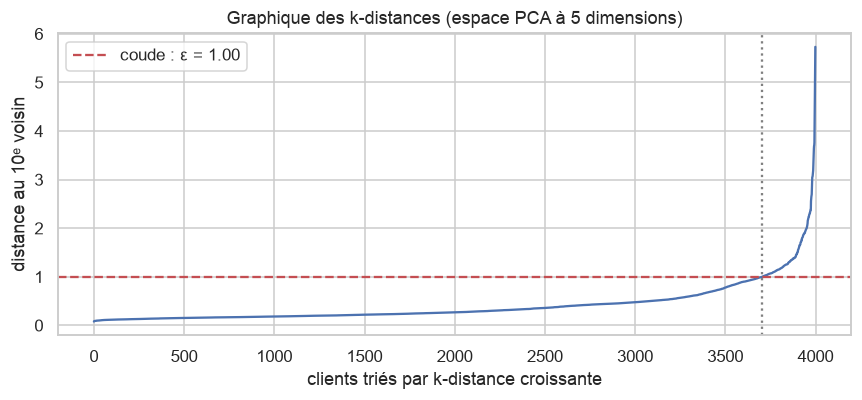

ε retenu = 0.995 ; 92.6 % des clients ont une k-distance inférieure


In [57]:
MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z5)     # le point lui-même compte, comme dans DBSCAN
kdist = np.sort(nn.kneighbors(Z5)[0][:, -1])
i_knee = knee_point(kdist)
EPS = float(kdist[i_knee])

plt.figure(figsize=(8, 3.8))
plt.plot(kdist, color="#4C72B0")
plt.axhline(EPS, ls="--", color="#C44E52", label=f"coude : ε = {EPS:.2f}")
plt.axvline(i_knee, ls=":", color="grey")
plt.xlabel("clients triés par k-distance croissante"); plt.ylabel(f"distance au {MIN_SAMPLES}ᵉ voisin")
plt.title("Graphique des k-distances (espace PCA à 5 dimensions)"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "03_k_distances.png", bbox_inches="tight"); plt.show()
print(f"ε retenu = {EPS:.3f} ; {100 * i_knee / n:.1f} % des clients ont une k-distance inférieure")

## B.3 Résultat : points cœur, bordure et bruit

In [58]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Z5)
lab_db = db.labels_
partitions["dbscan"] = lab_db

status = np.full(n, "bordure", dtype=object)
status[db.core_sample_indices_] = "cœur"
status[lab_db == -1] = "bruit"
n_clusters = lab_db.max() + 1
print(f"Nombre de clusters trouvés : {n_clusters}")
print(pd.Series(status).value_counts().rename("nb de clients").to_frame()
        .assign(pourcentage=lambda t: (100 * t["nb de clients"] / n).round(1)))
print("\nTailles des clusters :", sorted(np.bincount(lab_db[lab_db >= 0]), reverse=True))

Nombre de clusters trouvés : 8
         nb de clients  pourcentage
cœur              3703         92.6
bruit              150          3.8
bordure            147          3.7

Tailles des clusters : [np.int64(3264), np.int64(358), np.int64(113), np.int64(67), np.int64(15), np.int64(13), np.int64(10), np.int64(10)]


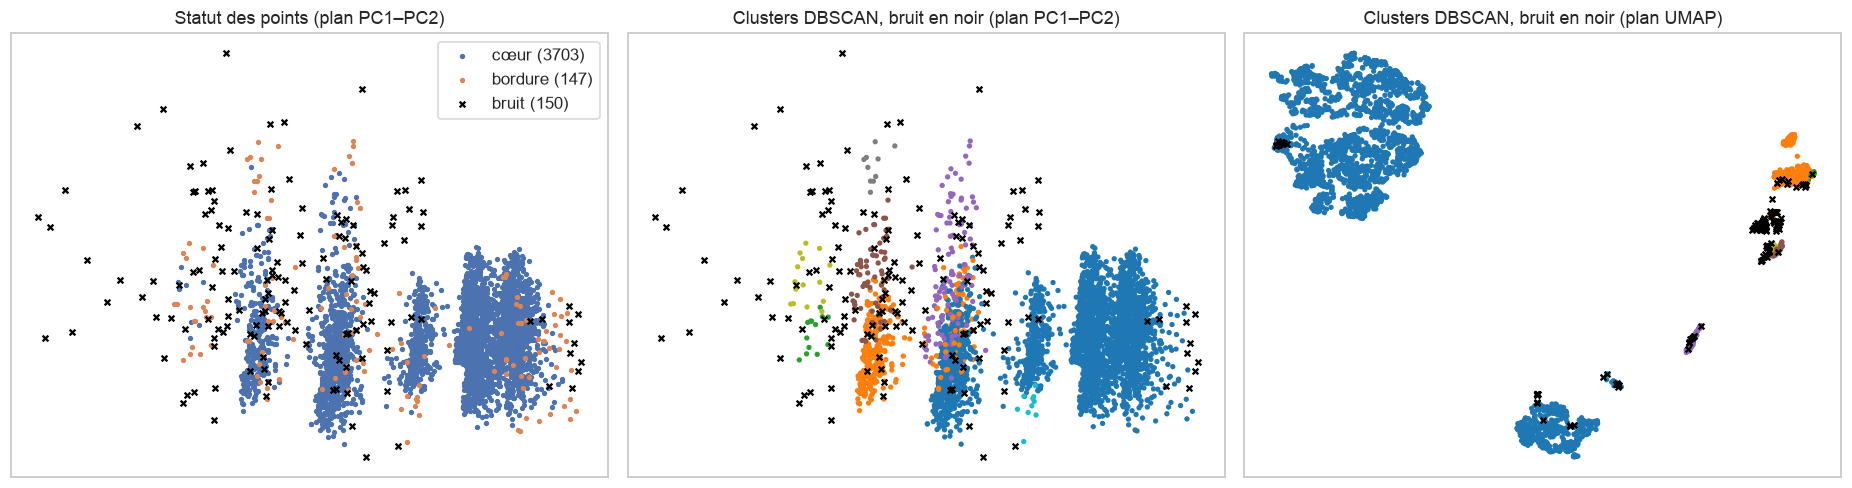

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
pal = {"cœur": "#4C72B0", "bordure": "#DD8452", "bruit": "black"}
for s in ["cœur", "bordure", "bruit"]:
    m = status == s
    axes[0].scatter(Z5[m, 0], Z5[m, 1], s=6 if s != "bruit" else 14, c=pal[s], label=f"{s} ({m.sum()})",
                    marker="o" if s != "bruit" else "x")
axes[0].set_title("Statut des points (plan PC1–PC2)"); axes[0].legend()
for ax, (Z, name) in zip(axes[1:], [(Z5[:, :2], "plan PC1–PC2"), (emb["umap"], "plan UMAP")]):
    m = lab_db >= 0
    ax.scatter(Z[m, 0], Z[m, 1], c=lab_db[m], s=6, cmap="tab10")
    ax.scatter(Z[~m, 0], Z[~m, 1], c="black", s=14, marker="x")
    ax.set_title(f"Clusters DBSCAN, bruit en noir ({name})")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "03_dbscan.png", bbox_inches="tight"); plt.show()

In [60]:
# Sensibilité aux paramètres
sens = []
for eps in [0.6, 0.8, EPS, 1.2, 1.5]:
    for ms in [5, 10, 20]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z5)
        sizes = np.bincount(l[l >= 0]) if (l >= 0).any() else np.array([0])
        sens.append({"ε": round(eps, 2), "min_samples": ms, "nb clusters": int(l.max() + 1),
                     "bruit (%)": round(100 * (l == -1).mean(), 1),
                     "plus grand cluster (%)": round(100 * sizes.max() / n, 1)})
sens = pd.DataFrame(sens)
sens.to_csv(TAB / "03_dbscan_sensibilite.csv", index=False)
sens.pivot(index="ε", columns="min_samples", values=["nb clusters", "bruit (%)", "plus grand cluster (%)"])

nb clusters            bruit (%)              \
min_samples          5     10   20        5     10    20   
ε                                                          
0.6                23.0  11.0  6.0       7.7  12.6  18.4   
0.8                19.0   7.0  8.0       4.2   9.0  12.0   
1.0                10.0   8.0  4.0       2.1   3.8   7.8   
1.2                 9.0   6.0  4.0       1.5   2.4   4.8   
1.5                 6.0   7.0  2.0       0.9   1.4   3.5   

            plus grand cluster (%)              
min_samples                     5     10    20  
ε                                               
0.6                           30.4  30.3  29.4  
0.8                           64.9  63.8  54.6  
1.0                           84.9  81.6  79.3  
1.2                           85.0  84.9  81.4  
1.5                           85.3  85.1  85.0

**Lecture.**
- DBSCAN trouve 8 clusters, dont **un très grand** (82 % des clients), quelques petits îlots denses et 3,8 % de bruit.
- Le résultat dépend fortement de ε : plus petit, il émiette les données en nombreux îlots avec beaucoup de bruit ; plus grand, tout fusionne en un bloc.
- Conclusion : dans cet espace, la clientèle forme une **masse continue**, sans « vallées » vides entre des groupes. DBSCAN n'est donc pas l'outil adapté pour **segmenter** cette clientèle. Il est en revanche très utile pour **repérer les clients atypiques**.

## B.4 Qui sont les points de bruit ? (bonus : détection d'anomalies)

In [61]:
noise = lab_db == -1
prof = pd.DataFrame({
    "bruit": X_mixed[noise][pp.ACTIVE_NUM].mean(),
    "autres clients": X_mixed[~noise][pp.ACTIVE_NUM].mean()}).round(2)
prof.loc["% contacted_before = yes"] = [100 * (X_mixed[noise]["contacted_before"] == "yes").mean(),
                                        100 * (X_mixed[~noise]["contacted_before"] == "yes").mean()]
prof.loc["% poutcome = success"] = [100 * (X_mixed[noise]["poutcome"] == "success").mean(),
                                    100 * (X_mixed[~noise]["poutcome"] == "success").mean()]
prof.loc["% job = retired ou student"] = [100 * X_mixed[noise]["job"].isin(["retired", "student"]).mean(),
                                          100 * X_mixed[~noise]["job"].isin(["retired", "student"]).mean()]
prof.loc["nb de clients"] = [noise.sum(), (~noise).sum()]
prof.round(2)

,bruit,autres clients
age,49.28,39.84
campaign,3.46,2.40
previous,1.55,0.13
cons.price.idx,93.63,93.56
cons.conf.idx,-39.29,-40.54
euribor3m,1.18,3.72
% contacted_before = yes,42.00,2.00
% poutcome = success,36.67,1.95
% job = retired ou student,34.00,5.45
nb de clients,150.00,3850.00


Les points de bruit ne sont pas des erreurs de saisie. Ce sont des clients au **profil rare** : plus âgés (49 ans en moyenne contre 40), déjà démarchés lors de campagnes précédentes (42 % contre 2 %), bien plus souvent retraités ou étudiants (34 % contre 5 %). Pour la banque, ce sont des profils à traiter à part, pas à supprimer.

# Partie C — Limites de K-means face à DBSCAN

## C.1 Démonstration sur un cas d'école
Deux croissants imbriqués et quelques points isolés : des clusters **non convexes**.

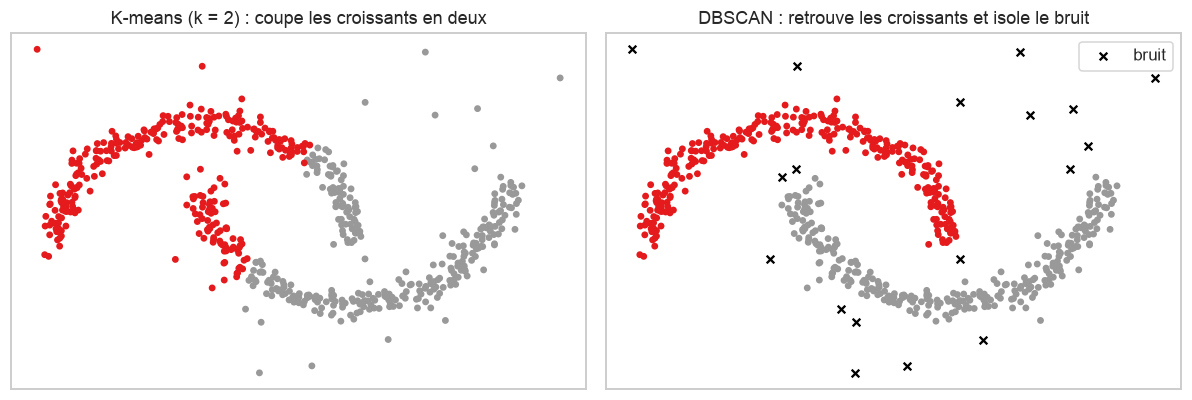

In [62]:
Xm, _ = make_moons(n_samples=600, noise=0.06, random_state=SEED)
rng = np.random.default_rng(SEED)
Xm = np.vstack([Xm, rng.uniform([-1.5, -1.2], [2.5, 1.7], size=(25, 2))])     # points isolés ajoutés
lab_km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Xm)
lab_d = DBSCAN(eps=0.15, min_samples=5).fit_predict(Xm)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(Xm[:, 0], Xm[:, 1], c=lab_km, s=12, cmap="Set1"); axes[0].set_title("K-means (k = 2) : coupe les croissants en deux")
m = lab_d >= 0
axes[1].scatter(Xm[m, 0], Xm[m, 1], c=lab_d[m], s=12, cmap="Set1")
axes[1].scatter(Xm[~m, 0], Xm[~m, 1], c="black", marker="x", s=25, label="bruit")
axes[1].set_title("DBSCAN : retrouve les croissants et isole le bruit"); axes[1].legend()
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "03_kmeans_vs_dbscan_demo.png", bbox_inches="tight"); plt.show()

K-means affecte chaque point au **centre le plus proche** : ses frontières sont des droites (cellules de Voronoï), ses clusters sont forcément convexes. Il coupe donc les croissants en deux et il range les points isolés dans un cluster, ce qui déplace les centres. DBSCAN suit la densité : il retrouve les deux formes et écarte le bruit.

## C.2 Et sur nos données bancaires ?

                  count  mean   50%   max
statut DBSCAN                            
bruit             150.0  4.26  3.98  10.6
dans un cluster  3850.0  2.35  2.25   5.8


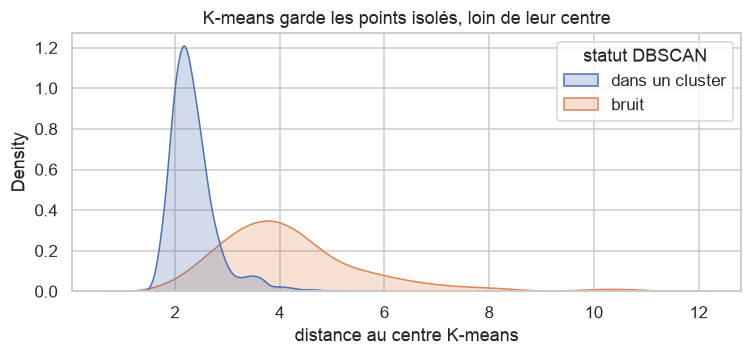

In [63]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_a)
dist_centre = np.linalg.norm(X_a.values - km4.cluster_centers_[km4.labels_], axis=1)
cmp = pd.DataFrame({"statut DBSCAN": np.where(noise, "bruit", "dans un cluster"), "distance au centre K-means": dist_centre})
print(cmp.groupby("statut DBSCAN")["distance au centre K-means"].describe()[["count", "mean", "50%", "max"]].round(2))

plt.figure(figsize=(7, 3.4))
sns.kdeplot(data=cmp, x="distance au centre K-means", hue="statut DBSCAN", common_norm=False, fill=True)
plt.title("K-means garde les points isolés, loin de leur centre")
plt.tight_layout(); plt.savefig(FIG / "03_distance_centres.png", bbox_inches="tight"); plt.show()

**Discussion.**

| | K-means | DBSCAN |
|---|---|---|
| Nombre de clusters | à fixer | trouvé automatiquement |
| Forme des clusters | convexe, sphérique | quelconque |
| Points isolés | **forcés** dans un cluster ; ils tirent les centres vers eux | étiquetés « bruit » |
| Densités différentes | sans objet | **difficulté** : un seul ε pour tout l'espace |
| Résultat sur nos données | groupes équilibrés et exploitables | 1 cluster géant + îlots + bruit |

- Les clients que DBSCAN classe en bruit sont, pour K-means, des points **presque deux fois plus éloignés de leur centre** que les autres (4,3 contre 2,4 en moyenne) : K-means les a rangés de force dans un segment qui leur ressemble peu.
- Inversement, DBSCAN ne sait pas découper une masse continue : il ne fournit pas de segmentation utilisable ici.
- Les deux méthodes sont donc **complémentaires** : K-means (ou Ward) pour segmenter, DBSCAN pour signaler les clients atypiques.

## Bilan du Jour 3
1. **CAH** : le lien change tout. *Single* produit un effet de chaîne, *average* et *complete* isolent des atypiques, **Ward** donne des groupes équilibrés. L'arbre suggère k = 2 puis k = 5 ; la silhouette préfère k = 2 puis k = 4. Décision au Jour 4.
2. **CAH sur Gower** : fait ressortir des niches liées à l'historique de contact.
3. **DBSCAN** : ε réglé par le coude des k-distances, `min_samples` = 10. Un cluster dominant, quelques îlots, du bruit interprétable comme clients atypiques.
4. Leçon de méthode : une **silhouette élevée ne suffit pas** ; il faut toujours vérifier la taille des clusters.

In [64]:
for m in ["single", "complete", "average"]:
    for k in range(2, 7):                    # mêmes valeurs de k que les autres méthodes (Jour 4)
        partitions[f"cah_{m}_k{k}"] = fcluster(links[m], t=k, criterion="maxclust") - 1
partitions.to_csv(LAB / "partitions_j3.csv")
print("Partitions enregistrées :", list(partitions.columns))

Partitions enregistrées : ['ward_k2', 'ward_k3', 'ward_k4', 'ward_k5', 'ward_k6', 'cah_gower_k2', 'cah_gower_k3', 'cah_gower_k4', 'cah_gower_k5', 'cah_gower_k6', 'dbscan', 'cah_single_k2', 'cah_single_k3', 'cah_single_k4', 'cah_single_k5', 'cah_single_k6', 'cah_complete_k2', 'cah_complete_k3', 'cah_complete_k4', 'cah_complete_k5', 'cah_complete_k6', 'cah_average_k2', 'cah_average_k3', 'cah_average_k4', 'cah_average_k5', 'cah_average_k6']


# Jour 4 — Validation des clusters

**Objectifs du jour (Chapitre 4)**

| Partie | Contenu |
|---|---|
| A | Indices **internes** : silhouette, Davies-Bouldin, Dunn — toutes les méthodes, plusieurs valeurs de k |
| B | Indices **externes** par rapport à `y` : ARI, NMI, homogénéité, complétude, V-mesure |
| C | Étude de **stabilité** : 20 graines et bootstrap |
| D | Tableau de synthèse et **choix de la solution finale** |

C'est le seul notebook où la vérité terrain `y` est utilisée, et uniquement pour **évaluer** des partitions déjà construites.

In [65]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure,
                             pairwise_distances)

from src.config import SEED, FIG, TAB, LAB, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix, dunn_index

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

d = pp.prepare_all()
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
X = X_a.values
n = len(X)
D_euc = pairwise_distances(X)
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)

# Toutes les partitions construites aux Jours 2 et 3
P = pd.concat([pd.read_csv(LAB / "partitions_j2.csv", index_col=0),
               pd.read_csv(LAB / "partitions_j3.csv", index_col=0)], axis=1)
assert (P.index == X_a.index).all()
print(f"{P.shape[1]} partitions à évaluer sur {n} clients")

NAMES = {"kmeans": "K-means", "kmedoids": "K-medoids (Gower)", "kprototypes": "K-prototypes", "gmm": "GMM",
         "ward": "CAH Ward", "cah_gower": "CAH moyen (Gower)", "cah_single": "CAH single",
         "cah_complete": "CAH complete", "cah_average": "CAH average", "dbscan": "DBSCAN"}

46 partitions à évaluer sur 4000 clients


# Partie A — Indices internes
Ils jugent une partition **sans information extérieure**, sur deux critères : la **compacité** (les membres d'un cluster sont proches) et la **séparation** (les clusters sont éloignés les uns des autres).

| Indice | Définition | Lecture |
|---|---|---|
| **Silhouette** | pour chaque point, $s = \dfrac{b - a}{\max(a, b)}$, où $a$ = distance moyenne aux points de son cluster et $b$ = distance moyenne aux points du cluster voisin le plus proche ; on fait la moyenne des $s$ | entre −1 et 1, **plus haut = mieux** |
| **Davies-Bouldin** | moyenne, sur les clusters, du pire rapport (dispersion interne de deux clusters) / (distance entre leurs centres) | ≥ 0, **plus bas = mieux** |
| **Dunn** | (plus petite distance entre deux clusters) / (plus grand diamètre d'un cluster) | ≥ 0, **plus haut = mieux** ; très sensible aux points extrêmes |

La silhouette est calculée dans les deux espaces (euclidien et Gower) pour ne favoriser aucune famille de méthodes. L'indice de Dunn est une **implémentation personnelle** (`src/clustering_utils.py`).

In [66]:
def internal_indices(labels):
    """Indices internes d'une partition (le bruit DBSCAN, étiqueté -1, est exclu)."""
    labels = np.asarray(labels)
    m = labels >= 0
    lab = labels[m]
    sizes = np.bincount(lab)
    sizes = sizes[sizes > 0]
    return {
        "nb clusters": len(sizes),
        "plus petit cluster (%)": 100 * sizes.min() / n,
        "silhouette eucl.": silhouette_score(X[m], lab),
        "silhouette Gower": silhouette_score(D_gow[np.ix_(m, m)], lab, metric="precomputed"),
        "Davies-Bouldin": davies_bouldin_score(X[m], lab),
        "Dunn": dunn_index(D_euc[np.ix_(m, m)], lab),
    }

def split_name(col):
    key, _, k = col.rpartition("_k")
    return (NAMES[key], int(k)) if key else (NAMES[col], None)

rows = []
for col in P.columns:
    method, k = split_name(col)
    rows.append({"partition": col, "méthode": method, **internal_indices(P[col].values)})
internal = pd.DataFrame(rows)
internal.to_csv(TAB / "04_indices_internes.csv", index=False)
internal.drop(columns="partition").style.format(precision=3).format({"plus petit cluster (%)": "{:.1f}"}).hide(axis="index")

méthode,nb clusters,plus petit cluster (%),silhouette eucl.,silhouette Gower,Davies-Bouldin,Dunn
K-means,2,33.8,0.236748,0.233115,1.882268,0.038009
K-means,3,14.2,0.185603,0.174976,1.917559,0.065288
K-means,4,7.9,0.182093,0.120695,1.841732,0.032644
K-means,5,5.9,0.199496,0.102398,1.702641,0.036580
K-means,6,5.8,0.146414,0.095679,1.872661,0.008079
K-medoids (Gower),2,45.5,0.110528,0.180106,2.539247,0.024600
K-medoids (Gower),3,26.8,0.039267,0.111181,3.731248,0.019526
K-medoids (Gower),4,21.8,0.042478,0.103442,3.860113,0.007945
K-medoids (Gower),5,11.8,0.033394,0.113080,3.426658,0.019201
K-medoids (Gower),6,10.4,0.014138,0.106236,3.921939,0.026147


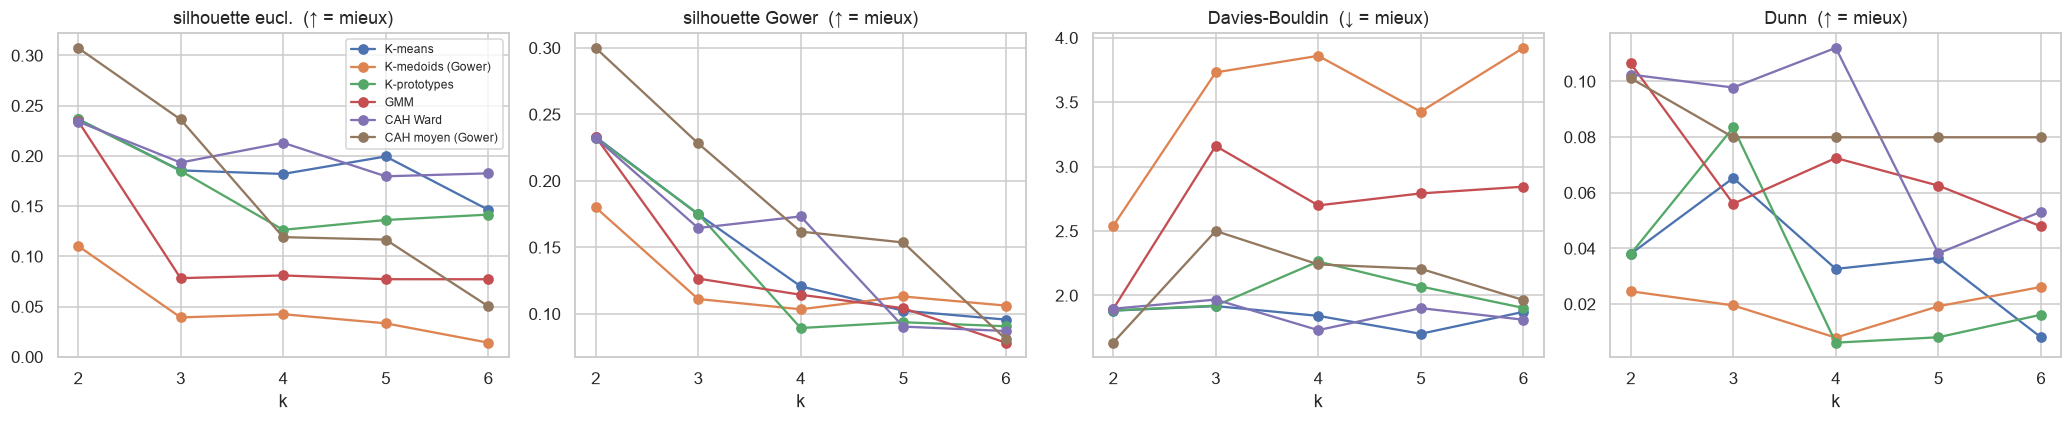

In [67]:
main = ["K-means", "K-medoids (Gower)", "K-prototypes", "GMM", "CAH Ward", "CAH moyen (Gower)"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (idx, sense) in zip(axes, [("silhouette eucl.", "↑"), ("silhouette Gower", "↑"), ("Davies-Bouldin", "↓"), ("Dunn", "↑")]):
    for mth in main:
        sub = internal[internal["méthode"] == mth]
        ax.plot(sub["nb clusters"], sub[idx], "o-", label=mth)
    ax.set_title(f"{idx}  ({sense} = mieux)"); ax.set_xlabel("k"); ax.set_xticks(range(2, 7))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_indices_internes.png", bbox_inches="tight"); plt.show()

**Lecture des indices internes.**
- **k = 2 est la structure la plus nette** pour presque toutes les méthodes (silhouette ≈ 0,23–0,24). K-means, K-prototypes, GMM et Ward trouvent la même coupure.
- Pour k = 3 et 4, **Ward** est la méthode qui se dégrade le moins : meilleure silhouette euclidienne (0,19 puis 0,21), Davies-Bouldin le plus bas à k = 4 (1,73) et meilleur indice de Dunn.
- **K-medoids (Gower)** et **GMM** (pour k ≥ 3) sont nettement en retrait sur tous les indices.
- **Attention aux fausses bonnes notes** : les liens *single*, *average*, *complete* et la CAH sur Gower obtiennent les silhouettes les plus hautes du tableau… avec un cluster qui contient plus de 85 % des clients. Leur « plus petit cluster » pèse moins de 4 %. Ces partitions isolent des atypiques, elles ne segmentent pas. Même remarque pour DBSCAN.
- Les valeurs absolues restent **modestes** (silhouette < 0,25) : les segments se chevauchent, comme l'annonçaient les projections du Jour 1. C'est normal pour des données de clientèle.

# Partie B — Indices externes (par rapport à `y`)
On compare maintenant chaque partition à la variable `y` (souscription oui / non), que les algorithmes n'ont jamais vue.

| Indice | Idée | Valeurs |
|---|---|---|
| **ARI** (indice de Rand ajusté) | proportion de paires de clients classées de la même façon, corrigée du hasard | 0 = hasard, 1 = accord parfait |
| **NMI** | information mutuelle entre partition et `y`, normalisée | 0 à 1 |
| **Homogénéité** | chaque cluster ne contient-il qu'une seule classe de `y` ? | 0 à 1 |
| **Complétude** | tous les clients d'une même classe sont-ils dans le même cluster ? | 0 à 1 |
| **V-mesure** | moyenne harmonique homogénéité / complétude | 0 à 1 |

**Précaution de lecture.** `y` a deux classes très déséquilibrées (11 % de « oui »). Une segmentation de clientèle n'a aucune raison de reproduire ce découpage : on s'attend à des valeurs **faibles**. Ces indices servent ici à comparer les méthodes entre elles et à vérifier que les segments ont un lien avec le comportement de souscription. Pour le lire plus concrètement, on ajoute le **taux de souscription** du segment le moins et le plus réceptif.

In [68]:
y_bin = (y == "yes").astype(int).values
rows = []
for col in P.columns:
    lab = P[col].values
    h, c, v = homogeneity_completeness_v_measure(y_bin, lab)
    rates = pd.Series(y_bin).groupby(lab).mean()
    rates = rates[rates.index >= 0]
    rows.append({"partition": col, "méthode": split_name(col)[0], "nb clusters": int((np.unique(lab) >= 0).sum()),
                 "ARI": adjusted_rand_score(y_bin, lab), "NMI": normalized_mutual_info_score(y_bin, lab),
                 "homogénéité": h, "complétude": c, "V-mesure": v,
                 "taux souscr. min (%)": 100 * rates.min(), "taux souscr. max (%)": 100 * rates.max()})
external = pd.DataFrame(rows)
external.to_csv(TAB / "04_indices_externes.csv", index=False)
external.drop(columns="partition").style.format(precision=3).format(
    {"taux souscr. min (%)": "{:.1f}", "taux souscr. max (%)": "{:.1f}"}).hide(axis="index")

méthode,nb clusters,ARI,NMI,homogénéité,complétude,V-mesure,taux souscr. min (%),taux souscr. max (%)
K-means,2,0.104376,0.059348,0.083539,0.046022,0.059348,5.6,22.4
K-means,3,0.095807,0.046397,0.085651,0.031816,0.046397,4.9,24.9
K-means,4,0.056570,0.037360,0.081051,0.024275,0.037360,4.1,25.0
K-means,5,0.088640,0.044996,0.102056,0.028861,0.044996,3.7,39.6
K-means,6,0.036719,0.033623,0.092841,0.020529,0.033623,4.6,39.7
K-medoids (Gower),2,-0.003102,0.034497,0.050989,0.026066,0.034497,5.0,16.5
K-medoids (Gower),3,0.014908,0.018208,0.037168,0.012058,0.018208,6.3,19.6
K-medoids (Gower),4,0.001609,0.015930,0.039245,0.009993,0.015930,4.4,19.3
K-medoids (Gower),5,0.016732,0.025239,0.068031,0.015494,0.025239,4.7,22.6
K-medoids (Gower),6,0.000870,0.015263,0.045368,0.009175,0.015263,4.2,20.8


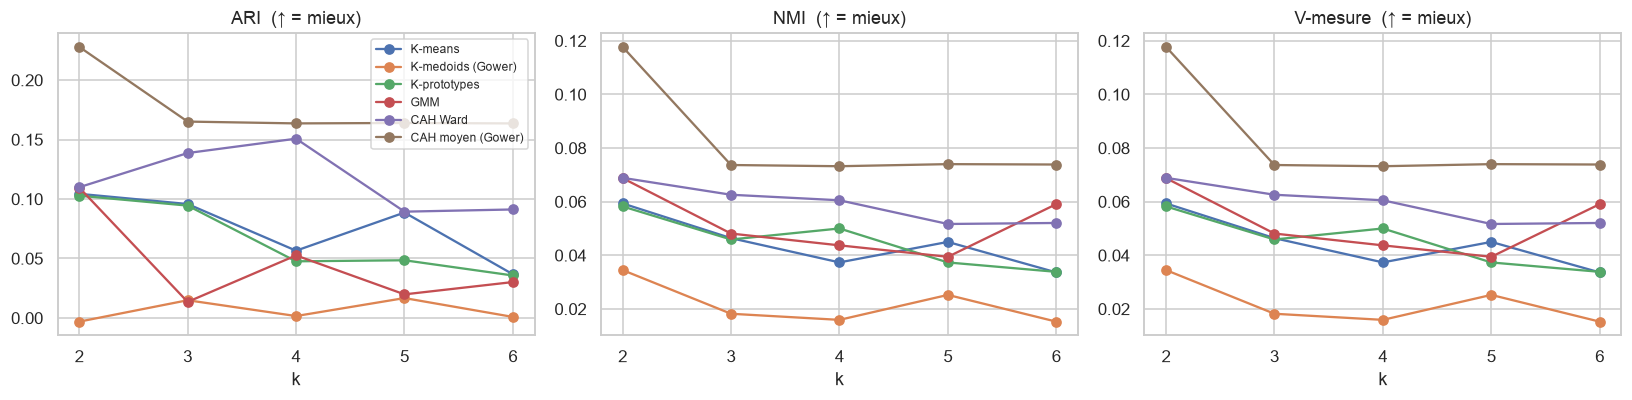

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, idx in zip(axes, ["ARI", "NMI", "V-mesure"]):
    for mth in main:
        sub = external[external["méthode"] == mth]
        ax.plot(sub["nb clusters"], sub[idx], "o-", label=mth)
    ax.set_title(f"{idx}  (↑ = mieux)"); ax.set_xlabel("k"); ax.set_xticks(range(2, 7))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_indices_externes.png", bbox_inches="tight"); plt.show()

**Lecture des indices externes.**
- Comme prévu, les valeurs sont faibles (ARI < 0,25) : **les segments ne sont pas un classifieur de `y`**, et ce n'est pas leur rôle.
- Elles ne sont pourtant pas nulles : les segments séparent des clients dont le taux de souscription va de **4–6 %** à **40 % et plus**, alors que la moyenne est de 11 %. La segmentation est donc **utile pour le ciblage**.
- Pour les partitions équilibrées, l'**homogénéité** est supérieure à la **complétude** : les souscripteurs sont répartis dans plusieurs segments, ce qui pénalise la complétude.
- Parmi les méthodes équilibrées, **Ward** obtient les meilleurs ARI / NMI / V-mesure pour k = 3 et 4. **K-medoids (Gower)** est proche de zéro : ses groupes n'ont pas de lien avec la souscription.
- Les partitions « niches » (CAH sur Gower, liens *complete*) ont un bon ARI parce qu'elles isolent le petit groupe des anciens succès, très souscripteur. Information précieuse, mais qui ne décrit que 3 % de la clientèle.

# Partie C — Étude de stabilité
Une bonne segmentation ne doit pas dépendre du hasard. Deux tests, mesurés par l'**ARI entre exécutions** (1 = partitions identiques) :
1. **20 graines** : K-means est relancé 20 fois avec une seule initialisation aléatoire à chaque fois → sensibilité à l'**initialisation**.
2. **Bootstrap** : 20 rééchantillons tirés avec remise ; on reclasse chaque rééchantillon et on compare à la partition de référence sur les mêmes clients → sensibilité aux **données**.

Le bootstrap est appliqué à K-means et à Ward (Ward est déterministe : le test des graines ne le concerne pas).

In [70]:
N_RUNS, B = 20, 20
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, n, n) for _ in range(B)]          # mêmes rééchantillons pour toutes les méthodes

stab_rows, seed_detail = [], []
for k in range(2, 7):
    # 1) 20 graines, une seule initialisation par exécution
    runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X) for s in range(N_RUNS)]
    aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(N_RUNS) for j in range(i + 1, N_RUNS)]
    seed_detail += [{"k": k, "ARI": a} for a in aris]
    # 2) bootstrap
    ref_km = P[f"kmeans_k{k}"].values
    ref_wd = P[f"ward_k{k}"].values
    b_km = [adjusted_rand_score(ref_km[ib], KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X[ib])) for ib in boot_idx]
    b_wd = [adjusted_rand_score(ref_wd[ib], AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X[ib])) for ib in boot_idx]
    stab_rows.append({"k": k, "K-means graines : ARI moyen": np.mean(aris), "K-means graines : ARI min": np.min(aris),
                      "K-means bootstrap : ARI moyen": np.mean(b_km), "K-means bootstrap : écart-type": np.std(b_km),
                      "Ward bootstrap : ARI moyen": np.mean(b_wd), "Ward bootstrap : écart-type": np.std(b_wd)})
stab = pd.DataFrame(stab_rows)
stab.to_csv(TAB / "04_stabilite.csv", index=False)
stab.round(3)

,k,K-means graines : ARI moyen,K-means graines : ARI min,K-means bootstrap : ARI moyen,K-means bootstrap : écart-type,Ward bootstrap : ARI moyen,Ward bootstrap : écart-type
0,2,0.882,0.336,0.997,0.003,0.987,0.022
1,3,0.691,0.347,0.976,0.076,0.956,0.037
2,4,0.787,0.606,0.715,0.249,0.932,0.086
3,5,0.774,0.495,0.648,0.211,0.861,0.023
4,6,0.730,0.408,0.971,0.013,0.713,0.155


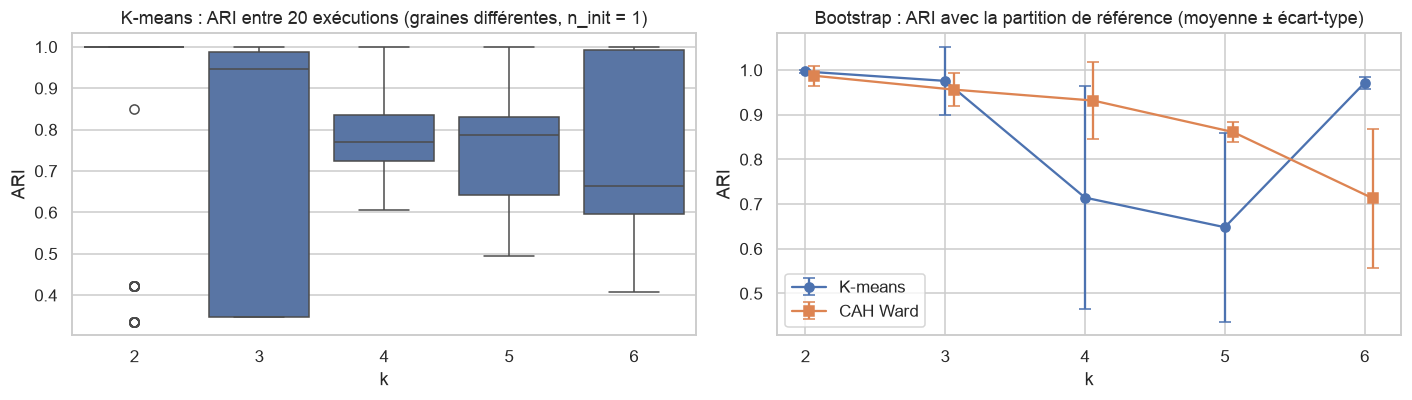

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(data=pd.DataFrame(seed_detail), x="k", y="ARI", ax=axes[0], color="#4C72B0")
axes[0].set_title("K-means : ARI entre 20 exécutions (graines différentes, n_init = 1)")
axes[1].errorbar(stab["k"], stab["K-means bootstrap : ARI moyen"], yerr=stab["K-means bootstrap : écart-type"], fmt="o-", capsize=4, label="K-means")
axes[1].errorbar(stab["k"] + 0.06, stab["Ward bootstrap : ARI moyen"], yerr=stab["Ward bootstrap : écart-type"], fmt="s-", capsize=4, label="CAH Ward")
axes[1].set_title("Bootstrap : ARI avec la partition de référence (moyenne ± écart-type)")
axes[1].set_xlabel("k"); axes[1].set_ylabel("ARI"); axes[1].set_xticks(range(2, 7)); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "04_stabilite.png", bbox_inches="tight"); plt.show()

**Lecture de la stabilité.**
- **Graines (K-means, une seule initialisation)** : l'ARI moyen entre exécutions va de 0,69 à 0,88, avec des minimums autour de 0,35. Une initialisation unique peut donc tomber dans un mauvais optimum local : cela justifie `n_init = 10` (on garde la meilleure de 10 initialisations), utilisé partout ailleurs dans le projet.
- **Bootstrap, K-means** : très stable pour k = 2 (0,997) et k = 3 (0,98), mais **instable pour k = 4 et 5** (0,72 et 0,65, avec un écart-type de plus de 0,2) : selon l'échantillon tiré, K-means ne découpe pas les mêmes groupes.
- **Bootstrap, Ward** : la stabilité décroît régulièrement avec k, sans accident : 0,99 (k = 2), 0,96 (k = 3), **0,93 (k = 4)**, 0,86 (k = 5), 0,71 (k = 6).
- À **k = 4**, Ward est donc nettement plus stable que K-means (0,93 contre 0,72).

## D.1 Critères de sélection
Aucun indice ne suffit seul (on l'a vu avec les partitions dégénérées). La sélection se fait en quatre temps :

1. **Filtre métier** — le sujet demande 3 à 4 recommandations, une par segment : on retient **k = 3 ou 4**. De plus, chaque segment doit représenter **au moins 5 % des clients** pour justifier une action marketing dédiée.
2. **Classement sur les indices internes uniquement** — chaque candidat est classé sur 4 indices (silhouette euclidienne, silhouette Gower, Davies-Bouldin, Dunn) ; on calcule son **rang moyen** (1 = meilleur). La variable `y` n'intervient **pas** dans ce choix : sinon, constater ensuite que les segments séparent bien les souscripteurs serait un raisonnement circulaire.
3. **Contrôle de stabilité** du candidat en tête.
4. **Vérification a posteriori** avec les indices externes (ARI, V-mesure) : ils ne servent pas à choisir, seulement à vérifier que le choix a un sens vis-à-vis du comportement de souscription. On vérifie aussi que les ajouter au classement ne changerait pas le vainqueur.


In [72]:
synth = internal.merge(external.drop(columns=["méthode", "nb clusters"]), on="partition")
synth.to_csv(TAB / "04_synthese_complete.csv", index=False)

cand = synth[synth["nb clusters"].isin([3, 4]) & (synth["plus petit cluster (%)"] >= 5)
             & ~synth["méthode"].isin(["DBSCAN"])].copy()

def mean_rank(df, higher, lower=("Davies-Bouldin",)):
    """Rang moyen sur plusieurs indices (1 = meilleur) ; `lower` = indices où plus bas = mieux."""
    r = pd.concat([df[list(higher)].rank(ascending=False), df[list(lower)].rank(ascending=True)], axis=1)
    return r.mean(axis=1)

# Critère de choix : indices INTERNES seulement (y n'intervient pas)
cand["rang moyen (internes)"] = mean_rank(cand, ["silhouette eucl.", "silhouette Gower", "Dunn"])
# Contrôle : même classement en ajoutant les indices externes
cand["rang (internes + externes)"] = mean_rank(cand, ["silhouette eucl.", "silhouette Gower", "Dunn", "ARI", "V-mesure"])
cand = cand.sort_values("rang moyen (internes)")
show_cols = ["méthode", "nb clusters", "plus petit cluster (%)", "silhouette eucl.", "silhouette Gower",
             "Davies-Bouldin", "Dunn", "rang moyen (internes)", "ARI", "NMI", "V-mesure",
             "taux souscr. min (%)", "taux souscr. max (%)", "rang (internes + externes)"]
cand[show_cols].to_csv(TAB / "04_synthese_candidats.csv", index=False)
(cand[show_cols].style.format(precision=3)
     .format({"plus petit cluster (%)": "{:.1f}", "taux souscr. min (%)": "{:.1f}", "taux souscr. max (%)": "{:.1f}",
              "rang moyen (internes)": "{:.2f}", "rang (internes + externes)": "{:.2f}"})
     .background_gradient(subset=["rang moyen (internes)"], cmap="Greens_r").hide(axis="index"))


méthode,nb clusters,plus petit cluster (%),silhouette eucl.,silhouette Gower,Davies-Bouldin,Dunn,rang moyen (internes),ARI,NMI,V-mesure,taux souscr. min (%),taux souscr. max (%),rang (internes + externes)
CAH Ward,4,5.8,0.213139,0.173281,1.731009,0.112056,1.50,0.150734,0.060521,0.060521,5.1,39.7,1.50
K-prototypes,3,14.2,0.185185,0.175247,1.920731,0.083449,3.00,0.094470,0.045900,0.045900,4.9,24.9,3.67
K-means,3,14.2,0.185603,0.174976,1.917559,0.065288,3.25,0.095807,0.046397,0.046397,4.9,24.9,3.50
CAH Ward,3,15.7,0.193437,0.164580,1.968031,0.097796,3.25,0.138662,0.062581,0.062581,5.1,29.0,2.67
K-means,4,7.9,0.182093,0.120695,1.841732,0.032644,5.00,0.056570,0.037360,0.037360,4.1,25.0,5.50
GMM,4,14.3,0.081052,0.114375,2.699075,0.072483,6.25,0.052594,0.043714,0.043714,4.0,25.0,6.33
GMM,3,29.9,0.078346,0.126520,3.160015,0.056046,6.75,0.013507,0.048114,0.048114,4.6,23.0,6.67
K-prototypes,4,7.6,0.126450,0.089356,2.263823,0.006141,8.00,0.047631,0.050010,0.050010,5.8,45.2,7.00
K-medoids (Gower),3,26.8,0.039267,0.111181,3.731248,0.019526,8.75,0.014908,0.018208,0.018208,6.3,19.6,8.67
K-medoids (Gower),4,21.8,0.042478,0.103442,3.860113,0.007945,9.25,0.001609,0.015930,0.015930,4.4,19.3,9.50


In [73]:
best = cand.iloc[0]
print(f"Solution en tête (indices internes) : {best['méthode']} avec k = {best['nb clusters']}  (rang moyen = {best['rang moyen (internes)']:.2f})")
print(f"Second                              : {cand.iloc[1]['méthode']} avec k = {cand.iloc[1]['nb clusters']}  (rang moyen = {cand.iloc[1]['rang moyen (internes)']:.2f})")
best_ext = cand.sort_values("rang (internes + externes)").iloc[0]
same = (best_ext["partition"] == best["partition"])
print(f"Contrôle : avec ARI et V-mesure ajoutés, le vainqueur est {best_ext['méthode']} k = {best_ext['nb clusters']}"
      f" -> {'choix inchangé' if same else 'CHOIX DIFFÉRENT'}")

# Référence : la structure à 2 groupes (hors filtre métier), pour mesurer ce qu'on « paie » en passant à k = 4
ref2 = synth[synth["partition"].isin(["ward_k2", "kmeans_k2"])][[c for c in show_cols if "rang" not in c]]
ref2.style.format(precision=3).hide(axis="index")


Solution en tête (indices internes) : CAH Ward avec k = 4  (rang moyen = 1.50)
Second                              : K-prototypes avec k = 3  (rang moyen = 3.00)
Contrôle : avec ARI et V-mesure ajoutés, le vainqueur est CAH Ward k = 4 -> choix inchangé


méthode,nb clusters,plus petit cluster (%),silhouette eucl.,silhouette Gower,Davies-Bouldin,Dunn,ARI,NMI,V-mesure,taux souscr. min (%),taux souscr. max (%)
K-means,2,33.750,0.237,0.233,1.882,0.038,0.104,0.059,0.059,5.623,22.370
CAH Ward,2,34.575,0.234,0.232,1.897,0.102,0.110,0.069,0.069,5.082,22.993


## D.2 Décision : **CAH de Ward, k = 4**

**Justification du compromis.**

| Critère | Constat |
|---|---|
| Indices internes (critère de choix) | Premier au rang moyen sur les 4 indices internes : meilleure silhouette euclidienne, meilleur Davies-Bouldin et meilleur Dunn parmi les candidats ; 3ᵉ en silhouette Gower, à 0,002 de la meilleure. La silhouette (0,21) est proche de celle de la structure à 2 groupes (0,23) : on gagne deux segments sans perdre beaucoup en netteté. |
| Indices externes (vérification a posteriori) | Ils n'ont pas servi au choix. Ils le confirment : meilleur ARI parmi les candidats (0,15), V-mesure au niveau de la meilleure (0,061 contre 0,063)  ; taux de souscription de 5 % à 40 % selon le segment. Les ajouter au classement ne change pas le vainqueur. |
| Stabilité | ARI bootstrap de 0,93 pour Ward à k = 4, contre 0,72 pour K-means au même k. |
| Lisibilité | Partition emboîtée dans la coupure à 2 groupes : les 4 segments se présentent comme un raffinement de l'opposition principale. |
| Métier | 4 segments de taille suffisante (le plus petit : 5,8 % des clients) → 4 recommandations. |

**Ce qu'on accepte en échange.**
- k = 2 reste la structure statistiquement la plus nette ; k = 4 est un choix **guidé par le besoin métier**, validé (et non imposé) par les indices.
- Ward ne possède pas de fonction `predict` et ne passe pas à l'échelle de 41 000 clients (matrice $n^2$). Au Jour 5, on affectera donc chaque client de la population au **centre de segment le plus proche**.
- K-prototypes et K-means à k = 3 sont une alternative honnête (plus simples à déployer), mais Ward (k = 4) fait mieux sur trois des quatre indices internes.

**Méthodes écartées.** K-medoids sur Gower et GMM (structure faible, indices en retrait) ; liens *single / average / complete*, CAH sur Gower et DBSCAN (partitions déséquilibrées : utiles pour repérer des niches ou des atypiques, pas pour segmenter).

In [74]:
final_col = "ward_k4"
final = P[final_col].rename("segment")
final.to_csv(LAB / "segments_final_echantillon.csv")
print("Partition finale enregistrée :", final_col)
print(final.value_counts().sort_index().rename("effectif").to_frame().assign(
    pourcentage=lambda t: (100 * t["effectif"] / n).round(1),
    taux_souscription=(100 * pd.Series(y_bin, index=final.index).groupby(final).mean()).round(1)))

Partition finale enregistrée : ward_k4
         effectif  pourcentage  taux_souscription
segment                                          
0            2617         65.4                5.1
1             627         15.7               15.8
2             232          5.8               39.7
3             524         13.1               24.2


## Bilan du Jour 4
1. **Indices internes** : structure la plus nette à k = 2 ; au-delà, Ward résiste le mieux.
2. **Indices externes** : accord faible avec `y` (attendu), mais des écarts de taux de souscription très marqués entre segments.
3. **Stabilité** : k = 2 est quasi parfaitement stable ; la stabilité baisse quand k augmente, avec des différences entre méthodes.
4. **Solution retenue : CAH de Ward à 4 segments**, choisie sur les seuls indices internes et la stabilité, puis confirmée par les indices externes.

# Jour 5 — Interprétation des segments et recommandations

La solution retenue au Jour 4 est la **CAH de Ward à 4 segments**. Ce notebook la traduit en langage métier.

| Partie | Contenu |
|---|---|
| A | Extension de la segmentation aux 41 176 clients |
| B | Profilage : moyennes et modes par segment, radar, taux de souscription |
| C | Fiches d'identité des segments |
| D | Recommandations marketing |
| E | Limites et pistes |

In [75]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances_argmin, adjusted_rand_score

from src.config import SEED, FIG, TAB, LAB, OUT
from src import preprocessing as pp

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

d = pp.prepare_all()
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
df, X_a_full = d["df_clean"], d["X_a_full"]
seg_raw = pd.read_csv(LAB / "segments_final_echantillon.csv", index_col=0)["segment"]

# Renumérotation : segments ordonnés du moins au plus souscripteur (S1 ... S4)
order = (y == "yes").groupby(seg_raw).mean().sort_values().index
seg = seg_raw.map({old: new for new, old in enumerate(order)})
SEG = ["S1", "S2", "S3", "S4"]
PALETTE = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]
print(seg.value_counts().sort_index().rename(index=dict(enumerate(SEG))))

segment
S1    2617
S2     627
S3     524
S4     232
Name: count, dtype: int64


# Partie A — Étendre la segmentation à toute la population
La CAH a été construite sur 4 000 clients (matrice de distances oblige). Pour décrire les segments sur des effectifs solides, et pour pouvoir classer un **nouveau client**, on applique une règle simple et cohérente avec le critère de Ward :

> chaque client est affecté au segment dont le **centre de gravité** est le plus proche (distance euclidienne, représentation (a)).

On vérifie d'abord que cette règle redonne bien les segments de Ward sur l'échantillon.

In [76]:
centroids = X_a.groupby(seg).mean()
centroids.to_csv(TAB / "05_centroides_segments.csv")

def assign_segment(X_mixed_new, prep=d["prep"], centroids=centroids):
    """Affecte des clients (données mixtes brutes) au segment le plus proche."""
    X_new, _ = pp.encode(X_mixed_new, prep=prep)
    return pairwise_distances_argmin(X_new.values, centroids.values)

check = assign_segment(X_mixed)
print(f"Clients de l'échantillon reclassés dans leur segment de Ward : {(check == seg.values).mean():.1%}")
print(f"ARI entre les deux affectations : {adjusted_rand_score(seg, check):.3f}")

seg_full = pd.Series(assign_segment(d["X_mixed_full"]), index=df.index, name="segment")
df["segment"] = seg_full.map(dict(enumerate(SEG)))
df["souscrit"] = (df["y"] == "yes").astype(int)
df[["segment"]].to_csv(LAB / "segments_population.csv")

Clients de l'échantillon reclassés dans leur segment de Ward : 97.9%
ARI entre les deux affectations : 0.959


La règle du centre le plus proche reproduit la CAH pour 98 % des clients : on peut l'utiliser en confiance. Tout le profilage ci-dessous porte sur les **41 176 clients**.

# Partie B — Profilage des segments
## B.1 Taille et taux de souscription
`y` est maintenant utilisée comme variable **illustrative** : elle n'a pas servi à construire les segments, elle sert à les décrire.

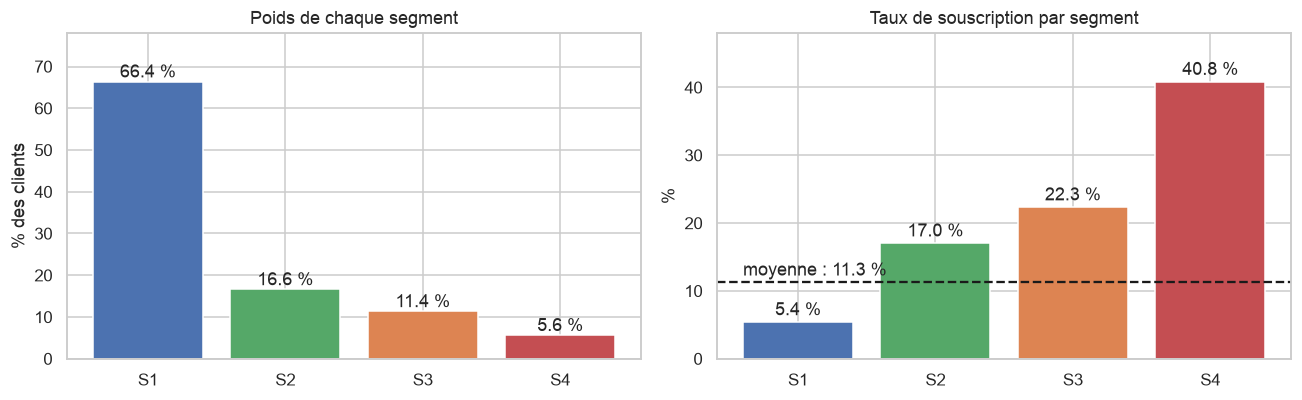

,clients,souscriptions,% des clients,taux de souscription (%),indice (base 100 = moyenne),% des souscriptions
segment,,,,,,
S1,27338,1481,66.4,5.4,48.1,31.9
S2,6841,1165,16.6,17.0,151.2,25.1
S3,4676,1045,11.4,22.3,198.4,22.5
S4,2321,948,5.6,40.8,362.5,20.4


In [77]:
global_rate = 100 * df["souscrit"].mean()
size = df.groupby("segment").agg(clients=("souscrit", "size"), souscriptions=("souscrit", "sum"))
size["% des clients"] = 100 * size["clients"] / len(df)
size["taux de souscription (%)"] = 100 * size["souscriptions"] / size["clients"]
size["indice (base 100 = moyenne)"] = 100 * size["taux de souscription (%)"] / global_rate
size["% des souscriptions"] = 100 * size["souscriptions"] / size["souscriptions"].sum()
size.to_csv(TAB / "05_taille_souscription.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(SEG, size["% des clients"], color=PALETTE)
for i, v in enumerate(size["% des clients"]): axes[0].text(i, v + 1, f"{v:.1f} %", ha="center")
axes[0].set_title("Poids de chaque segment"); axes[0].set_ylabel("% des clients"); axes[0].set_ylim(0, 78)
axes[1].bar(SEG, size["taux de souscription (%)"], color=PALETTE)
axes[1].axhline(global_rate, ls="--", color="k"); axes[1].text(-0.4, global_rate + 1, f"moyenne : {global_rate:.1f} %")
for i, v in enumerate(size["taux de souscription (%)"]): axes[1].text(i, v + 1, f"{v:.1f} %", ha="center")
axes[1].set_title("Taux de souscription par segment"); axes[1].set_ylabel("%"); axes[1].set_ylim(0, 48)
plt.tight_layout(); plt.savefig(FIG / "05_taille_souscription.png", bbox_inches="tight"); plt.show()
size.round(1)

Le taux de souscription est multiplié par **plus de 7** entre S1 et S4, alors que `y` n'a jamais été montrée aux algorithmes : la segmentation capte bien des comportements différents.

## B.2 Variables numériques : moyennes par segment

In [78]:
num_prof = pp.ACTIVE_NUM + ["duration"]
means = df.groupby("segment")[num_prof].mean()
means.loc["Ensemble"] = df[num_prof].mean()
means.round(2).to_csv(TAB / "05_moyennes_segments.csv")
means.round(2)

,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,duration
segment,,,,,,,
S1,40.21,2.71,0.00,93.86,-39.37,4.78,254.02
S2,37.89,2.23,0.00,93.01,-46.02,1.31,264.82
S3,39.40,2.00,1.26,93.27,-43.93,1.63,265.27
S4,45.40,1.79,0.53,92.47,-30.65,0.80,275.66
Ensemble,40.02,2.50,0.17,93.58,-40.50,3.62,258.32


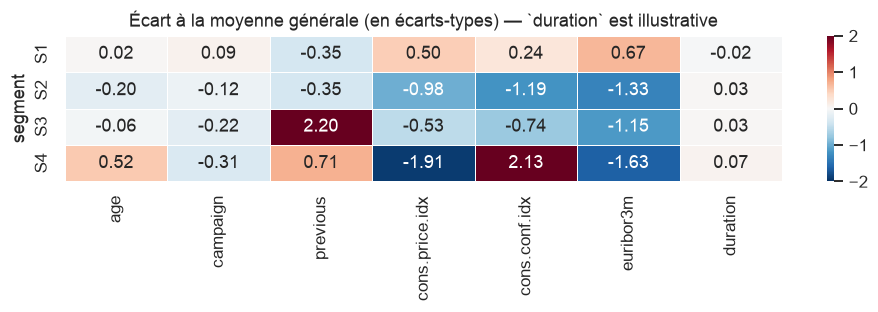

In [79]:
# Écarts à la moyenne en nombre d'écarts-types : ce qui distingue chaque segment
z = (df.groupby("segment")[num_prof].mean() - df[num_prof].mean()) / df[num_prof].std()
plt.figure(figsize=(9, 3))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, linewidths=.5)
plt.title("Écart à la moyenne générale (en écarts-types) — `duration` est illustrative")
plt.tight_layout(); plt.savefig(FIG / "05_heatmap_profils.png", bbox_inches="tight"); plt.show()

## B.3 Variables catégorielles : modes et répartitions

In [80]:
cat_prof = pp.ACTIVE_CAT + ["month"]
modes = df.groupby("segment")[cat_prof].agg(lambda s: s.mode()[0])
share = df.groupby("segment")[cat_prof].agg(lambda s: f"{100 * s.value_counts(normalize=True).iloc[0]:.0f} %")
(modes + " (" + share + ")").T

segment,S1,S2,S3,S4
job,admin. (26 %),blue-collar (26 %),admin. (27 %),admin. (32 %)
marital,married (64 %),married (54 %),married (55 %),married (59 %)
education,university.degree (33 %),university.degree (32 %),university.degree (34 %),university.degree (48 %)
default,no (74 %),no (87 %),no (88 %),no (97 %)
housing,yes (53 %),yes (60 %),yes (58 %),yes (57 %)
loan,no (85 %),no (84 %),no (85 %),no (86 %)
contact,telephone (50 %),cellular (91 %),cellular (93 %),cellular (88 %)
poutcome,nonexistent (100 %),nonexistent (100 %),failure (79 %),nonexistent (59 %)
contacted_before,no (100 %),no (100 %),no (77 %),no (80 %)
month,may (28 %),may (58 %),may (43 %),aug (33 %)


In [81]:
def pct(col, value):
    """% de clients du segment vérifiant col == value (ou col dans une liste)."""
    vals = value if isinstance(value, list) else [value]
    return 100 * df[col].isin(vals).groupby(df["segment"]).mean()

key = pd.DataFrame({
    "contact sur mobile":                 pct("contact", "cellular"),
    "déjà démarché (campagne passée)":    pct("poutcome", ["failure", "success"]),
    "succès à la campagne passée":        pct("poutcome", "success"),
    "défaut de crédit inconnu":           pct("default", "unknown"),
    "retraité ou étudiant":               pct("job", ["retired", "student"]),
    "ouvrier (blue-collar)":              pct("job", "blue-collar"),
    "diplôme universitaire":              pct("education", "university.degree"),
    "célibataire":                        pct("marital", "single"),
    "60 ans et plus":                     100 * (df["age"] >= 60).groupby(df["segment"]).mean(),
    "prêt immobilier":                    pct("housing", "yes"),
})
key.loc["Ensemble"] = [100 * df["contact"].eq("cellular").mean(), 100 * df["poutcome"].ne("nonexistent").mean(),
                       100 * df["poutcome"].eq("success").mean(), 100 * df["default"].eq("unknown").mean(),
                       100 * df["job"].isin(["retired", "student"]).mean(), 100 * df["job"].eq("blue-collar").mean(),
                       100 * df["education"].eq("university.degree").mean(), 100 * df["marital"].eq("single").mean(),
                       100 * (df["age"] >= 60).mean(), 100 * df["housing"].eq("yes").mean()]
key.round(1).to_csv(TAB / "05_indicateurs_cles.csv")
key.round(1).T

segment,S1,S2,S3,S4,Ensemble
contact sur mobile,49.5,90.8,92.6,88.5,63.5
déjà démarché (campagne passée),0.0,0.0,100.0,40.9,13.7
succès à la campagne passée,0.0,0.0,20.5,17.8,3.3
défaut de crédit inconnu,26.0,12.9,11.7,2.7,20.9
retraité ou étudiant,3.9,7.4,9.2,25.6,6.3
ouvrier (blue-collar),23.3,26.2,20.5,5.3,22.5
diplôme universitaire,33.0,31.9,33.9,47.6,33.7
célibataire,24.8,36.1,34.0,31.3,28.1
60 ans et plus,0.9,3.0,5.0,22.0,2.9
prêt immobilier,52.7,59.9,58.3,56.6,54.8


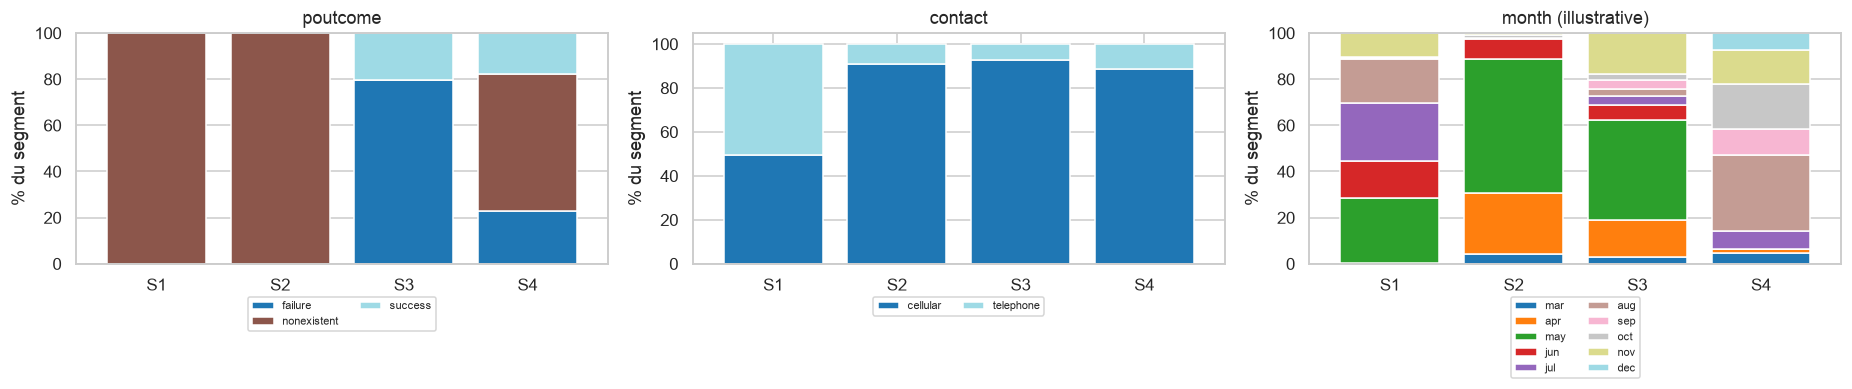

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    ct = pd.crosstab(df["segment"], df[col], normalize="index") * 100
    if col == "month":
        ct = ct[["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]]
    ct.plot.bar(stacked=True, ax=ax, colormap="tab20", width=0.8)
    ax.set_title(col + (" (illustrative)" if col == "month" else "")); ax.set_xlabel(""); ax.set_ylabel("% du segment")
    ax.legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "05_categorielles_segments.png", bbox_inches="tight"); plt.show()

## B.4 Radar charts
Huit indicateurs résument chaque segment. Pour les rendre comparables, chacun est ramené entre 0 (valeur du segment le plus bas) et 1 (valeur du segment le plus haut).

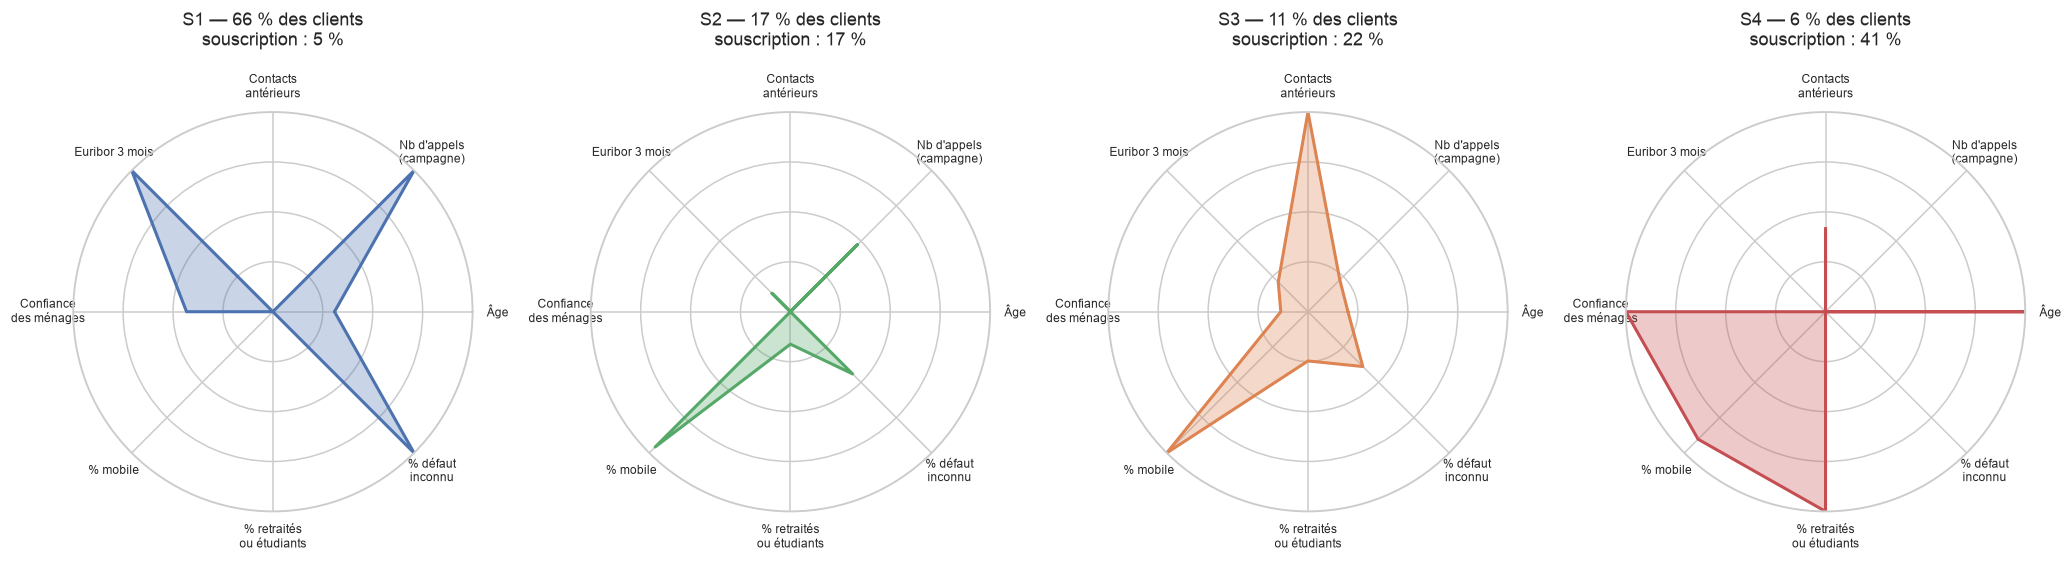

In [83]:
radar = pd.DataFrame({
    "Âge": means.loc[SEG, "age"],
    "Nb d'appels\n(campagne)": means.loc[SEG, "campaign"],
    "Contacts\nantérieurs": means.loc[SEG, "previous"],
    "Euribor 3 mois": means.loc[SEG, "euribor3m"],
    "Confiance\ndes ménages": means.loc[SEG, "cons.conf.idx"],
    "% mobile": key.loc[SEG, "contact sur mobile"],
    "% retraités\nou étudiants": key.loc[SEG, "retraité ou étudiant"],
    "% défaut\ninconnu": key.loc[SEG, "défaut de crédit inconnu"],
})
radar_n = (radar - radar.min()) / (radar.max() - radar.min())
angles = np.linspace(0, 2 * np.pi, radar.shape[1], endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), subplot_kw={"polar": True})
for ax, s, c in zip(axes, SEG, PALETTE):
    vals = radar_n.loc[s].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=c, lw=2); ax.fill(angles, vals, color=c, alpha=.3)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(radar.columns, fontsize=8)
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels([]); ax.set_ylim(0, 1)
    ax.set_title(f"{s} — {size.loc[s, '% des clients']:.0f} % des clients\nsouscription : {size.loc[s, 'taux de souscription (%)']:.0f} %", pad=18)
plt.tight_layout(); plt.savefig(FIG / "05_radars.png", bbox_inches="tight"); plt.show()

# Partie C — Fiches d'identité des segments

| | **S1 — Nouveaux prospects, taux élevés** | **S2 — Nouveaux prospects, taux bas** | **S3 — Clients déjà démarchés** | **S4 — Profils réceptifs** |
|---|---|---|---|---|
| **Poids** | 66 % des clients | 17 % | 11 % | 6 % |
| **Taux de souscription** | **5 %** (2 fois moins que la moyenne) | **17 %** (1,5 fois la moyenne) | **22 %** (2 fois la moyenne) | **41 %** (3,6 fois la moyenne) |
| **Historique** | jamais démarchés | jamais démarchés | tous déjà démarchés : 79 % d'échecs, 21 % de succès | mixte : 41 % déjà démarchés |
| **Contexte** | Euribor ≈ 4,8 % ; appels de mai à août | Euribor ≈ 1,3 % ; confiance des ménages au plus bas ; appels en avril-mai | Euribor ≈ 1,6 % | Euribor < 1 % ; confiance des ménages au plus haut ; appels d'août à décembre |
| **Canal** | 50 % fixe / 50 % mobile | mobile (91 %) | mobile (93 %) | mobile (88 %) |
| **Profil** | 40 ans, mariés ; 26 % de défaut « inconnu » ; le plus sollicité (2,7 appels) | le plus jeune (38 ans), 36 % de célibataires | 39 ans, profil socio-démographique moyen | le plus âgé (45 ans ; 22 % de 60 ans et plus) ; 25 % de retraités ou étudiants ; 48 % de diplômés du supérieur ; très peu d'ouvriers |

**Ce qui structure la clientèle.** Trois dimensions ressortent, dans cet ordre : le **contexte économique** au moment du contact (taux élevés ou bas), l'**historique de la relation** (déjà démarché ou non) et, pour S4, le **profil socio-démographique** (seniors, étudiants, diplômés). Les caractéristiques financières du client (prêt immobilier, prêt personnel) ne différencient presque pas les segments.

# Partie D — Recommandations marketing
## D.1 Combien rapporte le ciblage ?
On simule une campagne qui appelle les segments par ordre de priorité (du plus au moins réceptif).

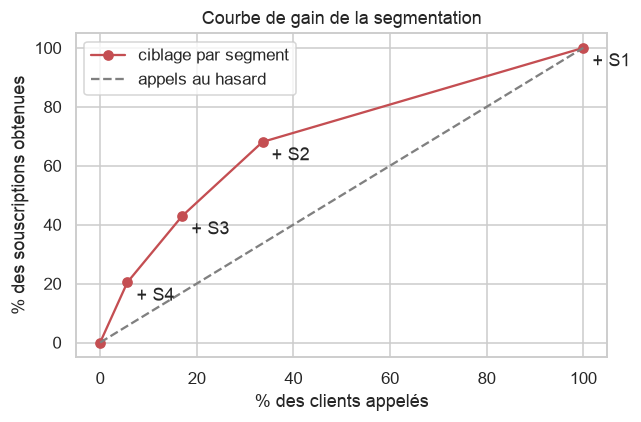

,clients,souscriptions,taux de souscription (%),% cumulé des appels,% cumulé des souscriptions,taux cumulé (%)
segment,,,,,,
S4,2321,948,40.8,5.6,20.4,40.8
S3,4676,1045,22.3,17.0,43.0,28.5
S2,6841,1165,17.0,33.6,68.1,22.8
S1,27338,1481,5.4,100.0,100.0,11.3


In [84]:
gain = size.loc[SEG[::-1], ["clients", "souscriptions", "taux de souscription (%)"]].copy()
gain["% cumulé des appels"] = 100 * gain["clients"].cumsum() / gain["clients"].sum()
gain["% cumulé des souscriptions"] = 100 * gain["souscriptions"].cumsum() / gain["souscriptions"].sum()
gain["taux cumulé (%)"] = 100 * gain["souscriptions"].cumsum() / gain["clients"].cumsum()
gain.to_csv(TAB / "05_courbe_gain.csv")

plt.figure(figsize=(6, 4))
xs = [0] + gain["% cumulé des appels"].tolist(); ys = [0] + gain["% cumulé des souscriptions"].tolist()
plt.plot(xs, ys, "o-", color="#C44E52", label="ciblage par segment")
plt.plot([0, 100], [0, 100], "--", color="grey", label="appels au hasard")
for x, yv, s in zip(xs[1:], ys[1:], gain.index): plt.annotate(f"+ {s}", (x, yv), textcoords="offset points", xytext=(6, -12))
plt.xlabel("% des clients appelés"); plt.ylabel("% des souscriptions obtenues"); plt.title("Courbe de gain de la segmentation"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "05_courbe_gain.png", bbox_inches="tight"); plt.show()
gain.round(1)

**Lecture.** En appelant seulement S4 + S3 + S2, soit **un tiers des clients**, la banque obtient environ **deux tiers des souscriptions**. Le taux de réussite des appels passe de 11 % à plus de 20 %.

## D.2 Une recommandation par segment

| Segment | Recommandation | Justification par les données |
|---|---|---|
| **S4 — Profils réceptifs** (6 %, 41 %) | **Priorité n° 1 : les appeler en premier, avec les conseillers les plus expérimentés.** Offre « épargne sécurisée » orientée seniors et étudiants. Un ou deux appels suffisent. | Taux 3,6 fois supérieur à la moyenne ; segment le moins sollicité (1,8 appel) ; retraités, étudiants et diplômés sur-représentés. |
| **S3 — Clients déjà démarchés** (11 %, 22 %) | **Relance personnalisée selon le résultat précédent.** Anciens succès : proposition de renouvellement, traitée en priorité. Anciens échecs : nouvel argumentaire, jamais le même script. | Tous ont un historique ; 21 % d'anciens succès. Le résultat précédent est la variable la plus discriminante du segment. |
| **S2 — Nouveaux prospects, taux bas** (17 %, 17 %) | **Campagne d'acquisition sur mobile, concentrée sur les périodes de taux bas.** Message : « sécuriser son épargne quand les taux baissent ». Deux appels au maximum. | Taux 1,5 fois supérieur à la moyenne pour un premier contact ; joints à 91 % sur mobile ; clientèle plus jeune et plus souvent célibataire. |
| **S1 — Nouveaux prospects, taux élevés** (66 %, 5 %) | **Réduire la pression téléphonique.** Plafonner à 2 appels, basculer vers des canaux peu coûteux (courriel, SMS, application), et reporter la sollicitation à un contexte plus favorable. | Deux tiers des appels pour un tiers des souscriptions ; segment le plus sollicité (2,7 appels) et le moins réceptif ; la moitié des contacts passe encore par le téléphone fixe. |

**Recommandation transversale.** Les campagnes sont beaucoup plus efficaces quand les taux sont bas. Le **calendrier** des campagnes compte donc autant que le choix des clients : mieux vaut concentrer le budget d'appels sur ces périodes.

# Partie E — Limites et pistes d'amélioration

**Limites**
1. **Structure faible.** Les silhouettes sont modestes (≈ 0,21) : les segments se chevauchent. Ce sont des tendances, pas des catégories étanches.
2. **Le contexte domine.** S1 et S2 se distinguent surtout par la période du contact, pas par ce que le client *est*. Un même client appelé à un autre moment pourrait changer de segment. C'est une information utile pour planifier les campagnes, moins pour connaître les personnes.
3. **Peu de variables sur le client.** Le fichier ne contient ni revenu, ni solde, ni ancienneté : la segmentation socio-démographique reste limitée.
4. **k = 4 est un choix métier.** Statistiquement, la structure la plus nette est à 2 groupes ; le passage à 4 est validé par les indices mais motivé par le besoin de recommandations différenciées.
5. **Ward sur échantillon.** La segmentation est construite sur 4 000 clients puis étendue par le centre le plus proche (accord : 98 %).

**Pistes**
- Refaire la segmentation **sans les variables de contexte** pour obtenir des profils purement « client ».
- Utiliser les points de bruit de DBSCAN (Jour 3) ou une Isolation Forest pour suivre les **clients atypiques**.
- Déployer `assign_segment()` dans une petite application (Streamlit) pour classer un nouveau client en temps réel.
- Reproduire l'étude sur un second jeu de données (segmentation RFM sur *Online Retail*).

## Démonstration : classer un nouveau client

In [85]:
nouveau = pd.DataFrame([{
    "age": 63, "campaign": 1, "previous": 1, "cons.price.idx": 92.9, "cons.conf.idx": -31.0, "euribor3m": 0.9,
    "job": "retired", "marital": "married", "education": "university.degree", "default": "no",
    "housing": "no", "loan": "no", "contact": "cellular", "poutcome": "success", "contacted_before": "yes"}])
s = SEG[assign_segment(nouveau)[0]]
print(f"Segment attribué : {s}  ->  taux de souscription attendu : {size.loc[s, 'taux de souscription (%)']:.0f} %")

Segment attribué : S4  ->  taux de souscription attendu : 41 %


# Conclusion du projet

| Jour | Résultat principal |
|---|---|
| 1 | Données nettoyées, 15 variables actives, deux représentations (one-hot standardisé / mixte), échantillon stratifié de 4 000 clients |
| 2 | La standardisation et le choix de la distance changent les groupes ; Gower pour le mixte ; K-means, K-prototypes et GMM s'accordent à k = 2 |
| 3 | Ward donne des groupes équilibrés ; *single / average / complete* et DBSCAN isolent des atypiques |
| 4 | **CAH de Ward, k = 4** : meilleur compromis entre indices internes, externes et stabilité (ARI bootstrap = 0,93) |
| 5 | 4 segments dont le taux de souscription va de 5 % à 41 % ; un tiers des clients concentre deux tiers des souscriptions |

# Extensions — Sensibilité au contexte et clients atypiques

Ce notebook complète les Jours 1 à 5 **sans modifier la solution retenue** (CAH de Ward, k = 4).

| Partie | Contenu | Place dans le sujet |
|---|---|---|
| A | Segmentation **sans les variables de contexte économique** : que reste-t-il quand on ne garde que le client ? | Discussion des résultats (Jour 5) |
| B | **Détection d'anomalies** : bruit DBSCAN et Isolation Forest, profil des clients atypiques | Extension optionnelle n° 1 |
| C | **Application Streamlit** affectant un nouveau client à un segment | Extension optionnelle n° 3 |

Comme au Jour 4, `y` ne sert qu'à **décrire** les groupes obtenus, jamais à les construire.

In [86]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             pairwise_distances_argmin)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import SEED, FIG, TAB, LAB
from src import preprocessing as pp
from src.clustering_utils import knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

d = pp.prepare_all()
df, idx, y = d["df_clean"], d["idx"], d["y"]
y_bin = (y == "yes").astype(int).values
pos = np.searchsorted(df.index, idx)                       # position des clients de l'échantillon
seg_ref = pd.read_csv(LAB / "segments_population.csv", index_col=0)["segment"]   # solution retenue (S1..S4)
print("Échantillon :", len(idx), "clients ; population :", len(df))

Échantillon : 4000 clients ; population : 41176


# Partie A — Segmentation sans les variables de contexte

## A.1 Pourquoi cette variante ?
Au Jour 5, les segments S1 et S2 se distinguent surtout par le **taux Euribor au moment de l'appel**. Les trois variables de contexte (`cons.price.idx`, `cons.conf.idx`, `euribor3m`) décrivent la **période** du contact, pas le client : un même client appelé à une autre date changerait de segment.

On refait donc la CAH de Ward en ne gardant que les **12 variables qui décrivent le client et sa relation avec la banque** : âge, nombre d'appels, contacts antérieurs, profession, statut marital, études, défaut, prêts, canal, résultat précédent, `contacted_before`. Même prétraitement (one-hot + standardisation), même échantillon, même graine.

Il ne s'agit **pas** de remplacer la solution retenue, mais de mesurer ce qu'elle doit au contexte.

In [87]:
CTX = ["cons.price.idx", "cons.conf.idx", "euribor3m"]
NUM_C = [c for c in pp.ACTIVE_NUM if c not in CTX]
CAT_C = pp.ACTIVE_CAT
prep_c = ColumnTransformer([("num", StandardScaler(), NUM_C),
                            ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), CAT_C)]).fit(df[NUM_C + CAT_C])
Xc_full = prep_c.transform(df[NUM_C + CAT_C])
Xc = Xc_full[pos]
print("Variables actives :", NUM_C + CAT_C)
print("Dimension après encodage :", Xc.shape[1])

Zc = linkage(Xc, method="ward")
rows = []
for k in range(2, 7):
    lab = fcluster(Zc, t=k, criterion="maxclust") - 1
    rates = 100 * pd.Series(y_bin).groupby(lab).mean()
    rows.append({"k": k, "silhouette": silhouette_score(Xc, lab), "Davies-Bouldin": davies_bouldin_score(Xc, lab),
                 "tailles": " / ".join(map(str, np.bincount(lab))),
                 "taux souscr. par cluster (%)": " / ".join(f"{r:.1f}" for r in rates)})
sans_ctx = pd.DataFrame(rows)
sans_ctx.to_csv(TAB / "06_sans_contexte_indices.csv", index=False)
sans_ctx.style.format(precision=3).hide(axis="index")

Variables actives : ['age', 'campaign', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'contacted_before']
Dimension après encodage : 34


k,silhouette,Davies-Bouldin,tailles,taux souscr. par cluster (%)
2,0.282,1.592,569 / 3431,25.0 / 9.0
3,0.200,1.846,569 / 495 / 2936,25.0 / 4.4 / 9.8
4,0.118,2.090,569 / 495 / 991 / 1945,25.0 / 4.4 / 10.2 / 9.6
5,0.124,1.894,34 / 535 / 495 / 991 / 1945,50.0 / 23.4 / 4.4 / 10.2 / 9.6
6,0.082,2.107,34 / 535 / 495 / 991 / 584 / 1361,50.0 / 23.4 / 4.4 / 10.2 / 13.5 / 7.9


**Lecture.** Sans le contexte, la structure la plus nette est encore à k = 2 (silhouette 0,28) : elle sépare les **clients déjà démarchés** (569 clients, 25 % de souscription) de tous les autres. Au-delà, la silhouette chute (0,12 à k = 4) : une fois l'historique mis à part, le profil socio-démographique ne forme **pas de groupes nets**.

On examine malgré tout k = 4 pour le comparer, à nombre égal, à la solution retenue.

In [88]:
K = 4
lab_c = fcluster(Zc, t=K, criterion="maxclust") - 1
cent_c = pd.DataFrame(Xc).groupby(lab_c).mean().values
full_c = pairwise_distances_argmin(Xc_full, cent_c)          # même règle d'extension qu'au Jour 5
print(f"Accord centre le plus proche / Ward sur l'échantillon : {(full_c[pos] == lab_c).mean():.1%}")

# Stabilité bootstrap (mêmes réglages qu'au Jour 4)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(20):
    ib = rng.integers(0, len(Xc), len(Xc))
    boot.append(adjusted_rand_score(lab_c[ib], AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xc[ib])))
print(f"Stabilité bootstrap (ARI moyen) : {np.mean(boot):.2f} ± {np.std(boot):.2f}   (solution retenue : 0,93)")
print(f"ARI avec la solution retenue (population) : {adjusted_rand_score(seg_ref, full_c):.2f}")

t = df.assign(groupe=full_c, souscrit=(df["y"] == "yes").astype(int))
pct = lambda col, vals: 100 * t[col].isin(vals).groupby(t["groupe"]).mean()
prof_c = pd.DataFrame({
    "% des clients": 100 * t["groupe"].value_counts(normalize=True).sort_index(),
    "taux de souscription (%)": 100 * t.groupby("groupe")["souscrit"].mean(),
    "âge moyen": t.groupby("groupe")["age"].mean(),
    "appels (campagne)": t.groupby("groupe")["campaign"].mean(),
    "déjà démarché (%)": pct("poutcome", ["failure", "success"]),
    "célibataire (%)": pct("marital", ["single"]),
    "retraité (%)": pct("job", ["retired"]),
    "défaut inconnu (%)": pct("default", ["unknown"]),
    "mobile (%)": pct("contact", ["cellular"]),
})
prof_c.round(1).to_csv(TAB / "06_sans_contexte_profils.csv")
prof_c.round(1)

Accord centre le plus proche / Ward sur l'échantillon : 86.0%


Stabilité bootstrap (ARI moyen) : 0.58 ± 0.13   (solution retenue : 0,93)
ARI avec la solution retenue (population) : 0.18


,% des clients,taux de souscription (%),âge moyen,appels (campagne),déjà démarché (%),célibataire (%),retraité (%),défaut inconnu (%),mobile (%)
groupe,,,,,,,,,
0,13.5,26.6,40.3,1.9,100.0,33.4,6.6,10.1,92.9
1,10.7,5.3,39.5,7.8,1.2,27.4,2.4,23.7,54.1
2,28.7,8.5,50.3,1.9,0.2,4.9,10.3,44.3,56.6
3,47.2,9.9,33.8,1.8,0.0,40.8,0.2,9.1,61.4


In [89]:
# Correspondance avec les segments de la solution retenue (population complète)
pd.crosstab(t["groupe"], seg_ref, margins=True, margins_name="total")

segment,S1,S2,S3,S4,total
groupe,,,,,
0,0,0,4618,928,5546
1,3668,614,51,64,4397
2,9467,1724,7,613,11811
3,14203,4503,0,716,19422
total,27338,6841,4676,2321,41176


**Les quatre groupes « client ».**

| Groupe | Profil | Lecture |
|---|---|---|
| 0 | Déjà démarchés (100 %), 24 % de succès précédents | Retrouve presque exactement le segment **S3** |
| 1 | **Sur-sollicités** : 7,8 appels en moyenne pendant la campagne | Petit groupe (11 %), souscription faible |
| 2 | Plus âgés (50 ans), mariés, défaut de crédit souvent inconnu | Profil « senior » |
| 3 | Plus jeunes (34 ans), 41 % de célibataires | Profil « jeune actif » |

Deux constats :
- **Seul l'historique de contact survit** à la suppression du contexte : S3 est retrouvé, les autres segments sont redistribués (ARI de 0,18 avec la solution retenue).
- La partition est **moins nette** (silhouette 0,12 contre 0,21) et **beaucoup moins stable** (ARI bootstrap ≈ 0,58 contre 0,93).

Attention à l'interprétation du groupe 1 : `campaign` compte les appels de la campagne en cours, qui s'arrêtent souvent après une souscription. Un grand nombre d'appels est donc en partie une **conséquence** de la non-souscription, pas seulement une caractéristique du client.

## A.2 À période égale, le profil du client compte-t-il encore ?
On croise les groupes « client » avec la période du contact (taux Euribor bas < 3 % ou haut ≥ 3 %).

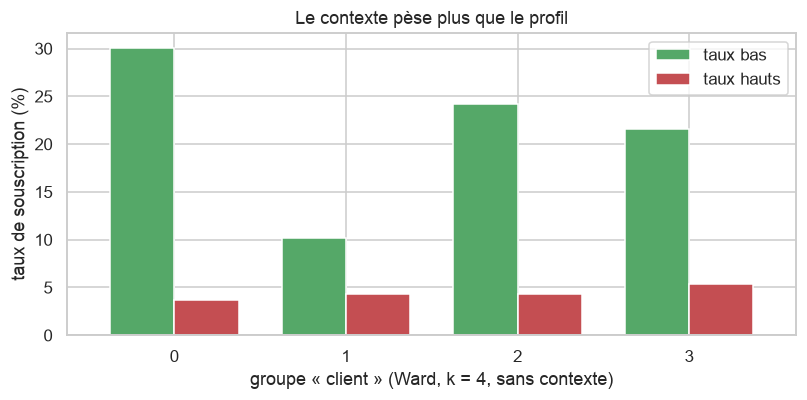

,taux bas : souscription (%),taux bas : clients,taux hauts : souscription (%),taux hauts : clients
groupe,,,,
0,30.1,4816.0,3.7,730.0
1,10.1,749.0,4.4,3648.0
2,24.2,2476.0,4.4,9335.0
3,21.6,5453.0,5.3,13969.0
ensemble,24.5,13494.0,4.8,27682.0


In [90]:
t["période"] = np.where(t["euribor3m"] >= 3, "taux hauts (≥ 3 %)", "taux bas (< 3 %)")
ct = t.pivot_table(index="groupe", columns="période", values="souscrit", aggfunc=["mean", "size"])
ctx_tab = pd.DataFrame({
    "taux bas : souscription (%)": 100 * ct[("mean", "taux bas (< 3 %)")],
    "taux bas : clients": ct[("size", "taux bas (< 3 %)")],
    "taux hauts : souscription (%)": 100 * ct[("mean", "taux hauts (≥ 3 %)")],
    "taux hauts : clients": ct[("size", "taux hauts (≥ 3 %)")],
})
ctx_tab.loc["ensemble"] = [100 * t.loc[t["période"].str.startswith("taux bas"), "souscrit"].mean(),
                           (t["période"].str.startswith("taux bas")).sum(),
                           100 * t.loc[t["période"].str.startswith("taux hauts"), "souscrit"].mean(),
                           (t["période"].str.startswith("taux hauts")).sum()]
ctx_tab.round(1).to_csv(TAB / "06_contexte_vs_profil.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ctx_tab.iloc[:-1][["taux bas : souscription (%)", "taux hauts : souscription (%)"]].plot.bar(ax=ax, color=["#55A868", "#C44E52"], width=0.75)
ax.set_xlabel("groupe « client » (Ward, k = 4, sans contexte)"); ax.set_ylabel("taux de souscription (%)")
ax.set_title("Le contexte pèse plus que le profil"); ax.tick_params(axis="x", rotation=0); ax.legend(["taux bas", "taux hauts"])
plt.tight_layout(); plt.savefig(FIG / "06_contexte_vs_profil.png", bbox_inches="tight"); plt.show()
ctx_tab.round(1)

**Lecture.**
- **Le contexte domine.** Dans chaque groupe, la souscription passe d'environ 4–5 % en période de taux hauts à 10–30 % en période de taux bas. L'écart dû à la période est bien plus grand que l'écart entre profils.
- **À période égale, le profil compte encore, mais par l'historique et la pression d'appels.** En taux bas : 30 % pour les déjà démarchés, 22–24 % pour les deux profils socio-démographiques, 10 % pour les sur-sollicités. Seniors et jeunes actifs ont des taux très proches : la démographie seule discrimine peu.

**Conséquence pour la solution retenue.** Le choix de garder le contexte dans les variables actives est assumé. Ce qui intéresse la banque, c'est de savoir **qui appeler et quand**, et le contexte est le facteur le plus prédictif. Mais il faut présenter S1 et S2 comme des **situations de contact** plutôt que comme des types de clients. Les recommandations « client » robustes sont celles qui portent sur l'historique (S3) et sur la limitation du nombre d'appels.

# Partie B — Clients atypiques (extension n° 1)

Deux détecteurs indépendants, sur l'échantillon de 4 000 clients :
- **Bruit DBSCAN** : mêmes réglages qu'au Jour 3 (espace PCA à 5 composantes, `min_samples = 10`, ε au coude du graphique des k-distances). Un client est atypique s'il n'a pas assez de voisins proches.
- **Isolation Forest** : forêt d'arbres de partition aléatoires sur la représentation (a). Un client est atypique s'il est **isolé en peu de coupures**. Pour comparer les deux méthodes à effort égal, on fixe la proportion d'anomalies (`contamination`) à celle du bruit DBSCAN.

In [91]:
X_a = d["X_a"].values
X_mixed = d["X_mixed"]

Z5 = PCA(n_components=5, random_state=SEED).fit_transform(X_a)
kdist = np.sort(NearestNeighbors(n_neighbors=10).fit(Z5).kneighbors(Z5)[0][:, -1])
EPS = float(kdist[knee_point(kdist)])
noise = DBSCAN(eps=EPS, min_samples=10).fit_predict(Z5) == -1

iso = IsolationForest(n_estimators=300, contamination=noise.mean(), random_state=SEED).fit(X_a)
score = -iso.score_samples(X_a)                 # plus haut = plus atypique
outlier = iso.predict(X_a) == -1

both = noise & outlier
print(f"ε = {EPS:.2f}")
print(f"Bruit DBSCAN     : {noise.sum()} clients ({100 * noise.mean():.1f} %)")
print(f"Isolation Forest : {outlier.sum()} clients")
print(f"Signalés par les deux : {both.sum()}  ({100 * both.sum() / noise.sum():.0f} % du bruit DBSCAN)")

ε = 1.00
Bruit DBSCAN     : 150 clients (3.8 %)
Isolation Forest : 150 clients
Signalés par les deux : 66  (44 % du bruit DBSCAN)


In [92]:
groups = {"bruit DBSCAN": noise, "Isolation Forest": outlier, "les deux": both, "clients ordinaires": ~(noise | outlier)}
def describe(m):
    s = X_mixed[m]
    return {"nb de clients": int(m.sum()),
            "taux de souscription (%)": 100 * y_bin[m].mean(),
            "âge moyen": s["age"].mean(),
            "appels (campagne)": s["campaign"].mean(),
            "contacts antérieurs": s["previous"].mean(),
            "Euribor moyen": s["euribor3m"].mean(),
            "succès précédent (%)": 100 * (s["poutcome"] == "success").mean(),
            "déjà démarché (%)": 100 * (s["contacted_before"] == "yes").mean(),
            "retraité ou étudiant (%)": 100 * s["job"].isin(["retired", "student"]).mean(),
            "téléphone fixe (%)": 100 * (s["contact"] == "telephone").mean()}
atyp = pd.DataFrame({k: describe(m) for k, m in groups.items()})
atyp.round(2).to_csv(TAB / "06_clients_atypiques.csv")
atyp.round(1)

,bruit DBSCAN,Isolation Forest,les deux,clients ordinaires
nb de clients,150.0,150.0,66.0,3766.0
taux de souscription (%),49.3,46.0,56.1,9.2
âge moyen,49.3,43.3,48.5,39.9
appels (campagne),3.5,2.0,2.0,2.4
contacts antérieurs,1.5,1.7,2.5,0.1
Euribor moyen,1.2,1.1,0.9,3.8
succès précédent (%),36.7,57.3,69.7,0.9
déjà démarché (%),42.0,62.0,78.8,1.0
retraité ou étudiant (%),34.0,30.0,45.5,5.2
téléphone fixe (%),16.7,9.3,9.1,36.9


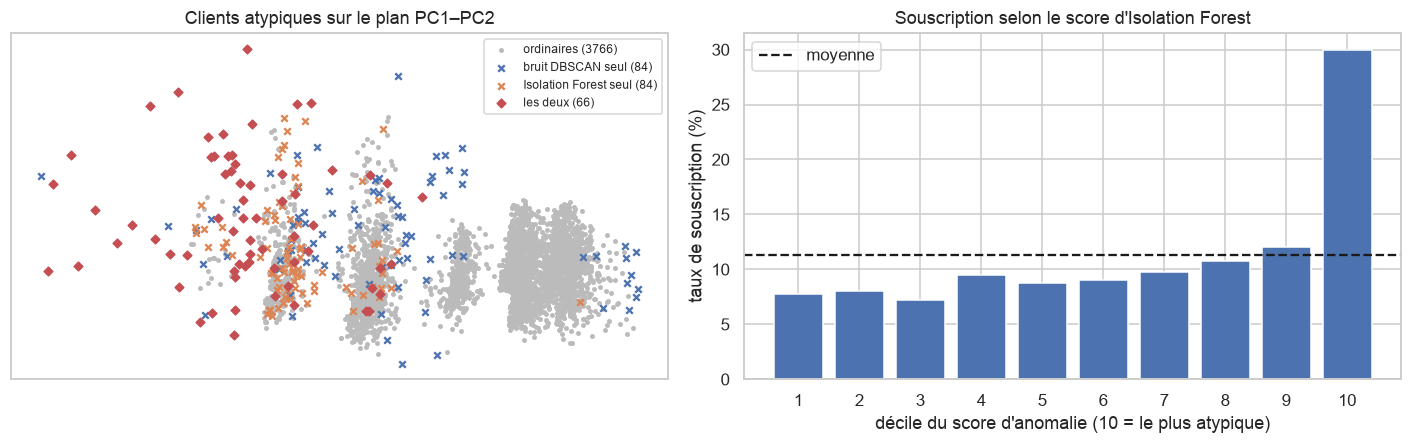

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for m, c, lbl, mk, s in [(~(noise | outlier), "#BBBBBB", "ordinaires", "o", 5), (noise & ~outlier, "#4C72B0", "bruit DBSCAN seul", "x", 18),
                         (outlier & ~noise, "#DD8452", "Isolation Forest seul", "x", 18), (both, "#C44E52", "les deux", "D", 16)]:
    axes[0].scatter(Z5[m, 0], Z5[m, 1], c=c, s=s, marker=mk, label=f"{lbl} ({m.sum()})")
axes[0].set_title("Clients atypiques sur le plan PC1–PC2"); axes[0].legend(fontsize=8); axes[0].set_xticks([]); axes[0].set_yticks([])
dec = pd.qcut(score, 10, labels=False) + 1
rate_dec = 100 * pd.Series(y_bin).groupby(dec).mean()
axes[1].bar(rate_dec.index, rate_dec.values, color="#4C72B0")
axes[1].axhline(100 * y_bin.mean(), ls="--", color="k", label="moyenne")
axes[1].set_xlabel("décile du score d'anomalie (10 = le plus atypique)"); axes[1].set_ylabel("taux de souscription (%)")
axes[1].set_title("Souscription selon le score d'Isolation Forest"); axes[1].set_xticks(range(1, 11)); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "06_clients_atypiques.png", bbox_inches="tight"); plt.show()

**Lecture.**
- Les deux méthodes reposent sur des principes différents (densité locale contre facilité d'isolement), et pourtant **près de la moitié des clients du bruit DBSCAN sont aussi signalés par l'Isolation Forest**. Le noyau commun est donc solide.
- **Les atypiques ne sont pas des erreurs de saisie** : ce sont surtout des clients **déjà démarchés**, souvent avec un **succès précédent**, contactés en période de taux bas. On trouve aussi des retraités et des étudiants.
- Leur taux de souscription avoisine **45–50 %**, soit plus de quatre fois la moyenne. Le taux monte d'ailleurs avec le score d'anomalie.

**Conséquence métier.** Ces clients atypiques ne sont pas à écarter. Ils forment un petit vivier très réceptif, que les méthodes de partitionnement noient dans S3 ou S4. On peut les extraire avec le score d'Isolation Forest et les confier en priorité aux conseillers.

# Partie C — Application Streamlit (extension n° 3)

Le fichier `app/streamlit_app.py` affecte un nouveau client à l'un des quatre segments de la solution retenue, avec la règle du Jour 5 :
1. le client est encodé par le **même préprocesseur** (one-hot + standardisation ajustés sur la population) ;
2. il est affecté au **centre de segment le plus proche** (`outputs/tables/05_centroides_segments.csv`) ;
3. l'application affiche le segment, son taux de souscription observé, la recommandation marketing associée, les distances aux 4 centres et la comparaison du client avec son segment ;
4. elle signale les **clients atypiques** avec l'Isolation Forest de la partie B ;
5. un second onglet affecte un **fichier CSV** entier (format brut UCI accepté, nettoyage du Jour 1 appliqué) et permet de télécharger le résultat.

Lancement, depuis la racine du dépôt :
```bash
streamlit run app/streamlit_app.py
```
La cellule suivante vérifie que la fonction de l'application redonne bien les segments de la population.

In [94]:
sys.path.append("../app")
from streamlit_app import load_model, assign
prep, centroids = load_model()
check = assign(d["X_mixed_full"], prep, centroids)
print(f"Accord avec segments_population.csv : {(check == seg_ref.values).mean():.1%}")

Accord avec segments_population.csv : 100.0%


## Bilan des extensions
1. **Sans contexte**, la clientèle n'a qu'une structure nette : l'historique de contact. Les autres groupes sont flous (silhouette 0,12) et instables (ARI bootstrap ≈ 0,58). À période égale, ce sont l'historique et la pression d'appels qui comptent le plus, plus que le profil socio-démographique.
2. **Clients atypiques** : DBSCAN et Isolation Forest s'accordent sur un noyau de clients déjà démarchés, souvent anciens souscripteurs. Ils souscrivent à près de 50 %.
3. **Application** : la règle du centre le plus proche est déployée dans une petite application Streamlit (un client ou un fichier entier, avec alerte « atypique »).

# Extension — Sélection de variables avant clustering

Extension optionnelle n° 2 du sujet : *comparer plusieurs méthodes de sélection de caractéristiques (variance, wrapper) avant clustering.*

En apprentissage non supervisé, il n'y a pas de cible pour dire quelles variables sont « utiles ». On compare donc des critères **internes** :

| Méthode | Famille | Principe |
|---|---|---|
| Filtre **variance** | filtre | on retire les colonnes qui varient presque pas (après mise à l'échelle [0, 1]) |
| Filtre **score laplacien** | filtre | une bonne variable prend des valeurs proches pour des clients voisins (graphe des 10 plus proches voisins) |
| **Wrapper naïf** | wrapper | sélection avant ; critère = silhouette de K-means **dans le sous-espace** des variables retenues |
| **Wrapper corrigé** | wrapper | élimination arrière ; critère = silhouette de Ward **dans l'espace complet** des 15 variables |

Chaque sous-ensemble est ensuite segmenté par la **même méthode** que la solution retenue (CAH de Ward, k = 4) et comparé à la référence (15 variables). `y` ne sert, comme au Jour 4, qu'au contrôle a posteriori.

In [95]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, pairwise_distances
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import MinMaxScaler

from src.config import SEED, FIG, TAB, LAB, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

d = pp.prepare_all()
X_a, X_mixed = d["X_a"], d["X_mixed"]
y_bin = (d["y"] == "yes").astype(int).values
D_full = pairwise_distances(X_a.values)                 # espace complet (représentation (a))
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)
ref = pd.read_csv(LAB / "segments_final_echantillon.csv", index_col=0)["segment"].values   # Ward k = 4, 15 variables

VARS = pp.ACTIVE_NUM + pp.ACTIVE_CAT
COLS = {v: [c for c in X_a.columns if c == v or c.startswith(v + "_")] for v in VARS}   # colonnes encodées par variable
cols_of = lambda sub: sum([COLS[v] for v in sub], [])
print(f"{len(VARS)} variables actives, {X_a.shape[1]} colonnes encodées, {len(X_a)} clients")

15 variables actives, 37 colonnes encodées, 4000 clients


## 1. Filtre par variance
Les colonnes sont ramenées sur [0, 1] (sinon les variables standardisées auraient toutes une variance de 1). On retire celles dont la variance est inférieure à **0,01**.

Colonnes retirées : ['default_yes', 'education_illiterate', 'previous']


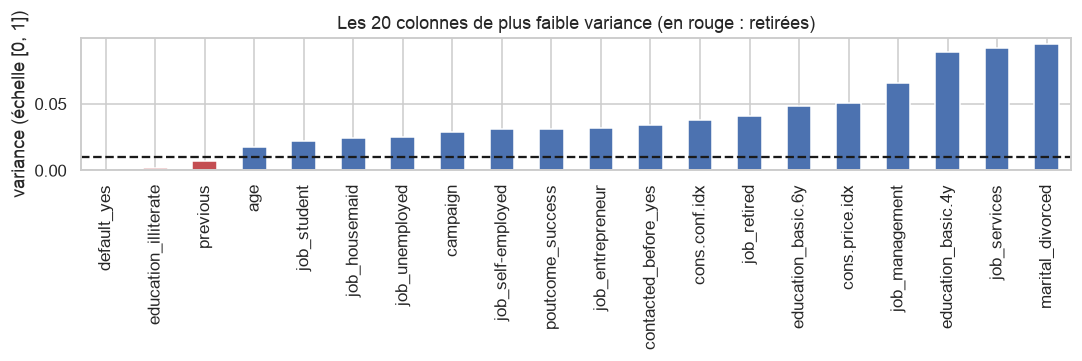

In [96]:
mm = pd.DataFrame(MinMaxScaler().fit_transform(X_a), columns=X_a.columns)
variances = mm.var().sort_values()
SEUIL = 0.01
drop_var = variances[variances < SEUIL].index.tolist()
keep_var_cols = [c for c in X_a.columns if c not in drop_var]
print("Colonnes retirées :", drop_var)

fig, ax = plt.subplots(figsize=(10, 3.4))
variances.head(20).plot.bar(ax=ax, color=["#C44E52" if v < SEUIL else "#4C72B0" for v in variances.head(20)])
ax.axhline(SEUIL, ls="--", color="k"); ax.set_ylabel("variance (échelle [0, 1])")
ax.set_title("Les 20 colonnes de plus faible variance (en rouge : retirées)")
plt.tight_layout(); plt.savefig(FIG / "07_variance.png", bbox_inches="tight"); plt.show()

**Lecture.** Le filtre retire deux modalités presque vides (`default_yes`, `education_illiterate`), ce qui est raisonnable, mais aussi **`previous`**. Cette variable a une faible variance parce que 86 % des clients ne sont jamais démarchés ; or c'est elle qui définit le segment S3. Une faible variance ne veut pas dire une faible information : c'est la limite connue de ce filtre.

## 2. Filtre par score laplacien
On construit le graphe des 10 plus proches voisins des clients (noyau gaussien sur les distances). Le **score laplacien** d'une colonne est faible quand elle prend des valeurs proches sur des clients voisins, c'est-à-dire quand elle respecte la structure locale des données (He, Cai et Niyogi, 2005). Le score d'une variable catégorielle est la moyenne de ses indicatrices. On garde les **8 meilleures variables** sur 15.

Variables retenues : ['euribor3m', 'previous', 'cons.conf.idx', 'cons.price.idx', 'poutcome', 'contact', 'age', 'default']


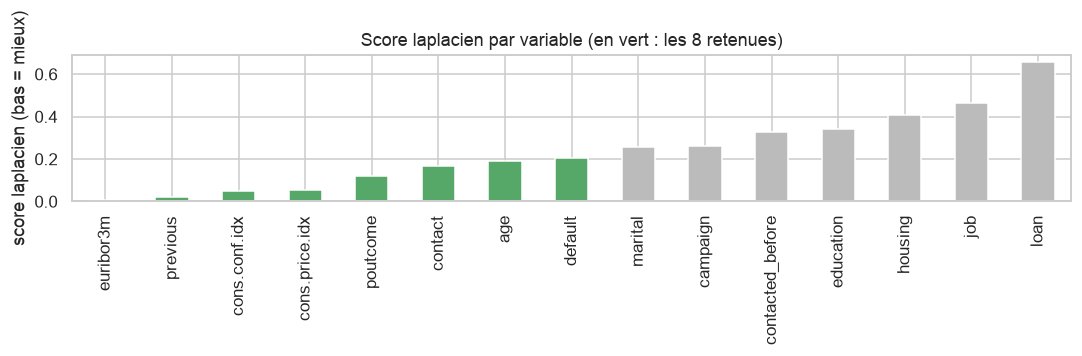

In [97]:
W = kneighbors_graph(X_a.values, 10, mode="distance", include_self=False)
W = 0.5 * (W + W.T)
t = np.median(W.data)
W.data = np.exp(-(W.data ** 2) / t ** 2)
deg = np.asarray(W.sum(axis=1)).ravel()
L = np.diag(deg) - W.toarray()

def laplacian_score(f):
    f = f - (f @ deg) / deg.sum()
    den = f @ (deg * f)
    return (f @ L @ f) / den if den > 0 else np.nan

col_score = {c: laplacian_score(X_a[c].values.astype(float)) for c in X_a.columns}
lap = pd.Series({v: np.nanmean([col_score[c] for c in COLS[v]]) for v in VARS}).sort_values()
sel_lap = lap.index[:8].tolist()
print("Variables retenues :", sel_lap)

fig, ax = plt.subplots(figsize=(10, 3.2))
lap.plot.bar(ax=ax, color=["#55A868" if v in sel_lap else "#BBBBBB" for v in lap.index])
ax.set_ylabel("score laplacien (bas = mieux)"); ax.set_title("Score laplacien par variable (en vert : les 8 retenues)")
plt.tight_layout(); plt.savefig(FIG / "07_laplacien.png", bbox_inches="tight"); plt.show()

## 3. Wrappers
Un wrapper choisit les variables **en lançant le clustering** et en jugeant le résultat.

- **Wrapper naïf** — sélection avant : à chaque étape, on ajoute la variable qui donne la meilleure silhouette de K-means (k = 4) **calculée dans le sous-espace retenu**, avec au moins 5 % des clients par cluster.
- **Wrapper corrigé** — élimination arrière : on part des 15 variables et on retire à chaque étape celle dont l'absence dégrade le moins la silhouette de Ward (k = 4), **toujours calculée dans l'espace complet**. Toutes les partitions sont ainsi jugées sur la même base.

Wrapper naïf : 1re variable choisie = euribor3m (silhouette 0.89)
Wrapper corrigé : variables retenues = ['previous', 'cons.conf.idx', 'euribor3m']


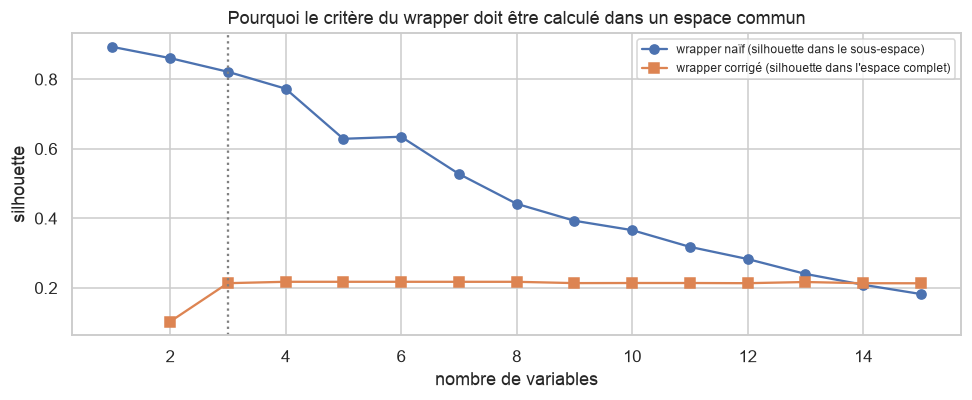

,nb variables,variable retirée,silhouette (espace complet)
0,15,—,0.213
1,14,job,0.213
2,13,marital,0.217
3,12,contacted_before,0.213
4,11,housing,0.214
5,10,default,0.214
6,9,poutcome,0.214
7,8,age,0.217
8,7,campaign,0.217
9,6,loan,0.217


In [98]:
# Wrapper naïf (sélection avant, silhouette dans le sous-espace)
sel, rest, naive = [], VARS.copy(), []
while rest:
    best = None
    for v in rest:
        X = X_a[cols_of(sel + [v])].values
        lab = KMeans(n_clusters=4, n_init=3, random_state=SEED).fit_predict(X)
        if np.bincount(lab, minlength=4).min() / len(lab) < 0.05:
            continue
        s = silhouette_score(X, lab)
        if best is None or s > best[1]:
            best = (v, s)
    if best is None:
        break
    sel.append(best[0]); rest.remove(best[0])
    naive.append({"nb variables": len(sel), "variable ajoutée": best[0], "silhouette (sous-espace)": best[1]})
naive = pd.DataFrame(naive)

# Wrapper corrigé (élimination arrière, silhouette dans l'espace complet)
def full_space_silhouette(sub):
    lab = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_a[cols_of(sub)].values)
    if np.bincount(lab).min() / len(lab) < 0.05:
        return -1.0
    return silhouette_score(D_full, lab, metric="precomputed")

cur = VARS.copy()
backward = [{"nb variables": len(cur), "variable retirée": "—", "silhouette (espace complet)": full_space_silhouette(cur)}]
while len(cur) > 2:
    s, v = max((full_space_silhouette([u for u in cur if u != w]), w) for w in cur)
    cur.remove(v)
    backward.append({"nb variables": len(cur), "variable retirée": v, "silhouette (espace complet)": s})
backward = pd.DataFrame(backward)

# Sous-ensemble retenu : le plus petit dont la silhouette reste à moins de 0,005 du maximum
smax = backward["silhouette (espace complet)"].max()
k_min = backward.loc[backward["silhouette (espace complet)"] >= smax - 0.005, "nb variables"].min()
removed = backward.loc[backward["nb variables"] >= k_min, "variable retirée"].iloc[1:].tolist()
sel_wrap = [v for v in VARS if v not in removed]
print("Wrapper naïf : 1re variable choisie =", naive.iloc[0, 1], f"(silhouette {naive.iloc[0, 2]:.2f})")
print("Wrapper corrigé : variables retenues =", sel_wrap)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(naive["nb variables"], naive["silhouette (sous-espace)"], "o-", label="wrapper naïf (silhouette dans le sous-espace)")
ax.plot(backward["nb variables"], backward["silhouette (espace complet)"], "s-", label="wrapper corrigé (silhouette dans l'espace complet)")
ax.axvline(k_min, ls=":", color="grey"); ax.set_xlabel("nombre de variables"); ax.set_ylabel("silhouette")
ax.set_title("Pourquoi le critère du wrapper doit être calculé dans un espace commun"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "07_wrappers.png", bbox_inches="tight"); plt.show()
backward.round(3)

## 4. Comparaison des sous-ensembles
Chaque sous-ensemble est segmenté par la CAH de Ward (k = 4). On mesure :
- la **qualité interne**, toujours dans l'espace complet (silhouette euclidienne et de Gower, Davies-Bouldin) pour que les sous-ensembles soient comparables ;
- la **stabilité** (ARI bootstrap, 20 rééchantillons, comme au Jour 4) ;
- l'**accord avec la solution retenue** (ARI) ;
- à titre de contrôle seulement, l'écart de taux de souscription entre segments.

In [99]:
subsets = {
    "Toutes (référence)": X_a.columns.tolist(),
    "Filtre variance": keep_var_cols,
    "Filtre laplacien (8)": cols_of(sel_lap),
    f"Wrapper naïf (1 : {naive.iloc[0, 1]})": cols_of([naive.iloc[0, 1]]),
    f"Wrapper corrigé ({len(sel_wrap)})": cols_of(sel_wrap),
}
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(X_a), len(X_a)) for _ in range(20)]
rows, labels = [], {}
for name, cs in subsets.items():
    X = X_a[cs].values
    lab = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X)
    labels[name] = lab
    stab = np.mean([adjusted_rand_score(lab[ib], AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X[ib]))
                    for ib in boot_idx])
    rates = 100 * pd.Series(y_bin).groupby(lab).mean()
    rows.append({"sous-ensemble": name, "nb colonnes": len(cs),
                 "plus petit cluster (%)": 100 * np.bincount(lab).min() / len(lab),
                 "silhouette (espace complet)": silhouette_score(D_full, lab, metric="precomputed"),
                 "silhouette Gower": silhouette_score(D_gow, lab, metric="precomputed"),
                 "Davies-Bouldin (espace complet)": davies_bouldin_score(X_a.values, lab),
                 "stabilité (ARI bootstrap)": stab,
                 "ARI avec la solution retenue": adjusted_rand_score(ref, lab),
                 "taux souscr. min (%)": rates.min(), "taux souscr. max (%)": rates.max()})
comp = pd.DataFrame(rows)
comp.to_csv(TAB / "07_selection_variables.csv", index=False)
comp.style.format(precision=3).format({"plus petit cluster (%)": "{:.1f}", "taux souscr. min (%)": "{:.1f}",
                                       "taux souscr. max (%)": "{:.1f}"}).hide(axis="index")

sous-ensemble,nb colonnes,plus petit cluster (%),silhouette (espace complet),silhouette Gower,Davies-Bouldin (espace complet),stabilité (ARI bootstrap),ARI avec la solution retenue,taux souscr. min (%),taux souscr. max (%)
Toutes (référence),37,5.8,0.213139,0.173281,1.731009,0.931698,1.000000,5.1,39.7
Filtre variance,34,6.3,0.181752,0.087475,1.853884,0.896914,0.669801,2.8,41.7
Filtre laplacien (8),12,5.7,0.213666,0.174098,1.718182,0.967762,0.993777,5.1,39.5
Wrapper naïf (1 : euribor3m),1,9.8,0.076973,0.110376,2.433344,0.999930,0.735638,4.9,46.1
Wrapper corrigé (3),3,6.8,0.213404,0.177972,1.679258,0.991030,0.973258,5.1,44.5


**Lecture.**

| Sous-ensemble | Verdict |
|---|---|
| **Filtre variance** | Le plus mauvais des filtres : en retirant `previous`, il fait disparaître le segment des clients déjà démarchés (accord de 0,67 seulement avec la solution retenue, silhouette en baisse). |
| **Filtre laplacien** (8 variables) | Retrouve la solution retenue presque à l'identique (ARI 0,99), avec la même qualité et une stabilité un peu meilleure (0,97). Les 7 variables écartées (profession, statut marital, études, prêts, nombre d'appels, `contacted_before`) n'apportaient pas de structure. |
| **Wrapper naïf** | Piégé par son critère : une silhouette calculée sur une seule variable est mécaniquement élevée (0,89), mais la partition obtenue est médiocre dès qu'on la juge sur l'ensemble des données (silhouette de 0,08 dans l'espace complet). |
| **Wrapper corrigé** (3 variables) | Avec seulement `euribor3m`, `cons.conf.idx` et `previous`, il retrouve la solution retenue (ARI 0,97), avec une qualité égale ou meilleure (Davies-Bouldin 1,68 au lieu de 1,73) et la stabilité la plus forte (0,99). |

**Conséquences.**
1. **Le critère d'un wrapper non supervisé doit être calculé dans un espace commun** à tous les sous-ensembles. Sinon il favorise mécaniquement les sous-espaces de petite dimension.
2. La segmentation retenue est **portée par trois variables** : le contexte économique (Euribor, confiance des ménages) et l'historique de contact. C'est la même conclusion que l'analyse de sensibilité du notebook 06, obtenue ici par une autre voie.
3. On garde les 15 variables pour la solution finale : elles ne dégradent pas la partition et elles enrichissent la **description** des segments (profession, âge, études). Mais un modèle à 3 variables suffirait pour **affecter** un nouveau client.

## Bilan
- Quatre méthodes de sélection comparées : deux filtres (variance, score laplacien) et deux wrappers (naïf et corrigé).
- Le filtre par variance est trompeur sur des variables asymétriques ; le score laplacien et le wrapper corrigé convergent vers les mêmes variables clés.
- Trois variables suffisent à reproduire la segmentation (ARI 0,97) : elle repose sur le **contexte économique** et l'**historique de contact**.

# Extension — Second jeu de données : Online Retail et segmentation RFM

Extension optionnelle n° 4 du sujet : *reproduire l'étude sur un second jeu de données (Online Retail avec segmentation RFM).*

**Données.** *Online Retail* (UCI Machine Learning Repository, Chen, Sain et Guo, 2012) : 541 909 lignes de factures d'un distributeur en ligne britannique, du 01/12/2010 au 09/12/2011. Fichier `data/online_retail.csv.gz`, converti depuis le fichier Excel d'origine ; s'il est absent, la cellule de chargement le télécharge depuis l'UCI au premier lancement.

**Démarche** — la même que pour le jeu bancaire, en condensé :

| Étape | Contenu |
|---|---|
| Jour 1 | Nettoyage, construction des variables **RFM** par client, transformation et standardisation |
| Jours 2-3 | K-means (coude), K-medoids, GMM (BIC), CAH de Ward, DBSCAN (k-distances) |
| Jour 4 | Indices internes, stabilité, et indices externes par rapport à la segmentation RFM « classique » par quintiles |
| Jour 5 | Profils des segments, poids dans le chiffre d'affaires, recommandations |

Il n'y a pas de variable cible ici : la segmentation RFM par quintiles, couramment utilisée en marketing, joue le rôle de référence pour les indices externes.

In [100]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure, pairwise_distances)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from src.config import SEED, FIG, TAB, ROOT
from src.clustering_utils import kmedoids, dunn_index, knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

# Partie A — Préparation (Jour 1)
## A.1 Nettoyage
Règles appliquées, dans l'ordre :
1. lignes **sans identifiant client** : impossibles à rattacher à un client ;
2. **factures d'annulation** (numéro commençant par « C ») ;
3. quantités ou prix **nuls ou négatifs** (retours, ajustements comptables) ;
4. **doublons** stricts.

In [101]:
DATA = ROOT / "data" / "online_retail.csv.gz"
if not DATA.exists():   # premier lancement : téléchargement depuis l'UCI (23 Mo), puis conversion en CSV compressé
    import io, urllib.request, zipfile
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        xl = pd.read_excel(z.open("Online Retail.xlsx"), dtype={"InvoiceNo": str, "StockCode": str})
    xl.to_csv(DATA, index=False, compression="gzip")
raw = pd.read_csv(DATA, dtype={"InvoiceNo": str, "StockCode": str}, parse_dates=["InvoiceDate"])
steps = [("fichier d'origine", len(raw))]
df = raw.dropna(subset=["CustomerID"]);                     steps.append(("avec identifiant client", len(df)))
df = df[~df["InvoiceNo"].str.startswith("C")];              steps.append(("hors annulations", len(df)))
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)];      steps.append(("quantité et prix > 0", len(df)))
df = df.drop_duplicates();                                  steps.append(("sans doublons", len(df)))
df["Montant"] = df["Quantity"] * df["UnitPrice"]
pd.DataFrame(steps, columns=["étape", "lignes"]).assign(**{"% du fichier": lambda t: (100 * t["lignes"] / len(raw)).round(1)})

,étape,lignes,% du fichier
0,fichier d'origine,541909,100.0
1,avec identifiant client,406829,75.1
2,hors annulations,397924,73.4
3,quantité et prix > 0,397884,73.4
4,sans doublons,392692,72.5


## A.2 Variables RFM
Pour chaque client, à la date de référence du 10/12/2011 (lendemain de la dernière facture) :
- **R (récence)** : nombre de jours depuis le dernier achat — plus c'est petit, mieux c'est ;
- **F (fréquence)** : nombre de factures distinctes ;
- **M (montant)** : chiffre d'affaires total du client (en livres sterling).

In [102]:
ref_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(R=("InvoiceDate", lambda s: (ref_date - s.max()).days),
                                   F=("InvoiceNo", "nunique"), M=("Montant", "sum"))
print(f"{len(rfm)} clients ; date de référence : {ref_date.date()}")
rfm.describe().round(1).T

4338 clients ; date de référence : 2011-12-10


,count,mean,std,min,25%,50%,75%,max
R,4338.0,92.1,100.0,0.0,17.0,50.0,141.8,373.0
F,4338.0,4.3,7.7,1.0,1.0,2.0,5.0,209.0
M,4338.0,2048.7,8985.2,3.8,306.5,668.6,1660.6,280206.0


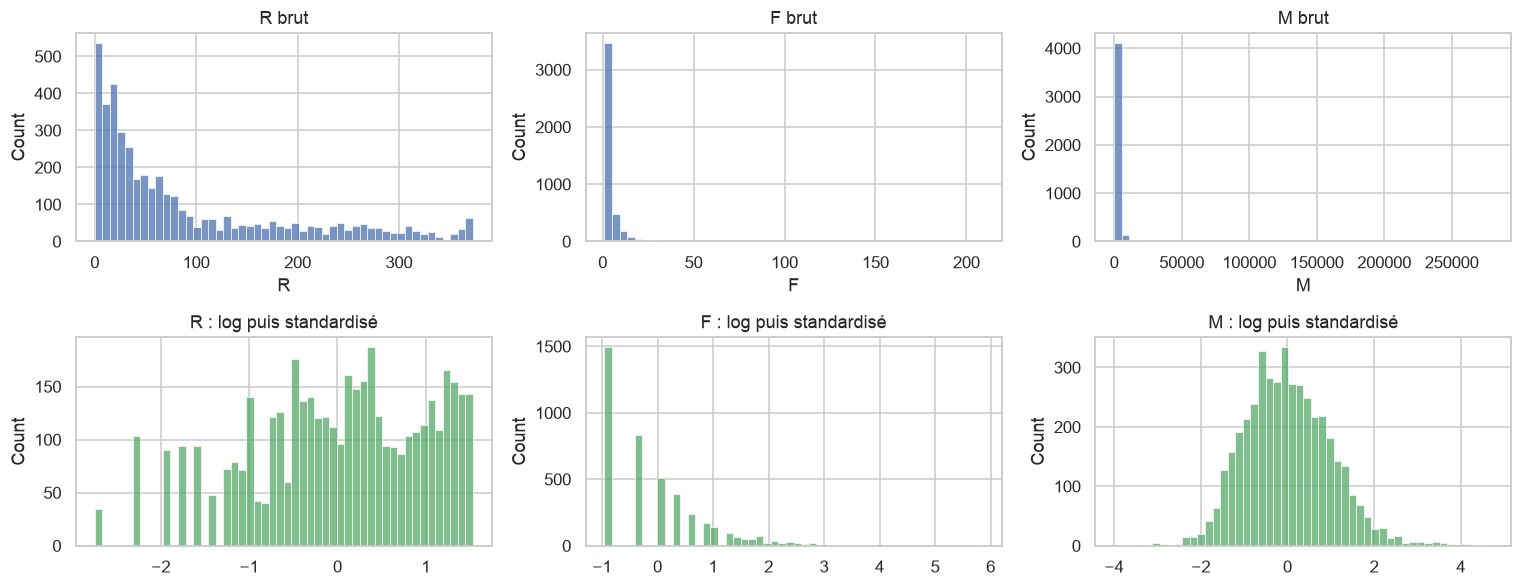

Corrélations (après log) :


,R,F,M
R,1.00,-0.57,-0.49
F,-0.57,1.00,0.81
M,-0.49,0.81,1.00


In [103]:
Z = StandardScaler().fit_transform(np.log1p(rfm))      # log(1 + x) puis z = (x - μ) / σ
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for j, c in enumerate(["R", "F", "M"]):
    sns.histplot(rfm[c], bins=50, ax=axes[0, j], color="#4C72B0"); axes[0, j].set_title(f"{c} brut")
    sns.histplot(Z[:, j], bins=50, ax=axes[1, j], color="#55A868"); axes[1, j].set_title(f"{c} : log puis standardisé")
plt.tight_layout(); plt.savefig(FIG / "08_rfm_distributions.png", bbox_inches="tight"); plt.show()
print("Corrélations (après log) :")
np.log1p(rfm).corr().round(2)

**Lecture.** F et M ont des queues très longues (un client totalise 280 000 £ et 209 factures). Sans transformation, ces quelques clients domineraient les distances, comme l'âge non standardisé dans le jeu bancaire. On applique donc **log(1 + x)** puis la standardisation. F et M restent fortement corrélées (0,7 après log) : c'est attendu, plus on achète souvent, plus on dépense.

# Partie B — Clustering (Jours 2 et 3)
Avec 4 338 clients, la matrice des distances tient en mémoire : toutes les méthodes sont appliquées à **l'ensemble des clients**, sans échantillon.

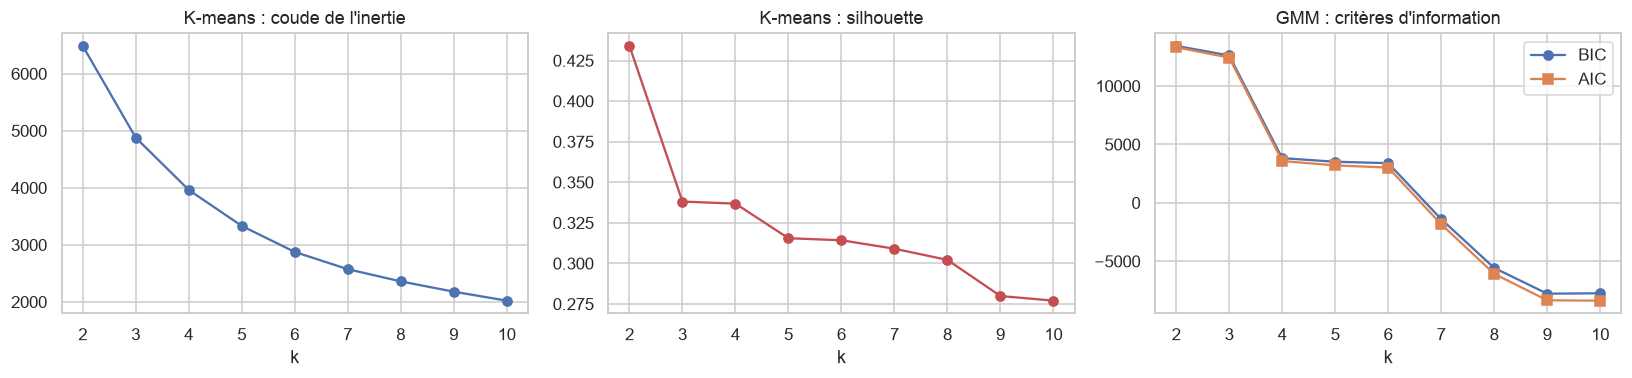

,k,inertie K-means,silhouette K-means,BIC GMM,AIC GMM
0,2,6488.007,0.434,13436.625,13315.497
1,3,4879.134,0.338,12611.880,12427.000
2,4,3962.703,0.337,3825.825,3577.193
3,5,3331.858,0.316,3516.278,3203.895
4,6,2875.401,0.314,3395.506,3019.371
5,7,2573.177,0.309,-1394.343,-1834.229
6,8,2359.569,0.302,-5572.372,-6076.010
7,9,2178.465,0.280,-7776.132,-8343.522
8,10,2021.274,0.277,-7743.312,-8374.454


In [104]:
D = pairwise_distances(Z)
rows, parts = [], {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=SEED).fit(Z)
    parts[f"kmeans_k{k}"] = km.labels_
    parts[f"gmm_k{k}"] = gmm.predict(Z)
    parts[f"ward_k{k}"] = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    rows.append({"k": k, "inertie K-means": km.inertia_, "silhouette K-means": silhouette_score(Z, km.labels_),
                 "BIC GMM": gmm.bic(Z), "AIC GMM": gmm.aic(Z)})
for k in range(2, 7):
    parts[f"kmedoids_k{k}"] = kmedoids(D, k)[0]
curves = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(curves["k"], curves["inertie K-means"], "o-"); axes[0].set_title("K-means : coude de l'inertie")
axes[1].plot(curves["k"], curves["silhouette K-means"], "o-", color="#C44E52"); axes[1].set_title("K-means : silhouette")
axes[2].plot(curves["k"], curves["BIC GMM"], "o-", label="BIC"); axes[2].plot(curves["k"], curves["AIC GMM"], "s-", label="AIC")
axes[2].set_title("GMM : critères d'information"); axes[2].legend()
for ax in axes: ax.set_xlabel("k"); ax.set_xticks(range(2, 11))
plt.tight_layout(); plt.savefig(FIG / "08_choix_k.png", bbox_inches="tight"); plt.show()
curves.round(3)

In [105]:
# DBSCAN : epsilon au coude du graphique des k-distances
MIN_SAMPLES = 8                                    # 2 × dimension + 2, règle usuelle
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
EPS = float(kdist[knee_point(kdist)])
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
parts["dbscan"] = db
print(f"ε = {EPS:.3f} ; {db.max() + 1} clusters ; bruit : {100 * (db == -1).mean():.1f} % ; tailles : {np.bincount(db[db >= 0])}")

ε = 0.398 ; 3 clusters ; bruit : 3.8 % ; tailles : [1881 1467  824]


**Lecture.** La silhouette de K-means est maximale à k = 2 (0,43), puis se stabilise autour de 0,34 pour k = 3 et 4 avant de baisser lentement. L'inertie n'a pas de cassure franche ; le BIC du GMM chute nettement entre 3 et 4 composantes. Comme pour le jeu bancaire, le choix final tiendra compte de la stabilité et du besoin métier.

# Partie C — Validation (Jour 4)
## C.1 Indices internes et indices externes
**Référence externe** : la segmentation RFM « classique ». Chaque client reçoit une note de 1 à 5 par quintile de R, F et M, puis une règle métier usuelle le range parmi cinq groupes (Champions, Fidèles, Nouveaux ou prometteurs, À risque, Perdus).

In [106]:
quint = lambda s, asc: pd.qcut(s.rank(method="first", ascending=asc), 5, labels=[1, 2, 3, 4, 5]).astype(int)
scores = pd.DataFrame({"r": quint(rfm["R"], False), "f": quint(rfm["F"], True), "m": quint(rfm["M"], True)}, index=rfm.index)
def classic_segment(s):
    if s.r >= 4 and s.f >= 4: return "Champions"
    if s.r >= 3 and s.f >= 3: return "Fidèles"
    if s.r >= 4:              return "Nouveaux ou prometteurs"
    if s.f >= 3:              return "À risque"
    return "Perdus"
ref_seg = scores.apply(classic_segment, axis=1)
print(ref_seg.value_counts().to_string())

NAMES = {"kmeans": "K-means", "kmedoids": "K-medoids", "gmm": "GMM", "ward": "CAH Ward", "dbscan": "DBSCAN"}
rows = []
for name, lab in parts.items():
    key, _, k = name.rpartition("_k")
    method = NAMES[key] if key else NAMES[name]
    m = lab >= 0
    if method != "DBSCAN" and int(k) > 6:
        continue
    h, c, v = homogeneity_completeness_v_measure(ref_seg[m], lab[m])
    rows.append({"méthode": method, "nb clusters": len(np.unique(lab[m])),
                 "plus petit cluster (%)": 100 * np.bincount(lab[m]).min() / len(lab),
                 "silhouette": silhouette_score(Z[m], lab[m]), "Davies-Bouldin": davies_bouldin_score(Z[m], lab[m]),
                 "Dunn": dunn_index(D[np.ix_(m, m)], lab[m]),
                 "ARI (réf. RFM)": adjusted_rand_score(ref_seg[m], lab[m]), "NMI (réf. RFM)": normalized_mutual_info_score(ref_seg[m], lab[m]),
                 "V-mesure (réf. RFM)": v})
indices = pd.DataFrame(rows)
indices.to_csv(TAB / "08_indices.csv", index=False)
indices.style.format(precision=3).format({"plus petit cluster (%)": "{:.1f}"}).hide(axis="index")

Perdus                     1427
Champions                  1121
Fidèles                     824
À risque                    658
Nouveaux ou prometteurs     308


méthode,nb clusters,plus petit cluster (%),silhouette,Davies-Bouldin,Dunn,ARI (réf. RFM),NMI (réf. RFM),V-mesure (réf. RFM)
K-means,2,38.1,0.434049,0.892035,0.002416,0.319990,0.366114,0.366114
GMM,2,34.4,0.284876,1.062946,0.058262,0.318540,0.452032,0.452032
CAH Ward,2,46.3,0.393288,0.946859,0.005598,0.353511,0.374520,0.374520
K-means,3,17.2,0.338098,1.048305,0.003535,0.364097,0.395820,0.395820
GMM,3,22.3,0.254168,1.243207,0.006675,0.418131,0.484281,0.484281
CAH Ward,3,13.4,0.320569,1.095399,0.007094,0.333517,0.405157,0.405157
K-means,4,16.1,0.336833,1.012974,0.000918,0.426748,0.449643,0.449643
GMM,4,19.2,0.175130,1.704715,0.008827,0.469797,0.504142,0.504142
CAH Ward,4,12.6,0.297396,1.002216,0.007094,0.340489,0.407865,0.407865
K-means,5,6.7,0.315517,0.995377,0.000834,0.410485,0.471538,0.471538


**Lecture.**
- **Indices internes** : K-means domine à chaque k (silhouette 0,43 à k = 2, puis 0,34 à k = 3 et 4). Ward et K-medoids suivent de près ; le GMM et DBSCAN sont nettement en retrait en silhouette. L'indice de Dunn est presque nul pour toutes les méthodes : les clients forment un **continuum** sans frontières nettes, comme dans le jeu bancaire.
- **Indices externes** : l'accord avec la segmentation RFM classique est modéré (ARI de 0,3 à 0,5). C'est normal : la règle par quintiles découpe l'espace par seuils fixes, alors que le clustering suit la densité réelle des clients. K-means à k = 4 a le meilleur accord des solutions K-means (0,43) ; le GMM s'en approche davantage (jusqu'à 0,47), mais avec des silhouettes faibles.

## C.2 Stabilité (bootstrap, 20 rééchantillons)

In [107]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(Z), len(Z)) for _ in range(20)]
stab = []
for k in range(2, 7):
    for name, fit in [("K-means", lambda X: KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)),
                      ("CAH Ward", lambda X: AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X))]:
        refp = parts[f"{'kmeans' if name == 'K-means' else 'ward'}_k{k}"]
        a = [adjusted_rand_score(refp[ib], fit(Z[ib])) for ib in boot_idx]
        stab.append({"k": k, "méthode": name, "ARI moyen": np.mean(a), "écart-type": np.std(a)})
stab = pd.DataFrame(stab)
stab.to_csv(TAB / "08_stabilite.csv", index=False)
stab.pivot(index="k", columns="méthode", values="ARI moyen").round(3)

méthode,CAH Ward,K-means
k,,
2,0.451,0.977
3,0.454,0.940
4,0.419,0.906
5,0.410,0.820
6,0.494,0.826


**Lecture.** K-means est **très stable** (0,98 à k = 2, 0,94 à k = 3, 0,91 à k = 4), alors que Ward est **instable** à tous les k (environ 0,45). C'est l'inverse du jeu bancaire, où Ward l'emportait. Avec trois variables continues et des groupes de forme ronde, K-means est dans son domaine. Les fusions de Ward, elles, dépendent fortement des quelques clients extrêmes présents ou non dans le rééchantillon. **Aucune méthode n'est la meilleure en général** : le choix doit être refait sur chaque jeu de données.

## C.3 Choix de la solution
Même démarche que pour le jeu bancaire. Le classement se fait sur les **indices internes** et la **stabilité** ; l'accord avec la segmentation RFM classique ne sert que de contrôle.

In [108]:
FINAL_K = 4
final = parts[f"kmeans_k{FINAL_K}"]
row = indices[(indices["méthode"] == "K-means") & (indices["nb clusters"] == FINAL_K)].iloc[0]
s_row = stab[(stab["méthode"] == "K-means") & (stab["k"] == FINAL_K)].iloc[0]
print(f"Solution retenue : K-means, k = {FINAL_K}")
print(f"  silhouette {row['silhouette']:.3f} | Davies-Bouldin {row['Davies-Bouldin']:.3f} | stabilité {s_row['ARI moyen']:.3f} "
      f"| ARI avec la segmentation RFM classique {row['ARI (réf. RFM)']:.3f}")

Solution retenue : K-means, k = 4
  silhouette 0.337 | Davies-Bouldin 1.013 | stabilité 0.906 | ARI avec la segmentation RFM classique 0.427


**Justification du choix : K-means, k = 4.**

| Critère | Constat |
|---|---|
| Indices internes | Silhouette de 0,34, égale à celle de k = 3 et seulement en dessous de k = 2 (0,43) ; Davies-Bouldin de 1,01, proche du minimum (0,995 à k = 5). |
| Stabilité | ARI bootstrap de 0,91, contre 0,42 pour Ward au même k. |
| Métier | k = 2 se contente d'opposer bons et mauvais clients ; k = 4 distingue les nouveaux clients des clients réguliers, qui n'appellent pas la même action. |
| Contrôle externe | Meilleur accord avec la segmentation RFM classique parmi les solutions K-means (ARI 0,43). Le GMM fait un peu mieux (0,47), mais avec une silhouette deux fois plus faible. |

# Partie D — Interprétation (Jour 5)

In [109]:
prof = rfm.assign(segment=final).groupby("segment").agg(
    clients=("R", "size"), R_médiane=("R", "median"), F_médiane=("F", "median"), M_médiane=("M", "median"),
    CA_total=("M", "sum"))
prof["% des clients"] = 100 * prof["clients"] / prof["clients"].sum()
prof["% du chiffre d'affaires"] = 100 * prof["CA_total"] / prof["CA_total"].sum()
# Nommage automatique d'après les profils
order = prof.sort_values("M_médiane", ascending=False).index
names = {}
for s in prof.index:
    p = prof.loc[s]
    if s == order[0]:                                   names[s] = "Champions"
    elif p["R_médiane"] > 100:                          names[s] = "Perdus"
    elif p["F_médiane"] <= 2 and p["R_médiane"] < 30:   names[s] = "Nouveaux clients"
    else:                                               names[s] = "Réguliers"
prof.insert(0, "nom", prof.index.map(names))
prof = prof.sort_values("% du chiffre d'affaires", ascending=False)
prof.drop(columns="CA_total").round(1).to_csv(TAB / "08_profils_segments.csv")
prof.drop(columns="CA_total").round(1)

,nom,clients,R_médiane,F_médiane,M_médiane,% des clients,% du chiffre d'affaires
segment,,,,,,,
0,Champions,699,8.0,10.0,3750.4,16.1,64.5
3,Réguliers,1178,53.5,4.0,1351.8,27.2,24.1
1,Perdus,1635,173.0,1.0,296.6,37.7,6.3
2,Nouveaux clients,826,16.0,2.0,480.1,19.0,5.2


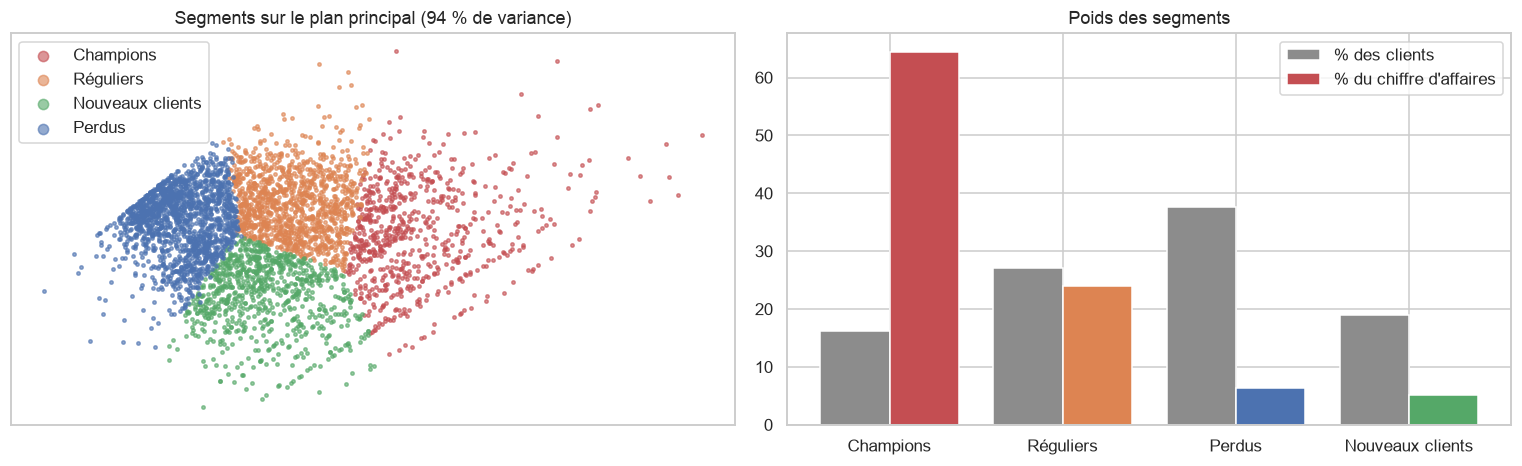

segment RFM classique,Champions,Fidèles,Nouveaux ou prometteurs,Perdus,À risque
segment K-means,,,,,
Champions,661,33,0,0,5
Nouveaux clients,175,317,288,46,0
Perdus,0,49,11,1285,290
Réguliers,285,425,9,96,363


In [110]:
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P2 = pca.transform(Z)
pal = {"Champions": "#C44E52", "Réguliers": "#DD8452", "Nouveaux clients": "#55A868", "Perdus": "#4C72B0"}
seg_name = pd.Series(final).map(names).values
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for nm, c in pal.items():
    m = seg_name == nm
    axes[0].scatter(P2[m, 0], P2[m, 1], s=5, c=c, label=nm, alpha=.6)
axes[0].set_title(f"Segments sur le plan principal ({100 * pca.explained_variance_ratio_.sum():.0f} % de variance)")
axes[0].legend(markerscale=3); axes[0].set_xticks([]); axes[0].set_yticks([])
x = np.arange(len(prof))
axes[1].bar(x - 0.2, prof["% des clients"], 0.4, label="% des clients", color="#8C8C8C")
axes[1].bar(x + 0.2, prof["% du chiffre d'affaires"], 0.4, label="% du chiffre d'affaires", color=[pal[n] for n in prof["nom"]])
axes[1].set_xticks(x); axes[1].set_xticklabels(prof["nom"]); axes[1].legend(); axes[1].set_title("Poids des segments")
plt.tight_layout(); plt.savefig(FIG / "08_segments.png", bbox_inches="tight"); plt.show()
pd.crosstab(pd.Series(seg_name, name="segment K-means"), pd.Series(ref_seg.values, name="segment RFM classique"))

**Profils et recommandations.**

| Segment | Profil | Recommandation |
|---|---|---|
| **Champions** (16 % des clients, **65 % du CA**) | Achat très récent (8 jours), 10 factures, 3 750 £ en médiane | Programme de fidélité, accès en avant-première, interlocuteur dédié : c'est le segment à ne pas perdre. |
| **Réguliers** (27 %, 24 % du CA) | Dernier achat il y a 2 mois, 4 factures | Relances ciblées et ventes croisées pour les faire monter vers les Champions. |
| **Nouveaux clients** (19 %, 5 % du CA) | Achat récent (16 jours) mais 1 à 2 factures | Parcours d'accueil, offre sur la deuxième commande : transformer l'essai. |
| **Perdus** (38 %, 6 % du CA) | Aucun achat depuis près de 6 mois, une seule facture | Campagne de reconquête peu coûteuse (courriel automatisé) ; ne pas y consacrer de budget important. |

Un client sur six génère deux tiers du chiffre d'affaires. La même logique que pour la banque s'applique : concentrer l'effort commercial là où la réponse est la plus forte.

## Bilan de la reproduction
1. La démarche du projet (préparation, choix des distances, comparaison de 5 méthodes, validation interne, externe et stabilité, interprétation) **s'applique telle quelle** à un second jeu de données.
2. Les mêmes leçons se retrouvent : il faut transformer les variables asymétriques, un indice ne se lit pas seul, et la structure est un continuum (Dunn presque nul).
3. Une différence instructive : la **méthode gagnante change**. Ward est la plus stable sur les données bancaires mixtes ; K-means l'est sur les trois variables RFM continues.
4. Solution retenue : **K-means à 4 segments** (silhouette 0,34 ; stabilité 0,91). Les **Champions** (16 % des clients) font 65 % du chiffre d'affaires.